In [136]:

# ============================================================
# STEP 1 — LOAD AND PREPARE MONTHLY SPENDING DATA
# ============================================================

# Prevent Windows MKL KMeans memory leak warning
import os

os.environ["OMP_NUM_THREADS"] = "1"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Load cleaned dataset
DATA_PATH = Path(
    "../data/processed/cleaned_household_transactions.csv"
)

df = pd.read_csv(DATA_PATH)

df["Date"] = pd.to_datetime(
    df["Date"], errors="coerce"
)

df["Amount"] = pd.to_numeric(
    df["Amount"], errors="coerce"
)

print("Original dataset shape:", df.shape)

# ------------------------------------------------------------
# 1. SELECT HOUSEHOLD CONSUMPTION EXPENSES
# ------------------------------------------------------------

expense_df = df[
    df["Income/Expense"] == "Expense"
].copy()

financial_categories_strict = [
    "Money transfer",
    "Investment",
    "Public Provident Fund",
    "Recurring Deposit"
]

excluded_notes = [
    "Public Provident Fund",
    "Permanent Residence money transfer"
]

household_df = expense_df[
    (~expense_df["Category"].isin(
        financial_categories_strict
    )) &
    (~expense_df["Note"].isin(excluded_notes))
].copy()

household_df = household_df.dropna(
    subset=["Date", "Amount", "Category"]
)

print("Household consumption transactions:", len(household_df))

# ------------------------------------------------------------
# 2. CREATE MONTHLY CATEGORY SPENDING
# ------------------------------------------------------------

household_df["Month"] = (
    household_df["Date"].dt.to_period("M")
)

monthly_category_spending = (
    household_df.pivot_table(
        index="Month",
        columns="Category",
        values="Amount",
        aggfunc="sum",
        fill_value=0
    )
)

# Include every month in the dataset period
all_months = pd.period_range(
    start=household_df["Month"].min(),
    end=household_df["Month"].max(),
    freq="M"
)

monthly_category_spending = (
    monthly_category_spending
    .reindex(all_months, fill_value=0)
)

# ------------------------------------------------------------
# 3. CREATE ADDITIONAL MONTHLY FEATURES
# ------------------------------------------------------------

monthly_summary = household_df.groupby("Month").agg(
    Total_Spending=("Amount", "sum"),
    Transaction_Count=("Amount", "count"),
    Average_Transaction=("Amount", "mean")
)

monthly_summary = monthly_summary.reindex(
    all_months,
    fill_value=0
)

monthly_summary["Weekend_Ratio"] = (
    household_df.assign(
        Is_Weekend=household_df["Date"].dt.dayofweek >= 5
    )
    .groupby("Month")["Is_Weekend"]
    .mean()
    .reindex(all_months)
    .fillna(0)
)

# ------------------------------------------------------------
# 4. COMBINE MONTHLY FEATURES
# ------------------------------------------------------------

monthly_features = pd.concat(
    [monthly_summary, monthly_category_spending],
    axis=1
)

monthly_features.index.name = "Month"

print("\nMonthly feature dataset shape:", monthly_features.shape)

print("\nMonthly feature preview:")
display(monthly_features.head())

print("\nMissing values:")
print(monthly_features.isnull().sum().sum())

print("\nNumber of months:", len(monthly_features))


Original dataset shape: (2452, 9)
Household consumption transactions: 1996

Monthly feature dataset shape: (48, 27)

Monthly feature preview:


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio,Apparel,Beauty,Cook,Culture,Documents,Education,...,Other,Rent,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription,water (jar /tanker)
Month,,,,,,,,,,,,,,,,,,,,,
2015-01,15144.0,67,226.029851,0.194030,1021.0,60.0,776.0,40.0,0.0,0.0,...,500.0,5376.0,0.0,0.0,0.0,1824.0,0.0,333.0,0.0,0.0
2015-02,18919.0,48,394.145833,0.312500,345.0,0.0,5000.0,0.0,0.0,0.0,...,4930.0,5333.0,0.0,0.0,0.0,781.0,0.0,0.0,0.0,0.0
2015-03,19253.8,41,469.604878,0.268293,170.0,0.0,6667.0,0.0,0.0,0.0,...,828.0,0.0,0.0,0.0,0.0,50.0,17.0,666.0,0.0,148.0
2015-04,4806.0,20,240.300000,0.450000,0.0,0.0,0.0,0.0,0.0,0.0,...,1039.0,0.0,0.0,0.0,0.0,0.0,50.0,0.0,0.0,0.0
2015-05,17603.0,22,800.136364,0.409091,0.0,40.0,0.0,0.0,0.0,0.0,...,7673.0,0.0,0.0,0.0,0.0,6000.0,0.0,0.0,0.0,0.0



Missing values:
0

Number of months: 48


In [137]:

# ============================================================
# STEP 2 — CREATE WEEKLY SPENDING FEATURES
# ============================================================

# Work on a separate copy to preserve existing monthly data
weekly_source_df = household_df.copy()

# ------------------------------------------------------------
# 1. CREATE WEEKLY PERIODS (MONDAY TO SUNDAY)
# ------------------------------------------------------------

weekly_source_df["Week"] = (
    weekly_source_df["Date"].dt.to_period("W-SUN")
)

# Create complete weekly timeline
all_weeks = pd.period_range(
    start=weekly_source_df["Week"].min(),
    end=weekly_source_df["Week"].max(),
    freq="W-SUN"
)

# ------------------------------------------------------------
# 2. CREATE WEEKLY CATEGORY SPENDING
# ------------------------------------------------------------

weekly_category_spending = (
    weekly_source_df.pivot_table(
        index="Week",
        columns="Category",
        values="Amount",
        aggfunc="sum",
        fill_value=0
    )
)

weekly_category_spending = (
    weekly_category_spending
    .reindex(all_weeks, fill_value=0)
)

# ------------------------------------------------------------
# 3. CREATE ADDITIONAL WEEKLY FEATURES
# ------------------------------------------------------------

weekly_summary = weekly_source_df.groupby("Week").agg(
    Total_Spending=("Amount", "sum"),
    Transaction_Count=("Amount", "count"),
    Average_Transaction=("Amount", "mean")
)

weekly_summary = weekly_summary.reindex(
    all_weeks,
    fill_value=0
)

# Percentage of transactions occurring on weekends
weekly_summary["Weekend_Ratio"] = (
    weekly_source_df.assign(
        Is_Weekend=(
            weekly_source_df["Date"].dt.dayofweek >= 5
        )
    )
    .groupby("Week")["Is_Weekend"]
    .mean()
    .reindex(all_weeks)
    .fillna(0)
)

# ------------------------------------------------------------
# 4. COMBINE WEEKLY FEATURES
# ------------------------------------------------------------

weekly_features = pd.concat(
    [weekly_summary, weekly_category_spending],
    axis=1
)

weekly_features.index.name = "Week"

# ------------------------------------------------------------
# 5. SEPARATE ACTIVE WEEKS FOR CLUSTERING
# ------------------------------------------------------------

weekly_clustering_features = weekly_features.loc[
    weekly_features["Transaction_Count"] > 0
].copy()

# ------------------------------------------------------------
# 6. CHECK RESULTS
# ------------------------------------------------------------

print("Weekly feature dataset shape:", weekly_features.shape)

print(
    "Weekly clustering dataset shape:",
    weekly_clustering_features.shape
)

print("\nWeekly feature preview:")
display(weekly_features.head())

print("\nTotal calendar weeks:", len(weekly_features))

print(
    "Weeks with transactions:",
    len(weekly_clustering_features)
)

print(
    "Weeks without transactions:",
    (weekly_features["Transaction_Count"] == 0).sum()
)

print(
    "\nMissing values:",
    weekly_features.isnull().sum().sum()
)


Weekly feature dataset shape: (206, 27)
Weekly clustering dataset shape: (193, 27)

Weekly feature preview:


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio,Apparel,Beauty,Cook,Culture,Documents,Education,...,Other,Rent,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription,water (jar /tanker)
Week,,,,,,,,,,,,,,,,,,,,,
2014-12-29/2015-01-04,2254.0,19,118.631579,0.263158,248.0,0.0,0.0,40.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,302.0,0.0,0.0,0.0,0.0
2015-01-05/2015-01-11,6575.0,6,1095.833333,0.166667,0.0,0.0,776.0,0.0,0.0,0.0,...,0.0,5376.0,0.0,0.0,0.0,70.0,0.0,333.0,0.0,0.0
2015-01-12/2015-01-18,3736.0,17,219.764706,0.176471,773.0,0.0,0.0,0.0,0.0,0.0,...,500.0,0.0,0.0,0.0,0.0,950.0,0.0,0.0,0.0,0.0
2015-01-19/2015-01-25,924.0,13,71.076923,0.153846,0.0,60.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,402.0,0.0,0.0,0.0,0.0
2015-01-26/2015-02-01,1759.0,15,117.266667,0.333333,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0



Total calendar weeks: 206
Weeks with transactions: 193
Weeks without transactions: 13

Missing values: 0



WEEKLY FEATURE ANALYSIS

Zero-variance features:
[]

Feature diagnostics:


,Variance,Skewness,Potential_Outliers
Total_Spending,6.660767e+07,3.854812,17
Transportation,2.321747e+07,9.230585,38
Tourism,1.160511e+07,11.354885,5
Household,7.941345e+06,5.772897,38
subscription,5.631141e+06,9.157288,24
Health,3.634851e+06,11.046119,39
Family,1.322334e+06,4.173750,42
Gift,8.428781e+05,6.232920,26
Other,6.725402e+05,4.041301,31
Average_Transaction,4.071682e+05,3.681644,16



Highly correlated feature pairs (|r| >= 0.85):


,,Correlation


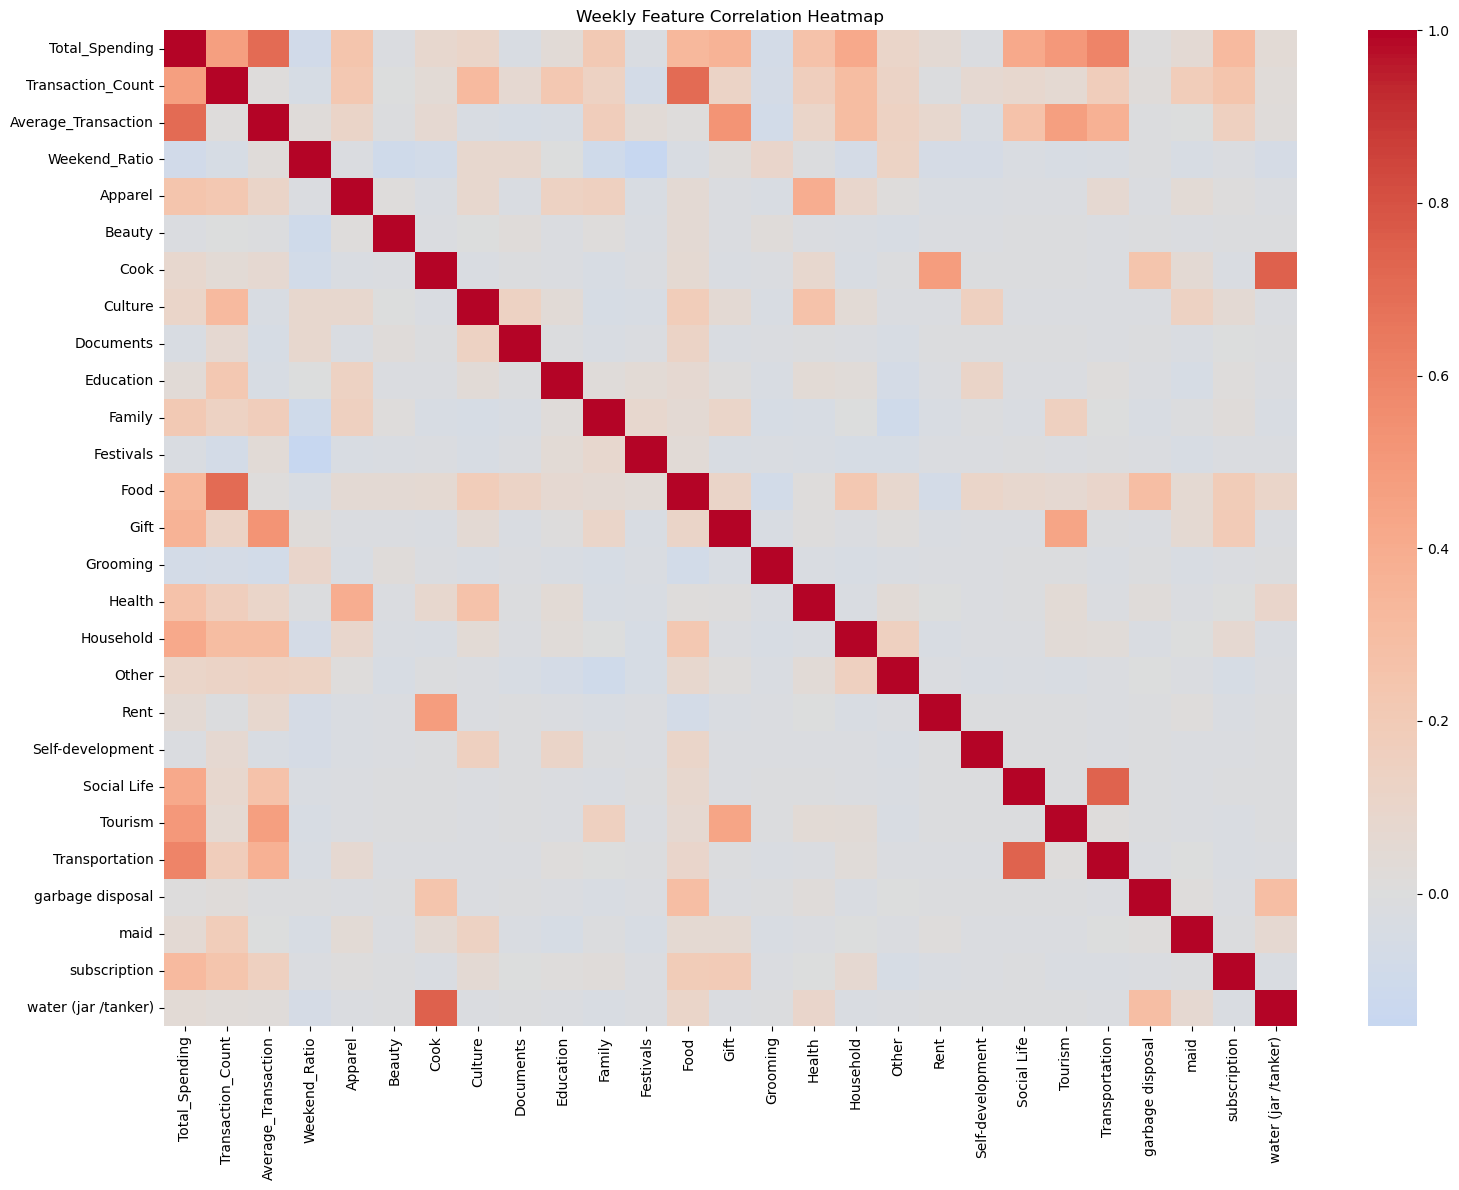


MONTHLY FEATURE ANALYSIS

Zero-variance features:
[]

Feature diagnostics:


,Variance,Skewness,Potential_Outliers
Total_Spending,4.726871e+08,2.273919,6
Transportation,1.873074e+08,6.718747,2
Tourism,4.661047e+07,5.606738,3
Household,3.483399e+07,2.257563,5
subscription,2.866449e+07,4.087234,6
Health,1.506854e+07,5.264315,8
Family,6.066939e+06,1.981369,5
Gift,3.902328e+06,2.904938,7
Other,3.181517e+06,1.982801,6
Food,2.300857e+06,0.537468,0



Highly correlated feature pairs (|r| >= 0.85):


,,Correlation
Social Life,Transportation,0.990068


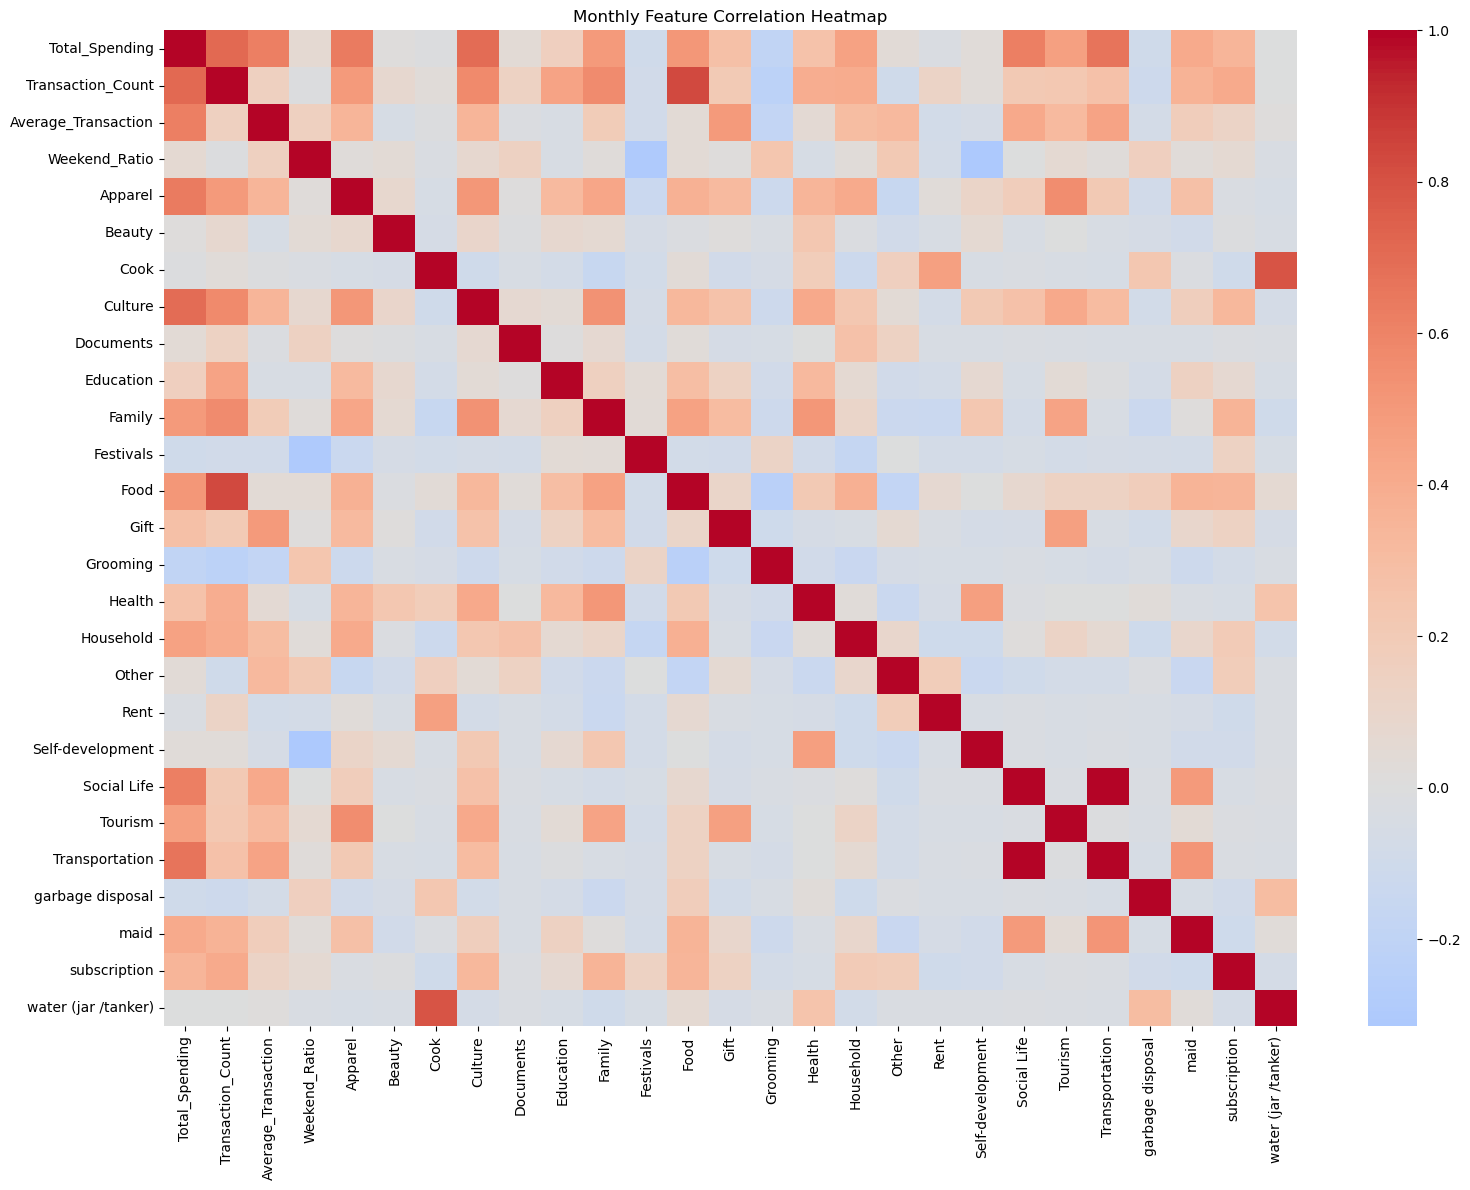

In [138]:

# ============================================================
# STEP 3 — FEATURE QUALITY ANALYSIS
# ============================================================

def analyze_features(features, dataset_name):

    print("\n" + "=" * 65)
    print(f"{dataset_name.upper()} FEATURE ANALYSIS")
    print("=" * 65)

    # 1. Feature variance and skewness
    variance = features.var()
    skewness = features.skew()

    # 2. Detect zero-variance features
    zero_variance = variance[variance == 0]

    print("\nZero-variance features:")
    print(zero_variance.index.tolist())

    # 3. Detect potential outliers using IQR
    outlier_counts = {}

    for column in features.columns:

        Q1 = features[column].quantile(0.25)
        Q3 = features[column].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outlier_counts[column] = (
            (features[column] < lower_bound) |
            (features[column] > upper_bound)
        ).sum()

    # 4. Combine feature diagnostics
    feature_diagnostics = pd.DataFrame({
        "Variance": variance,
        "Skewness": skewness,
        "Potential_Outliers": pd.Series(outlier_counts)
    })

    print("\nFeature diagnostics:")
    display(
        feature_diagnostics.sort_values(
            "Variance",
            ascending=False
        )
    )

    # 5. Identify highly correlated feature pairs
    correlation_matrix = features.corr()

    upper_triangle = correlation_matrix.where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )

    high_correlations = (
        upper_triangle
        .stack()
        .sort_values(ascending=False)
    )

    print("\nHighly correlated feature pairs (|r| >= 0.85):")

    display(
        high_correlations[
            high_correlations.abs() >= 0.85
        ].rename("Correlation").to_frame()
    )

    # 6. Correlation heatmap
    plt.figure(figsize=(16, 12))

    sns.heatmap(
        correlation_matrix,
        cmap="coolwarm",
        center=0,
        annot=False
    )

    plt.title(f"{dataset_name} Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()


# Analyze active weekly observations
analyze_features(
    weekly_clustering_features,
    "Weekly"
)

# Analyze monthly observations
analyze_features(
    monthly_features,
    "Monthly"
)


In [139]:

# ============================================================
# STEP 4 — FEATURE PREPARATION AND LOG TRANSFORMATION
# ============================================================

# Features used for clustering
# Total_Spending is excluded because category spending
# already represents the total expenditure.

weekly_model_features = (
    weekly_clustering_features
    .drop(columns=["Total_Spending"])
    .copy()
)

monthly_model_features = (
    monthly_features
    .drop(columns=["Total_Spending"])
    .copy()
)


# ------------------------------------------------------------
# 1. IDENTIFY FEATURES FOR LOG TRANSFORMATION
# ------------------------------------------------------------

log_columns_weekly = [
    col for col in weekly_model_features.columns
    if col != "Weekend_Ratio"
]

log_columns_monthly = [
    col for col in monthly_model_features.columns
    if col != "Weekend_Ratio"
]


# ------------------------------------------------------------
# 2. CHECK NON-NEGATIVE VALUES
# ------------------------------------------------------------

assert (weekly_model_features[log_columns_weekly] >= 0).all().all()

assert (monthly_model_features[log_columns_monthly] >= 0).all().all()


# ------------------------------------------------------------
# 3. APPLY LOG1P TRANSFORMATION
# ------------------------------------------------------------

weekly_transformed = weekly_model_features.copy()

monthly_transformed = monthly_model_features.copy()

weekly_transformed[log_columns_weekly] = np.log1p(
    weekly_model_features[log_columns_weekly]
)

monthly_transformed[log_columns_monthly] = np.log1p(
    monthly_model_features[log_columns_monthly]
)


# ------------------------------------------------------------
# 4. COMPARE SKEWNESS BEFORE AND AFTER
# ------------------------------------------------------------

weekly_skew_comparison = pd.DataFrame({
    "Before_Log": weekly_model_features.skew(),
    "After_Log": weekly_transformed.skew()
})

monthly_skew_comparison = pd.DataFrame({
    "Before_Log": monthly_model_features.skew(),
    "After_Log": monthly_transformed.skew()
})


print("WEEKLY SKEWNESS COMPARISON")

display(
    weekly_skew_comparison.sort_values(
        "Before_Log",
        key=lambda x: x.abs(),
        ascending=False
    )
)

print("\nMONTHLY SKEWNESS COMPARISON")

display(
    monthly_skew_comparison.sort_values(
        "Before_Log",
        key=lambda x: x.abs(),
        ascending=False
    )
)


# ------------------------------------------------------------
# 5. FINAL DATASET CHECK
# ------------------------------------------------------------

print("\nWEEKLY TRANSFORMED DATASET:", weekly_transformed.shape)

print("MONTHLY TRANSFORMED DATASET:", monthly_transformed.shape)

print(
    "\nWeekly missing values:",
    weekly_transformed.isnull().sum().sum()
)

print(
    "Monthly missing values:",
    monthly_transformed.isnull().sum().sum()
)

print("\nWeekly preview:")
display(weekly_transformed.head())

print("\nMonthly preview:")
display(monthly_transformed.head())


WEEKLY SKEWNESS COMPARISON


,Before_Log,After_Log
Social Life,13.892444,13.892444
Beauty,12.334967,2.920137
garbage disposal,12.227705,10.083515
water (jar /tanker),12.008374,9.945355
Tourism,11.354885,7.064671
Health,11.046119,1.198844
Self-development,10.277279,9.757647
Cook,9.922056,8.057072
Rent,9.746235,9.745995
Documents,9.745991,9.745991



MONTHLY SKEWNESS COMPARISON


,Before_Log,After_Log
Social Life,6.928203,6.928203
water (jar /tanker),6.928203,6.928203
Transportation,6.718747,-0.795691
garbage disposal,6.057298,4.917440
Beauty,6.030301,0.847368
Tourism,5.606738,4.066748
Health,5.264315,-0.313347
Self-development,5.021077,4.742890
Cook,4.832241,3.821998
Rent,4.736771,4.736643



WEEKLY TRANSFORMED DATASET: (193, 26)
MONTHLY TRANSFORMED DATASET: (48, 26)

Weekly missing values: 0
Monthly missing values: 0

Weekly preview:


,Transaction_Count,Average_Transaction,Weekend_Ratio,Apparel,Beauty,Cook,Culture,Documents,Education,Family,...,Other,Rent,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription,water (jar /tanker)
Week,,,,,,,,,,,,,,,,,,,,,
2014-12-29/2015-01-04,2.995732,4.784417,0.263158,5.517453,0.000000,0.00000,3.713572,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.0,0.0,5.713733,0.0,0.000000,0.0,0.0
2015-01-05/2015-01-11,1.945910,7.000183,0.166667,0.000000,0.000000,6.65544,0.000000,0.0,0.0,0.0,...,0.000000,8.589886,0.0,0.0,0.0,4.262680,0.0,5.811141,0.0,0.0
2015-01-12/2015-01-18,2.890372,5.397097,0.176471,6.651572,0.000000,0.00000,0.000000,0.0,0.0,0.0,...,6.216606,0.000000,0.0,0.0,0.0,6.857514,0.0,0.000000,0.0,0.0
2015-01-19/2015-01-25,2.639057,4.277734,0.153846,0.000000,4.110874,0.00000,0.000000,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.0,0.0,5.998937,0.0,0.000000,0.0,0.0
2015-01-26/2015-02-01,2.772589,4.772942,0.333333,0.000000,0.000000,0.00000,0.000000,0.0,0.0,0.0,...,0.000000,0.000000,0.0,0.0,0.0,4.615121,0.0,0.000000,0.0,0.0



Monthly preview:


,Transaction_Count,Average_Transaction,Weekend_Ratio,Apparel,Beauty,Cook,Culture,Documents,Education,Family,...,Other,Rent,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription,water (jar /tanker)
Month,,,,,,,,,,,,,,,,,,,,,
2015-01,4.219508,5.425082,0.194030,6.929517,4.110874,6.655440,3.713572,0.0,0.0,0.0,...,6.216606,8.589886,0.0,0.0,0.0,7.509335,0.000000,5.811141,0.0,0.000000
2015-02,3.891820,5.979255,0.312500,5.846439,0.000000,8.517393,0.000000,0.0,0.0,0.0,...,8.503297,8.581857,0.0,0.0,0.0,6.661855,0.000000,0.000000,0.0,0.000000
2015-03,3.737670,6.154019,0.268293,5.141664,0.000000,8.805075,0.000000,0.0,0.0,0.0,...,6.720220,0.000000,0.0,0.0,0.0,3.931826,2.890372,6.502790,0.0,5.003946
2015-04,3.044522,5.486041,0.450000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,...,6.946976,0.000000,0.0,0.0,0.0,0.000000,3.931826,0.000000,0.0,0.000000
2015-05,3.135494,6.686031,0.409091,0.000000,3.713572,0.000000,0.000000,0.0,0.0,0.0,...,8.945593,0.000000,0.0,0.0,0.0,8.699681,0.000000,0.000000,0.0,0.000000


In [140]:

# ============================================================
# STEP 5 — FEATURE SCALING USING STANDARD SCALER
# ============================================================

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. CREATE SEPARATE SCALERS
# ------------------------------------------------------------

weekly_scaler = StandardScaler()
monthly_scaler = StandardScaler()


# ------------------------------------------------------------
# 2. SCALE WEEKLY FEATURES
# ------------------------------------------------------------

weekly_scaled_array = weekly_scaler.fit_transform(
    weekly_transformed
)

weekly_scaled = pd.DataFrame(
    weekly_scaled_array,
    index=weekly_transformed.index,
    columns=weekly_transformed.columns
)


# ------------------------------------------------------------
# 3. SCALE MONTHLY FEATURES
# ------------------------------------------------------------

monthly_scaled_array = monthly_scaler.fit_transform(
    monthly_transformed
)

monthly_scaled = pd.DataFrame(
    monthly_scaled_array,
    index=monthly_transformed.index,
    columns=monthly_transformed.columns
)


# ------------------------------------------------------------
# 4. VERIFY SCALING
# ------------------------------------------------------------

print("WEEKLY SCALED DATASET")
print("Shape:", weekly_scaled.shape)

print("\nWeekly feature means:")
display(weekly_scaled.mean().round(4))

print("\nWeekly feature standard deviations:")
display(weekly_scaled.std(ddof=0).round(4))


print("\nMONTHLY SCALED DATASET")
print("Shape:", monthly_scaled.shape)

print("\nMonthly feature means:")
display(monthly_scaled.mean().round(4))

print("\nMonthly feature standard deviations:")
display(monthly_scaled.std(ddof=0).round(4))


# ------------------------------------------------------------
# 5. CHECK MISSING VALUES
# ------------------------------------------------------------

print("\nWeekly missing values:", weekly_scaled.isnull().sum().sum())

print("Monthly missing values:", monthly_scaled.isnull().sum().sum())


WEEKLY SCALED DATASET
Shape: (193, 26)

Weekly feature means:


Transaction_Count      0.0
Average_Transaction    0.0
Weekend_Ratio          0.0
Apparel                0.0
Beauty                -0.0
Cook                   0.0
Culture                0.0
Documents              0.0
Education             -0.0
Family                -0.0
Festivals             -0.0
Food                  -0.0
Gift                  -0.0
Grooming               0.0
Health                -0.0
Household              0.0
Other                  0.0
Rent                  -0.0
Self-development      -0.0
Social Life            0.0
Tourism                0.0
Transportation         0.0
garbage disposal       0.0
maid                   0.0
subscription           0.0
water (jar /tanker)   -0.0
dtype: float64


Weekly feature standard deviations:


Transaction_Count      1.0
Average_Transaction    1.0
Weekend_Ratio          1.0
Apparel                1.0
Beauty                 1.0
Cook                   1.0
Culture                1.0
Documents              1.0
Education              1.0
Family                 1.0
Festivals              1.0
Food                   1.0
Gift                   1.0
Grooming               1.0
Health                 1.0
Household              1.0
Other                  1.0
Rent                   1.0
Self-development       1.0
Social Life            1.0
Tourism                1.0
Transportation         1.0
garbage disposal       1.0
maid                   1.0
subscription           1.0
water (jar /tanker)    1.0
dtype: float64


MONTHLY SCALED DATASET
Shape: (48, 26)

Monthly feature means:


Transaction_Count      0.0
Average_Transaction    0.0
Weekend_Ratio         -0.0
Apparel                0.0
Beauty                 0.0
Cook                   0.0
Culture               -0.0
Documents             -0.0
Education              0.0
Family                -0.0
Festivals             -0.0
Food                   0.0
Gift                   0.0
Grooming               0.0
Health                 0.0
Household              0.0
Other                  0.0
Rent                  -0.0
Self-development      -0.0
Social Life           -0.0
Tourism                0.0
Transportation         0.0
garbage disposal       0.0
maid                   0.0
subscription          -0.0
water (jar /tanker)   -0.0
dtype: float64


Monthly feature standard deviations:


Transaction_Count      1.0
Average_Transaction    1.0
Weekend_Ratio          1.0
Apparel                1.0
Beauty                 1.0
Cook                   1.0
Culture                1.0
Documents              1.0
Education              1.0
Family                 1.0
Festivals              1.0
Food                   1.0
Gift                   1.0
Grooming               1.0
Health                 1.0
Household              1.0
Other                  1.0
Rent                   1.0
Self-development       1.0
Social Life            1.0
Tourism                1.0
Transportation         1.0
garbage disposal       1.0
maid                   1.0
subscription           1.0
water (jar /tanker)    1.0
dtype: float64


Weekly missing values: 0
Monthly missing values: 0



Evaluating Weekly dataset...


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


Weekly K Evaluation Results:


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,K,Inertia,Silhouette_Score
0,2,4554.7359,0.1160
1,3,4147.4915,0.1206
2,4,4034.2686,0.1097
3,5,3739.6395,0.1329
4,6,3571.9406,0.1529
5,7,3395.2537,0.1037
6,8,3217.8620,0.0837
7,9,2991.3949,0.1211
8,10,2899.2328,0.1012


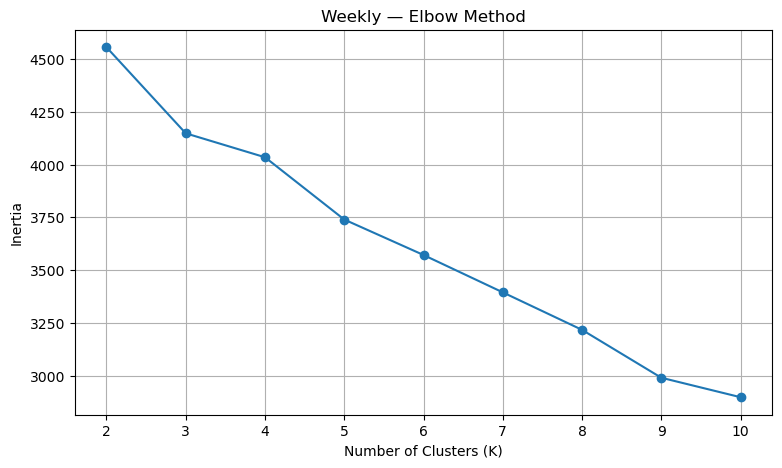

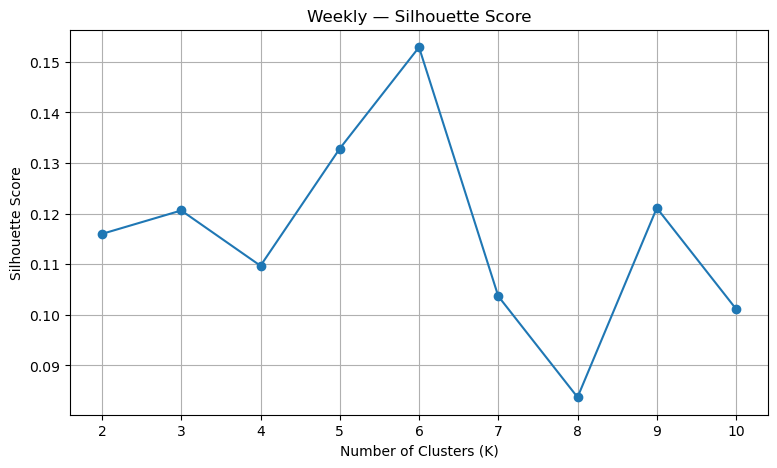


Evaluating Monthly dataset...


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


Monthly K Evaluation Results:


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,K,Inertia,Silhouette_Score
0,2,1008.9418,0.1721
1,3,882.7783,0.1910
2,4,814.8977,0.2025
3,5,767.3423,0.1818
4,6,699.5754,0.1919
5,7,658.2698,0.1170
6,8,611.5925,0.0817


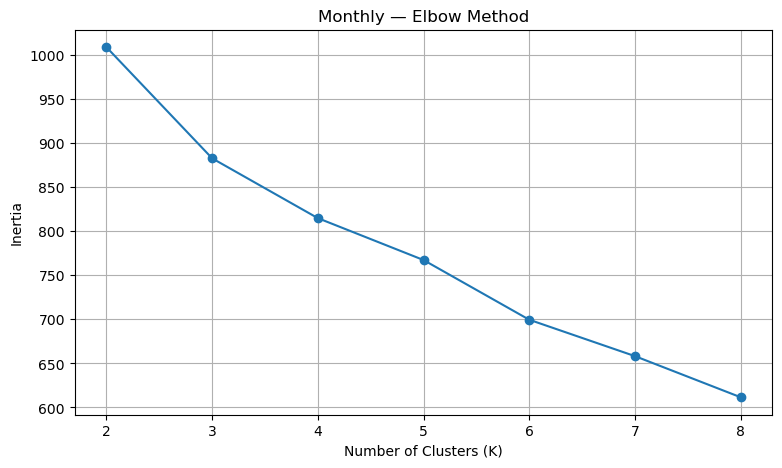

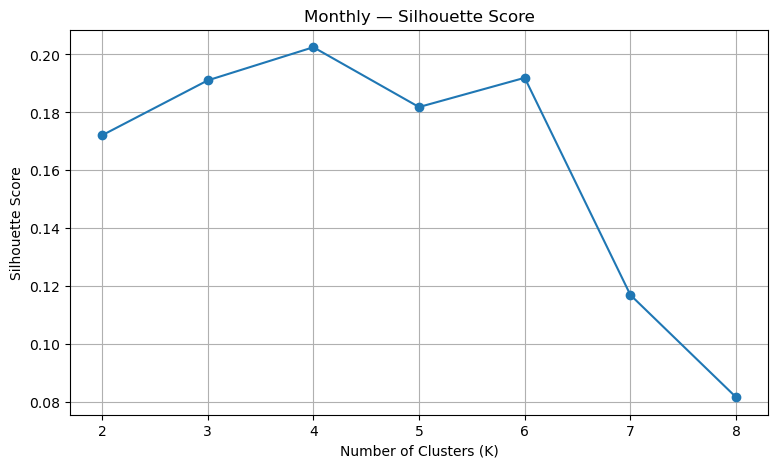

In [141]:

# ============================================================
# STEP 6 — FIND OPTIMAL NUMBER OF CLUSTERS (K)
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ------------------------------------------------------------
# 1. DEFINE K VALUES
# ------------------------------------------------------------

weekly_k_values = range(2, 11)

monthly_k_values = range(2, 9)


# ------------------------------------------------------------
# 2. CREATE FUNCTION FOR K EVALUATION
# ------------------------------------------------------------

def evaluate_k_values(scaled_data, k_values, dataset_name):

    inertia_scores = []
    silhouette_scores = []

    print(f"\nEvaluating {dataset_name} dataset...")

    for k in k_values:

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = kmeans.fit_predict(scaled_data)

        inertia_scores.append(kmeans.inertia_)

        silhouette_scores.append(
            silhouette_score(scaled_data, labels)
        )

    results = pd.DataFrame({
        "K": list(k_values),
        "Inertia": inertia_scores,
        "Silhouette_Score": silhouette_scores
    })

    print(f"\n{dataset_name} K Evaluation Results:")
    display(results.round(4))

    # --------------------------------------------------------
    # 3. PLOT ELBOW METHOD
    # --------------------------------------------------------

    plt.figure(figsize=(9, 5))

    plt.plot(
        results["K"],
        results["Inertia"],
        marker="o"
    )

    plt.title(f"{dataset_name} — Elbow Method")
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Inertia")
    plt.xticks(results["K"])
    plt.grid(True)
    plt.show()

    # --------------------------------------------------------
    # 4. PLOT SILHOUETTE SCORES
    # --------------------------------------------------------

    plt.figure(figsize=(9, 5))

    plt.plot(
        results["K"],
        results["Silhouette_Score"],
        marker="o"
    )

    plt.title(f"{dataset_name} — Silhouette Score")
    plt.xlabel("Number of Clusters (K)")
    plt.ylabel("Silhouette Score")
    plt.xticks(results["K"])
    plt.grid(True)
    plt.show()

    return results


# ------------------------------------------------------------
# 5. WEEKLY K EVALUATION
# ------------------------------------------------------------

weekly_k_results = evaluate_k_values(
    weekly_scaled,
    weekly_k_values,
    "Weekly"
)


# ------------------------------------------------------------
# 6. MONTHLY K EVALUATION
# ------------------------------------------------------------

monthly_k_results = evaluate_k_values(
    monthly_scaled,
    monthly_k_values,
    "Monthly"
)


In [142]:

# ============================================================
# STEP 7 — TRAIN AND COMPARE CANDIDATE K-MEANS MODELS
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Candidate K values based on Step 6 results
weekly_candidate_k = [5, 6]
monthly_candidate_k = [3, 4]


# ------------------------------------------------------------
# 1. FUNCTION TO TRAIN AND EVALUATE CANDIDATES
# ------------------------------------------------------------

def compare_candidate_models(
    scaled_data,
    candidate_values,
    dataset_name
):

    candidate_models = {}
    candidate_labels = {}
    candidate_results = []

    print(f"\n{dataset_name.upper()} CANDIDATE MODELS")

    for k in candidate_values:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        labels = model.fit_predict(scaled_data)

        candidate_models[k] = model
        candidate_labels[k] = labels

        sizes = pd.Series(labels).value_counts().sort_index()

        candidate_results.append({
            "K": k,
            "Inertia": model.inertia_,
            "Silhouette_Score": silhouette_score(
                scaled_data,
                labels
            ),
            "Smallest_Cluster": sizes.min(),
            "Largest_Cluster": sizes.max(),
            "Number_of_Clusters": sizes.size
        })

        print(f"\nCluster distribution for K={k}:")
        display(
            sizes.rename("Observation_Count").to_frame()
        )

    results = pd.DataFrame(candidate_results)

    print(f"\n{dataset_name} candidate comparison:")
    display(results.round(4))

    return candidate_models, candidate_labels, results


# ------------------------------------------------------------
# 2. WEEKLY CANDIDATE MODELS
# ------------------------------------------------------------

weekly_candidate_models, weekly_candidate_labels, weekly_candidate_results = (
    compare_candidate_models(
        weekly_scaled,
        weekly_candidate_k,
        "Weekly"
    )
)


# ------------------------------------------------------------
# 3. MONTHLY CANDIDATE MODELS
# ------------------------------------------------------------

monthly_candidate_models, monthly_candidate_labels, monthly_candidate_results = (
    compare_candidate_models(
        monthly_scaled,
        monthly_candidate_k,
        "Monthly"
    )
)



WEEKLY CANDIDATE MODELS

Cluster distribution for K=5:


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Observation_Count
0,97
1,91
2,1
3,2
4,2


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



Cluster distribution for K=6:


,Observation_Count
0,95
1,74
2,1
3,17
4,2
5,4


... (6 outputs left out)


Cluster distribution for K=4:


,Observation_Count
0,2
1,22
2,23
3,1



Monthly candidate comparison:


,K,Inertia,Silhouette_Score,Smallest_Cluster,Largest_Cluster,Number_of_Clusters
0,3,882.7783,0.1910,3,23,3
1,4,814.8977,0.2025,1,23,4


In [143]:

# ============================================================
# STEP 8 — CLUSTER PROFILING AND INTERPRETATION
# ============================================================

def profile_clusters(
    original_features,
    candidate_labels,
    candidate_k_values,
    dataset_name
):

    # Identify category spending columns
    non_category_columns = [
        "Total_Spending",
        "Transaction_Count",
        "Average_Transaction",
        "Weekend_Ratio"
    ]

    category_columns = [
        col for col in original_features.columns
        if col not in non_category_columns
    ]

    all_profiles = {}

    for k in candidate_k_values:

        print("\n" + "=" * 65)
        print(f"{dataset_name.upper()} CLUSTER PROFILE — K={k}")
        print("=" * 65)

        # Preserve original time index
        profile_data = original_features.copy()

        profile_data["Cluster"] = candidate_labels[k]

        # ----------------------------------------------------
        # 1. GENERAL CLUSTER STATISTICS
        # ----------------------------------------------------

        summary = profile_data.groupby("Cluster").agg(
            Observation_Count=("Total_Spending", "count"),
            Average_Spending=("Total_Spending", "mean"),
            Median_Spending=("Total_Spending", "median"),
            Average_Transactions=("Transaction_Count", "mean"),
            Average_Transaction_Amount=(
                "Average_Transaction", "mean"
            ),
            Average_Weekend_Ratio=("Weekend_Ratio", "mean")
        )

        summary["Percentage"] = (
            summary["Observation_Count"] /
            len(profile_data) * 100
        )

        print("\nGeneral cluster statistics:")

        display(summary.round(2))

        # ----------------------------------------------------
        # 2. TOP THREE SPENDING CATEGORIES PER CLUSTER
        # ----------------------------------------------------

        category_profile = (
            profile_data
            .groupby("Cluster")[category_columns]
            .mean()
        )

        top_categories = {}

        for cluster in category_profile.index:

            top_three = (
                category_profile.loc[cluster]
                .sort_values(ascending=False)
                .head(3)
            )

            top_categories[cluster] = [
                f"{category}: ₹{amount:,.2f}"
                for category, amount in top_three.items()
            ]

        top_category_table = pd.DataFrame.from_dict(
            top_categories,
            orient="index",
            columns=[
                "Top_Category_1",
                "Top_Category_2",
                "Top_Category_3"
            ]
        )

        print("\nTop spending categories per cluster:")

        display(top_category_table)

        # ----------------------------------------------------
        # 3. SAVE PROFILES
        # ----------------------------------------------------

        all_profiles[k] = {
            "summary": summary,
            "category_profile": category_profile,
            "top_categories": top_category_table,
            "assignments": profile_data
        }

    return all_profiles


# ------------------------------------------------------------
# 4. WEEKLY CLUSTER PROFILES
# ------------------------------------------------------------

weekly_cluster_profiles = profile_clusters(
    original_features=weekly_clustering_features,
    candidate_labels=weekly_candidate_labels,
    candidate_k_values=[5, 6],
    dataset_name="Weekly"
)


# ------------------------------------------------------------
# 5. MONTHLY CLUSTER PROFILES
# ------------------------------------------------------------

monthly_cluster_profiles = profile_clusters(
    original_features=monthly_features,
    candidate_labels=monthly_candidate_labels,
    candidate_k_values=[3, 4],
    dataset_name="Monthly"
)



WEEKLY CLUSTER PROFILE — K=5

General cluster statistics:


,Observation_Count,Average_Spending,Median_Spending,Average_Transactions,Average_Transaction_Amount,Average_Weekend_Ratio,Percentage
Cluster,,,,,,,
0,97,1362.67,759.0,4.53,391.59,0.32,50.26
1,91,8462.71,4834.0,16.41,532.56,0.30,47.15
2,1,12082.00,12082.0,15.00,805.47,0.07,0.52
3,2,2345.50,2345.5,15.00,154.67,0.53,1.04
4,2,8967.50,8967.5,9.50,984.84,0.16,1.04



Top spending categories per cluster:


,Top_Category_1,Top_Category_2,Top_Category_3
0,Other: ₹292.74,Food: ₹238.24,subscription: ₹222.47
1,"Transportation: ₹1,747.11","Household: ₹1,685.23","subscription: ₹1,011.16"
2,"Cook: ₹6,667.00","Health: ₹3,082.00","Food: ₹1,392.00"
3,"Food: ₹1,180.50",subscription: ₹496.00,Household: ₹269.00
4,"Rent: ₹5,354.50","Cook: ₹2,888.00",Health: ₹263.00



WEEKLY CLUSTER PROFILE — K=6

General cluster statistics:


,Observation_Count,Average_Spending,Median_Spending,Average_Transactions,Average_Transaction_Amount,Average_Weekend_Ratio,Percentage
Cluster,,,,,,,
0,95,1422.57,789.0,4.74,397.27,0.32,49.22
1,74,9437.30,5091.9,16.95,582.37,0.30,38.34
2,1,12082.00,12082.0,15.00,805.47,0.07,0.52
3,17,4127.58,2883.0,13.53,320.83,0.28,8.81
4,2,8967.50,8967.5,9.50,984.84,0.16,1.04
5,4,826.00,849.5,7.00,116.36,0.52,2.07


... (6 outputs left out)


MONTHLY CLUSTER PROFILE — K=4

General cluster statistics:


,Observation_Count,Average_Spending,Median_Spending,Average_Transactions,Average_Transaction_Amount,Average_Weekend_Ratio,Percentage
Cluster,,,,,,,
0,2,17031.50,17031.50,57.50,310.09,0.25,4.17
1,22,5220.98,4335.00,15.82,381.35,0.30,45.83
2,23,33426.75,22691.68,64.87,500.78,0.31,47.92
3,1,19253.80,19253.80,41.00,469.60,0.27,2.08



Top spending categories per cluster:


,Top_Category_1,Top_Category_2,Top_Category_3
0,"Rent: ₹5,354.50","Cook: ₹2,888.00","Other: ₹2,715.00"
1,"Other: ₹1,268.72",Food: ₹758.91,subscription: ₹659.18
2,"Transportation: ₹6,640.01","Household: ₹6,540.89","subscription: ₹4,351.56"
3,"Health: ₹8,051.00","Cook: ₹6,667.00","Food: ₹2,606.80"


In [144]:

# ============================================================
# STEP 9 — INVESTIGATE SMALL CLUSTERS
# ============================================================

def investigate_small_clusters(
    cluster_profiles,
    candidate_k_values,
    dataset_name,
    minimum_size=5
):

    print("\n" + "=" * 65)
    print(f"{dataset_name.upper()} — SMALL CLUSTER INVESTIGATION")
    print("=" * 65)

    for k in candidate_k_values:

        profile_data = cluster_profiles[k]["assignments"]

        cluster_sizes = profile_data["Cluster"].value_counts()

        small_cluster_ids = cluster_sizes[
            cluster_sizes <= minimum_size
        ].index

        print(f"\n{dataset_name} K={k}")
        print("-" * 50)

        for cluster_id in small_cluster_ids:

            small_cluster_data = profile_data[
                profile_data["Cluster"] == cluster_id
            ]

            print(
                f"\nCluster {cluster_id} | "
                f"Observations: {len(small_cluster_data)}"
            )

            display(
                small_cluster_data[
                    [
                        "Total_Spending",
                        "Transaction_Count",
                        "Average_Transaction",
                        "Weekend_Ratio"
                    ]
                ].round(2)
            )


# ------------------------------------------------------------
# 1. INVESTIGATE WEEKLY SMALL CLUSTERS
# ------------------------------------------------------------

investigate_small_clusters(
    weekly_cluster_profiles,
    [5, 6],
    "Weekly"
)


# ------------------------------------------------------------
# 2. INVESTIGATE MONTHLY SMALL CLUSTERS
# ------------------------------------------------------------

investigate_small_clusters(
    monthly_cluster_profiles,
    [3, 4],
    "Monthly"
)



WEEKLY — SMALL CLUSTER INVESTIGATION

Weekly K=5
--------------------------------------------------

Cluster 4 | Observations: 2


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
Week,,,,
2015-01-05/2015-01-11,6575.0,6,1095.83,0.17
2015-02-02/2015-02-08,11360.0,13,873.85,0.15



Cluster 3 | Observations: 2


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
Week,,,,
2018-03-26/2018-04-01,2883.0,16,180.19,0.56
2018-05-28/2018-06-03,1808.0,14,129.14,0.50



Cluster 2 | Observations: 1


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
Week,,,,
2015-03-02/2015-03-08,12082.0,15,805.47,0.07


... (8 outputs left out)


Monthly K=4
--------------------------------------------------

Cluster 0 | Observations: 2


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
Month,,,,
2015-01,15144.0,67,226.03,0.19
2015-02,18919.0,48,394.15,0.31



Cluster 3 | Observations: 1


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
Month,,,,
2015-03,19253.8,41,469.6,0.27


In [145]:

# ============================================================
# STEP 10 — FINAL WEEKLY K COMPARISON
# ============================================================

weekly_final_candidates = [3, 4, 5, 6]

weekly_final_models = {}
weekly_final_labels = {}

weekly_final_results = []

for k in weekly_final_candidates:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(weekly_scaled)

    weekly_final_models[k] = model
    weekly_final_labels[k] = labels

    cluster_sizes = pd.Series(labels).value_counts()

    weekly_final_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette_score(
            weekly_scaled,
            labels
        ),
        "Smallest_Cluster": cluster_sizes.min(),
        "Largest_Cluster": cluster_sizes.max(),
        "Clusters_With_Fewer_Than_5_Weeks": (
            cluster_sizes < 5
        ).sum()
    })

    print(f"\nWeekly K={k} cluster distribution:")

    display(
        cluster_sizes.sort_index().rename(
            "Observation_Count"
        ).to_frame()
    )


# ------------------------------------------------------------
# COMPARE ALL CANDIDATE MODELS
# ------------------------------------------------------------

weekly_final_comparison = pd.DataFrame(
    weekly_final_results
)

print("\nFINAL WEEKLY CANDIDATE COMPARISON:")

display(weekly_final_comparison.round(4))



Weekly K=3 cluster distribution:


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Observation_Count
0,94
1,96
2,3


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



Weekly K=4 cluster distribution:


,Observation_Count
0,78
1,12
2,101
3,2


... (4 outputs left out)

c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Observation_Count
0,95
1,74
2,1
3,17
4,2
5,4



FINAL WEEKLY CANDIDATE COMPARISON:


,K,Inertia,Silhouette_Score,Smallest_Cluster,Largest_Cluster,Clusters_With_Fewer_Than_5_Weeks
0,3,4147.4915,0.1206,3,96,1
1,4,4034.2686,0.1097,2,101,1
2,5,3739.6395,0.1329,1,97,3
3,6,3571.9406,0.1529,1,95,3


In [146]:

# ============================================================
# STEP 11 — TRAIN FINAL WEEKLY AND MONTHLY MODELS
# ============================================================

# ------------------------------------------------------------
# 1. FINAL MODEL CONFIGURATION
# ------------------------------------------------------------

FINAL_WEEKLY_K = 3
FINAL_MONTHLY_K = 3


# ------------------------------------------------------------
# 2. TRAIN WEEKLY K-MEANS
# ------------------------------------------------------------

weekly_final_model = KMeans(
    n_clusters=FINAL_WEEKLY_K,
    random_state=42,
    n_init=20
)

weekly_final_cluster_labels = (
    weekly_final_model.fit_predict(weekly_scaled)
)


# ------------------------------------------------------------
# 3. TRAIN MONTHLY K-MEANS
# ------------------------------------------------------------

monthly_final_model = KMeans(
    n_clusters=FINAL_MONTHLY_K,
    random_state=42,
    n_init=20
)

monthly_final_cluster_labels = (
    monthly_final_model.fit_predict(monthly_scaled)
)


# ------------------------------------------------------------
# 4. CREATE FINAL CLUSTER ASSIGNMENTS
# ------------------------------------------------------------

weekly_final_results = weekly_clustering_features.copy()

weekly_final_results["Cluster"] = (
    weekly_final_cluster_labels
)


monthly_final_results = monthly_features.copy()

monthly_final_results["Cluster"] = (
    monthly_final_cluster_labels
)


# ------------------------------------------------------------
# 5. VERIFY CLUSTER DISTRIBUTIONS
# ------------------------------------------------------------

print("FINAL WEEKLY CLUSTER DISTRIBUTION")

display(
    weekly_final_results["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Observation_Count")
    .to_frame()
)


print("\nFINAL MONTHLY CLUSTER DISTRIBUTION")

display(
    monthly_final_results["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Observation_Count")
    .to_frame()
)


# ------------------------------------------------------------
# 6. FINAL MODEL EVALUATION
# ------------------------------------------------------------

print("\nWEEKLY SILHOUETTE SCORE:")

print(
    round(
        silhouette_score(
            weekly_scaled,
            weekly_final_cluster_labels
        ),
        4
    )
)


print("\nMONTHLY SILHOUETTE SCORE:")

print(
    round(
        silhouette_score(
            monthly_scaled,
            monthly_final_cluster_labels
        ),
        4
    )
)


print("\nWeekly model trained successfully.")

print("Monthly model trained successfully.")


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


FINAL WEEKLY CLUSTER DISTRIBUTION


,Observation_Count
Cluster,
0,94
1,96
2,3



FINAL MONTHLY CLUSTER DISTRIBUTION


,Observation_Count
Cluster,
0,23
1,22
2,3



WEEKLY SILHOUETTE SCORE:
0.1206

MONTHLY SILHOUETTE SCORE:
0.191

Weekly model trained successfully.
Monthly model trained successfully.



WEEKLY FEATURE AUDIT

1. Category contribution:


,Total_Spending,Spending_Percentage,Active_Periods,Zero_Percentage
Transportation,169053.78,18.04,110,43.01
Household,161645.58,17.25,81,58.03
subscription,114587.91,12.23,88,54.40
Food,96393.10,10.29,160,17.10
Family,78582.20,8.39,57,70.47
Health,66252.75,7.07,60,68.91
Tourism,63608.85,6.79,5,97.41
Other,57025.28,6.09,77,60.10
Gift,40168.00,4.29,26,86.53
Apparel,25373.82,2.71,37,80.83



2. Correlation with Total Spending:


,Correlation_With_Total_Spending
Transportation,0.598
Tourism,0.504
Social Life,0.420
Household,0.418
Gift,0.365
Food,0.335
subscription,0.319
Health,0.262
Apparel,0.251
Family,0.213



3. General spending statistics:


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
count,193.00,193.00,193.00,193.00
mean,4854.89,10.34,463.89,0.31
std,8161.35,7.52,638.10,0.28
min,33.00,1.00,23.50,0.00
25%,759.00,4.00,138.20,0.08
50%,2328.00,9.00,253.75,0.27
75%,4977.00,15.00,514.33,0.50
max,55597.00,48.00,4633.08,1.00


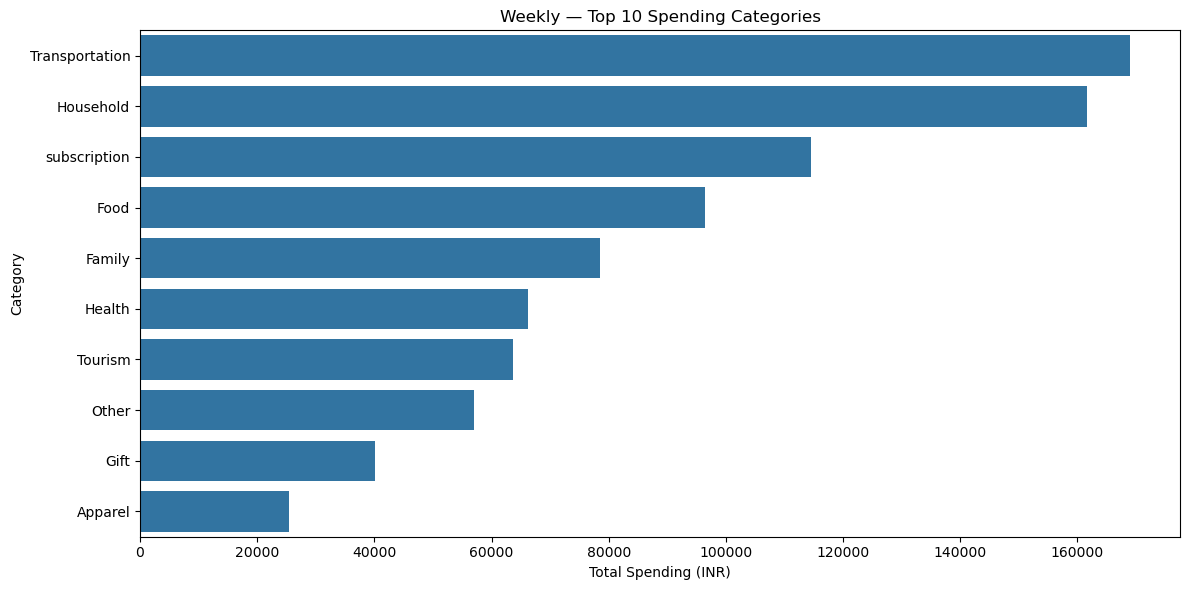


MONTHLY FEATURE AUDIT

1. Category contribution:


,Total_Spending,Spending_Percentage,Active_Periods,Zero_Percentage
Transportation,169053.78,18.04,40,16.67
Household,161645.58,17.25,34,29.17
subscription,114587.91,12.23,34,29.17
Food,96393.10,10.29,48,0.00
Family,78582.20,8.39,31,35.42
Health,66252.75,7.07,34,29.17
Tourism,63608.85,6.79,3,93.75
Other,57025.28,6.09,39,18.75
Gift,40168.00,4.29,20,58.33
Apparel,25373.82,2.71,23,52.08



2. Correlation with Total Spending:


,Correlation_With_Total_Spending
Culture,0.693
Transportation,0.667
Apparel,0.639
Social Life,0.618
Food,0.515
Family,0.500
Tourism,0.463
Household,0.457
maid,0.413
subscription,0.350



3. General spending statistics:


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
count,48.00,48.00,48.00,48.00
mean,19520.70,41.58,437.45,0.30
std,21741.37,26.82,335.02,0.12
min,1343.00,6.00,103.30,0.00
25%,4751.25,16.75,228.44,0.22
50%,14534.20,41.50,313.15,0.31
75%,21244.69,63.50,569.77,0.38
max,110603.58,104.00,1852.50,0.55


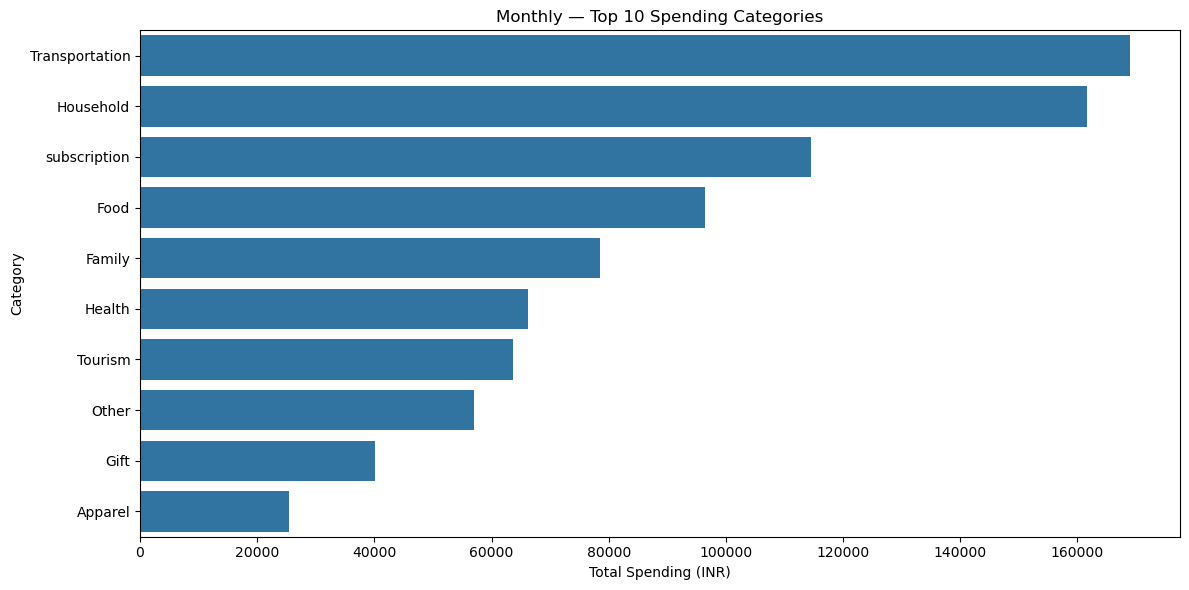

In [147]:

# ============================================================
# STEP 12 — FEATURE AUDIT FOR CLUSTERING IMPROVEMENT
# ============================================================

def feature_audit(features, dataset_name):

    print("\n" + "=" * 70)
    print(f"{dataset_name.upper()} FEATURE AUDIT")
    print("=" * 70)

    category_columns = [
        col for col in features.columns
        if col not in [
            "Total_Spending",
            "Transaction_Count",
            "Average_Transaction",
            "Weekend_Ratio"
        ]
    ]

    # --------------------------------------------------------
    # 1. CATEGORY CONTRIBUTION TO TOTAL EXPENDITURE
    # --------------------------------------------------------

    category_totals = features[category_columns].sum()

    category_contribution = pd.DataFrame({
        "Total_Spending": category_totals,
        "Spending_Percentage": (
            category_totals /
            features["Total_Spending"].sum() * 100
        ),
        "Active_Periods": (
            features[category_columns] > 0
        ).sum(),
        "Zero_Percentage": (
            features[category_columns] == 0
        ).mean() * 100
    })

    category_contribution = (
        category_contribution
        .sort_values("Total_Spending", ascending=False)
    )

    print("\n1. Category contribution:")

    display(category_contribution.round(2))

    # --------------------------------------------------------
    # 2. FEATURE REDUNDANCY
    # --------------------------------------------------------

    print("\n2. Correlation with Total Spending:")

    total_correlations = (
        features[category_columns]
        .corrwith(features["Total_Spending"])
        .sort_values(ascending=False)
    )

    display(
        total_correlations.rename(
            "Correlation_With_Total_Spending"
        ).to_frame().round(3)
    )

    # --------------------------------------------------------
    # 3. GENERAL FEATURE STATISTICS
    # --------------------------------------------------------

    general_features = [
        "Total_Spending",
        "Transaction_Count",
        "Average_Transaction",
        "Weekend_Ratio"
    ]

    print("\n3. General spending statistics:")

    display(
        features[general_features]
        .describe()
        .round(2)
    )

    # --------------------------------------------------------
    # 4. TOP SPENDING CATEGORIES
    # --------------------------------------------------------

    top_categories = category_contribution.head(10)

    plt.figure(figsize=(12, 6))

    sns.barplot(
        x=top_categories["Total_Spending"],
        y=top_categories.index
    )

    plt.title(f"{dataset_name} — Top 10 Spending Categories")
    plt.xlabel("Total Spending (INR)")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

    return category_contribution, total_correlations


# ------------------------------------------------------------
# 5. WEEKLY FEATURE AUDIT
# ------------------------------------------------------------

weekly_feature_audit, weekly_total_correlations = feature_audit(
    weekly_clustering_features,
    "Weekly"
)


# ------------------------------------------------------------
# 6. MONTHLY FEATURE AUDIT
# ------------------------------------------------------------

monthly_feature_audit, monthly_total_correlations = feature_audit(
    monthly_features,
    "Monthly"
)


In [148]:

# ============================================================
# FORESIGHT — EXPERIMENT A
# STEP 13: IMPROVED FEATURE ENGINEERING
# ============================================================

# Objective:
# Compare three different representations of spending behaviour:
# A1 = Spending Intensity
# A2 = Spending Composition
# A3 = Hybrid Features
#
# IMPORTANT:
# Original datasets and K-Means models remain unchanged.


# ============================================================
# 1. IDENTIFY CATEGORY COLUMNS
# ============================================================

general_columns = [
    "Total_Spending",
    "Transaction_Count",
    "Average_Transaction",
    "Weekend_Ratio"
]

weekly_category_columns = [
    col for col in weekly_clustering_features.columns
    if col not in general_columns
]

monthly_category_columns = [
    col for col in monthly_features.columns
    if col not in general_columns
]

# Ensure both datasets use the same category features
if set(weekly_category_columns) != set(monthly_category_columns):
    raise ValueError(
        "Weekly and monthly category columns do not match."
    )

category_columns = sorted(weekly_category_columns)

print("Number of category features:", len(category_columns))
print("Categories:", category_columns)


# ============================================================
# 2. FUNCTION TO CREATE EXPERIMENTAL FEATURE SETS
# ============================================================

def create_experimental_features(data, dataset_name):

    print("\n" + "=" * 70)
    print(f"CREATING EXPERIMENTAL FEATURES: {dataset_name.upper()}")
    print("=" * 70)

    # --------------------------------------------------------
    # A1 — SPENDING INTENSITY
    # --------------------------------------------------------
    # Focus: How much and how frequently do we spend?

    intensity = data[
        [
            "Total_Spending",
            "Transaction_Count",
            "Average_Transaction",
            "Weekend_Ratio"
        ]
    ].copy()

    # Reduce skewness in monetary and frequency features
    intensity_log_columns = [
        "Total_Spending",
        "Transaction_Count",
        "Average_Transaction"
    ]

    intensity[intensity_log_columns] = np.log1p(
        intensity[intensity_log_columns]
    )

    # Weekend_Ratio is already between 0 and 1

    # --------------------------------------------------------
    # A2 — SPENDING COMPOSITION
    # --------------------------------------------------------
    # Focus: Where does the money go?

    category_amounts = data[category_columns].copy()

    total_spending = data["Total_Spending"]

    composition = category_amounts.div(
        total_spending.replace(0, np.nan),
        axis=0
    ).fillna(0)

    # Each row represents the percentage distribution
    # of spending across expense categories.

    # --------------------------------------------------------
    # A3 — HYBRID FEATURES
    # --------------------------------------------------------
    # Focus: How much do we spend AND where do we spend it?

    hybrid = pd.concat(
        [
            intensity[
                [
                    "Total_Spending",
                    "Transaction_Count",
                    "Average_Transaction"
                ]
            ],
            composition,
            intensity[["Weekend_Ratio"]]
        ],
        axis=1
    )

    # --------------------------------------------------------
    # 4. VALIDATE ALL FEATURE SETS
    # --------------------------------------------------------

    feature_sets = {
        "Intensity": intensity,
        "Composition": composition,
        "Hybrid": hybrid
    }

    for name, feature_data in feature_sets.items():

        if not feature_data.index.equals(data.index):
            raise ValueError(
                f"{name} index does not match original data."
            )

        if not np.isfinite(feature_data.to_numpy()).all():
            raise ValueError(
                f"{name} contains missing or infinite values."
            )

        if (feature_data.std() == 0).any():
            raise ValueError(
                f"{name} contains zero-variance features."
            )

    # --------------------------------------------------------
    # 5. DISPLAY EXPERIMENT INFORMATION
    # --------------------------------------------------------

    print("\nFeature Set Comparison:")

    comparison = pd.DataFrame({
        "Experiment": [
            "A1 - Intensity",
            "A2 - Composition",
            "A3 - Hybrid"
        ],
        "Number_of_Features": [
            intensity.shape[1],
            composition.shape[1],
            hybrid.shape[1]
        ],
        "Observations": [
            len(intensity),
            len(composition),
            len(hybrid)
        ],
        "Missing_Values": [
            intensity.isnull().sum().sum(),
            composition.isnull().sum().sum(),
            hybrid.isnull().sum().sum()
        ]
    })

    display(comparison)

    print("\nComposition percentage verification:")

    display(
        composition.sum(axis=1).describe().round(4)
    )

    return intensity, composition, hybrid


# ============================================================
# 6. CREATE WEEKLY EXPERIMENTAL DATASETS
# ============================================================

(
    weekly_intensity_features,
    weekly_composition_features,
    weekly_hybrid_features
) = create_experimental_features(
    weekly_clustering_features,
    "Weekly"
)


# ============================================================
# 7. CREATE MONTHLY EXPERIMENTAL DATASETS
# ============================================================

(
    monthly_intensity_features,
    monthly_composition_features,
    monthly_hybrid_features
) = create_experimental_features(
    monthly_features,
    "Monthly"
)


# ============================================================
# 8. FINAL EXPERIMENTAL DATASET COMPARISON
# ============================================================

experimental_datasets = {
    "Weekly Intensity": weekly_intensity_features,
    "Weekly Composition": weekly_composition_features,
    "Weekly Hybrid": weekly_hybrid_features,

    "Monthly Intensity": monthly_intensity_features,
    "Monthly Composition": monthly_composition_features,
    "Monthly Hybrid": monthly_hybrid_features
}

final_experiment_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Observations": dataset.shape[0],
        "Features": dataset.shape[1],
        "Missing_Values": dataset.isnull().sum().sum(),
        "Minimum_Value": dataset.min().min(),
        "Maximum_Value": dataset.max().max()
    }
    for name, dataset in experimental_datasets.items()
])

print("\n" + "=" * 70)
print("FINAL EXPERIMENT A — DATASET SUMMARY")
print("=" * 70)

display(final_experiment_summary.round(4))

print("\nExperiment A feature engineering completed.")


Number of category features: 23
Categories: ['Apparel', 'Beauty', 'Cook', 'Culture', 'Documents', 'Education', 'Family', 'Festivals', 'Food', 'Gift', 'Grooming', 'Health', 'Household', 'Other', 'Rent', 'Self-development', 'Social Life', 'Tourism', 'Transportation', 'garbage disposal', 'maid', 'subscription', 'water (jar /tanker)']

CREATING EXPERIMENTAL FEATURES: WEEKLY

Feature Set Comparison:


,Experiment,Number_of_Features,Observations,Missing_Values
0,A1 - Intensity,4,193,0
1,A2 - Composition,23,193,0
2,A3 - Hybrid,27,193,0



Composition percentage verification:


count    193.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
dtype: float64


CREATING EXPERIMENTAL FEATURES: MONTHLY

Feature Set Comparison:


,Experiment,Number_of_Features,Observations,Missing_Values
0,A1 - Intensity,4,48,0
1,A2 - Composition,23,48,0
2,A3 - Hybrid,27,48,0



Composition percentage verification:


count    48.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
dtype: float64


FINAL EXPERIMENT A — DATASET SUMMARY


,Dataset,Observations,Features,Missing_Values,Minimum_Value,Maximum_Value
0,Weekly Intensity,193,4,0,0.0,10.9259
1,Weekly Composition,193,23,0,0.0,1.0000
2,Weekly Hybrid,193,27,0,0.0,10.9259
3,Monthly Intensity,48,4,0,0.0,11.6137
4,Monthly Composition,48,23,0,0.0,0.8920
5,Monthly Hybrid,48,27,0,0.0,11.6137



Experiment A feature engineering completed.


In [149]:

# ============================================================
# FORESIGHT — EXPERIMENT A
# STEP 14: SCALING AND CLUSTERING COMPARISON
# ============================================================

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)


# ============================================================
# 1. DEFINE EXPERIMENTAL DATASETS
# ============================================================

weekly_experiments = {
    "Original Baseline": weekly_transformed,
    "A1 - Intensity": weekly_intensity_features,
    "A2 - Composition": weekly_composition_features,
    "A3 - Hybrid": weekly_hybrid_features
}

monthly_experiments = {
    "Original Baseline": monthly_transformed,
    "A1 - Intensity": monthly_intensity_features,
    "A2 - Composition": monthly_composition_features,
    "A3 - Hybrid": monthly_hybrid_features
}


# ============================================================
# 2. DEFINE SCALING METHODS
# ============================================================

scalers = {
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler()
}


# ============================================================
# 3. DEFINE K VALUES
# ============================================================

weekly_k_range = range(2, 9)

monthly_k_range = range(2, 7)


# ============================================================
# 4. FUNCTION TO EVALUATE EXPERIMENTS
# ============================================================

def evaluate_clustering_experiments(
    experiment_datasets,
    dataset_name,
    k_values
):

    results = []
    scaled_datasets = {}
    trained_models = {}

    print("\n" + "=" * 75)
    print(f"{dataset_name.upper()} CLUSTERING EXPERIMENTS")
    print("=" * 75)

    for experiment_name, features in experiment_datasets.items():

        for scaler_name, scaler_template in scalers.items():

            # Create a separate scaler for every experiment
            scaler = type(scaler_template)()

            scaled_array = scaler.fit_transform(features)

            scaled_features = pd.DataFrame(
                scaled_array,
                index=features.index,
                columns=features.columns
            )

            experiment_key = (
                f"{experiment_name} | {scaler_name}"
            )

            scaled_datasets[experiment_key] = {
                "features": scaled_features,
                "scaler": scaler
            }

            for k in k_values:

                model = KMeans(
                    n_clusters=k,
                    random_state=42,
                    n_init=20
                )

                labels = model.fit_predict(scaled_features)

                # Calculate evaluation metrics
                silhouette = silhouette_score(
                    scaled_features,
                    labels
                )

                db_index = davies_bouldin_score(
                    scaled_features,
                    labels
                )

                ch_index = calinski_harabasz_score(
                    scaled_features,
                    labels
                )

                cluster_sizes = pd.Series(labels).value_counts()

                results.append({
                    "Dataset": experiment_name,
                    "Scaler": scaler_name,
                    "K": k,
                    "Silhouette": silhouette,
                    "Davies_Bouldin": db_index,
                    "Calinski_Harabasz": ch_index,
                    "Smallest_Cluster": cluster_sizes.min(),
                    "Largest_Cluster": cluster_sizes.max(),
                    "Clusters_Below_5": (
                        cluster_sizes < 5
                    ).sum()
                })

                trained_models[
                    f"{experiment_key} | K={k}"
                ] = model

    results_df = pd.DataFrame(results)

    print(f"\n{dataset_name} complete evaluation:")
    display(results_df.round(4))

    return results_df, scaled_datasets, trained_models


# ============================================================
# 5. WEEKLY EXPERIMENTS
# ============================================================

(
    weekly_experiment_results,
    weekly_experiment_scaled,
    weekly_experiment_models
) = evaluate_clustering_experiments(
    experiment_datasets=weekly_experiments,
    dataset_name="Weekly",
    k_values=weekly_k_range
)


# ============================================================
# 6. MONTHLY EXPERIMENTS
# ============================================================

(
    monthly_experiment_results,
    monthly_experiment_scaled,
    monthly_experiment_models
) = evaluate_clustering_experiments(
    experiment_datasets=monthly_experiments,
    dataset_name="Monthly",
    k_values=monthly_k_range
)


# ============================================================
# 7. FIND BEST SILHOUETTE CANDIDATES
# ============================================================

print("\n" + "=" * 75)
print("BEST WEEKLY SILHOUETTE CANDIDATES")
print("=" * 75)

display(
    weekly_experiment_results
    .sort_values("Silhouette", ascending=False)
    .head(10)
    .round(4)
)


print("\n" + "=" * 75)
print("BEST MONTHLY SILHOUETTE CANDIDATES")
print("=" * 75)

display(
    monthly_experiment_results
    .sort_values("Silhouette", ascending=False)
    .head(10)
    .round(4)
)


print("\nAll clustering experiments completed.")



WEEKLY CLUSTERING EXPERIMENTS


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


Weekly complete evaluation:


,Dataset,Scaler,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster,Largest_Cluster,Clusters_Below_5
0,Original Baseline,StandardScaler,2,0.1160,2.7766,19.4267,92,101,0
1,Original Baseline,StandardScaler,3,0.1206,2.1193,19.9394,3,96,1
2,Original Baseline,StandardScaler,4,0.1097,1.9968,15.3622,2,101,1
3,Original Baseline,StandardScaler,5,0.1329,1.3542,16.0665,1,97,3
4,Original Baseline,StandardScaler,6,0.1529,1.4946,15.1410,1,95,3
5,Original Baseline,StandardScaler,7,0.1037,1.8372,14.8163,1,75,3
6,Original Baseline,StandardScaler,8,0.0837,1.6900,14.7847,1,57,4
7,Original Baseline,RobustScaler,2,0.3423,1.3661,40.2821,26,167,0
8,Original Baseline,RobustScaler,3,0.3205,1.3477,43.5763,26,137,0
9,Original Baseline,RobustScaler,4,0.3265,1.1987,41.7359,12,130,0



MONTHLY CLUSTERING EXPERIMENTS


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

... (3 outputs left out)

,Dataset,Scaler,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster,Largest_Cluster,Clusters_Below_5
36,A2 - Composition,RobustScaler,3,0.6104,0.5841,219.8182,20,146,0
50,A3 - Hybrid,RobustScaler,3,0.5991,0.6000,211.3837,20,146,0
37,A2 - Composition,RobustScaler,4,0.5984,0.5525,199.9186,4,144,1
51,A3 - Hybrid,RobustScaler,4,0.5857,0.5700,190.3662,4,144,1
35,A2 - Composition,RobustScaler,2,0.5340,0.6695,105.2623,27,166,0
49,A3 - Hybrid,RobustScaler,2,0.5242,0.6838,103.3386,27,166,0
38,A2 - Composition,RobustScaler,5,0.4921,0.5801,216.4743,4,124,1
39,A2 - Composition,RobustScaler,6,0.4839,0.6075,215.5118,4,120,1
52,A3 - Hybrid,RobustScaler,5,0.4710,0.6144,203.1973,4,124,1
53,A3 - Hybrid,RobustScaler,6,0.4596,0.6615,199.4655,4,120,1



BEST MONTHLY SILHOUETTE CANDIDATES


,Dataset,Scaler,K,Silhouette,Davies_Bouldin,Calinski_Harabasz,Smallest_Cluster,Largest_Cluster,Clusters_Below_5
26,A2 - Composition,RobustScaler,3,0.7454,0.3737,96.9349,1,42,1
36,A3 - Hybrid,RobustScaler,3,0.7392,0.3773,94.6082,1,42,1
25,A2 - Composition,RobustScaler,2,0.7119,0.5358,34.6471,5,43,0
27,A2 - Composition,RobustScaler,4,0.7096,0.2368,115.8651,1,42,3
35,A3 - Hybrid,RobustScaler,2,0.7059,0.5405,34.3732,5,43,0
37,A3 - Hybrid,RobustScaler,4,0.7020,0.2404,111.2996,1,42,3
29,A2 - Composition,RobustScaler,6,0.5002,0.4028,147.7705,1,35,4
39,A3 - Hybrid,RobustScaler,6,0.4816,0.4151,137.2244,1,35,4
28,A2 - Composition,RobustScaler,5,0.4814,0.4596,131.9470,1,36,3
38,A3 - Hybrid,RobustScaler,5,0.4633,0.4731,124.6971,1,36,3



All clustering experiments completed.


In [150]:

# ============================================================
# FORESIGHT — STEP 15: PROFILE BEST CLUSTERING CANDIDATES
# ============================================================

def profile_clustering(
    model_dict,
    scaled_dict,
    experiment_name,
    scaler_name,
    k,
    original_features,
    spending_data,
    period_name
):
    # Retrieve the trained model and scaled features
    model_key = f"{experiment_name} | {scaler_name} | K={k}"
    scaler_key = f"{experiment_name} | {scaler_name}"

    model = model_dict[model_key]
    scaled_features = scaled_dict[scaler_key]["features"]

    # Assign cluster labels to original observations
    labels = pd.Series(
        model.labels_,
        index=original_features.index,
        name="Cluster"
    )

    # Combine labels with original spending information
    profile_data = spending_data.copy()
    profile_data["Cluster"] = labels

    # Calculate cluster sizes and spending statistics
    summary = profile_data.groupby("Cluster").agg(
        Observation_Count=("Total_Spending", "size"),
        Average_Spending=("Total_Spending", "mean"),
        Median_Spending=("Total_Spending", "median"),
        Minimum_Spending=("Total_Spending", "min"),
        Maximum_Spending=("Total_Spending", "max"),
        Average_Transactions=("Transaction_Count", "mean")
    ).round(2)

    # Calculate average category composition for each cluster
    category_profile = (
        original_features
        .assign(Cluster=labels)
        .groupby("Cluster")
        .mean()
    )

    # Show the most important categories per cluster
    top_categories = {}

    for cluster in category_profile.index:
        top_categories[cluster] = (
            category_profile.loc[cluster]
            .sort_values(ascending=False)
            .head(5)
        )

    print("\n" + "=" * 70)
    print(f"{period_name.upper()} — {experiment_name}")
    print(f"Scaler: {scaler_name} | K={k}")
    print("=" * 70)

    print("\nCLUSTER SPENDING SUMMARY")
    display(summary)

    print("\nTOP 5 CATEGORY SHARES PER CLUSTER")
    for cluster, categories in top_categories.items():
        print(f"\nCluster {cluster}:")
        display(
            (categories * 100)
            .round(2)
            .rename("Average_Category_Share_Percent")
            .to_frame()
        )

    return profile_data, summary, category_profile


# ------------------------------------------------------------
# 1. WEEKLY: A2 + ROBUST SCALER + K=3
# ------------------------------------------------------------

weekly_profile_data, weekly_profile_summary, weekly_category_profile = (
    profile_clustering(
        model_dict=weekly_experiment_models,
        scaled_dict=weekly_experiment_scaled,
        experiment_name="A2 - Composition",
        scaler_name="RobustScaler",
        k=3,
        original_features=weekly_composition_features,
        spending_data=weekly_features,
        period_name="Weekly"
    )
)


# ------------------------------------------------------------
# 2. MONTHLY: A2 + ROBUST SCALER + K=2
# ------------------------------------------------------------

monthly_profile_data, monthly_profile_summary, monthly_category_profile = (
    profile_clustering(
        model_dict=monthly_experiment_models,
        scaled_dict=monthly_experiment_scaled,
        experiment_name="A2 - Composition",
        scaler_name="RobustScaler",
        k=2,
        original_features=monthly_composition_features,
        spending_data=monthly_features,
        period_name="Monthly"
    )
)


# ------------------------------------------------------------
# 3. MONTHLY ALTERNATIVE: A1 + STANDARD SCALER + K=4
# ------------------------------------------------------------

monthly_intensity_profile_data, monthly_intensity_profile_summary, monthly_intensity_category_profile = (
    profile_clustering(
        model_dict=monthly_experiment_models,
        scaled_dict=monthly_experiment_scaled,
        experiment_name="A1 - Intensity",
        scaler_name="StandardScaler",
        k=4,
        original_features=monthly_intensity_features,
        spending_data=monthly_features,
        period_name="Monthly Intensity Alternative"
    )
)

print("\nAll three candidate profiles generated successfully.")



WEEKLY — A2 - Composition
Scaler: RobustScaler | K=3

CLUSTER SPENDING SUMMARY


,Observation_Count,Average_Spending,Median_Spending,Minimum_Spending,Maximum_Spending,Average_Transactions
Cluster,,,,,,
0.0,27,4807.29,3825.0,71.0,15888.0,10.44
1.0,146,4835.29,2183.0,33.0,55597.0,10.27
2.0,20,5062.24,2351.0,145.0,29370.0,10.70



TOP 5 CATEGORY SHARES PER CLUSTER

Cluster 0:


,Average_Category_Share_Percent
Family,52.75
Food,15.05
subscription,10.67
Transportation,6.81
Household,5.86



Cluster 1:


,Average_Category_Share_Percent
Food,24.65
subscription,18.23
Other,14.21
Household,12.48
Transportation,12.11


... (15 outputs left out)

,Average_Category_Share_Percent
Total_Spending,821.92
Average_Transaction,529.89
Transaction_Count,297.90
Weekend_Ratio,40.19



Cluster 3:


,Average_Category_Share_Percent
Total_Spending,808.48
Average_Transaction,533.21
Transaction_Count,282.26
Weekend_Ratio,10.82



All three candidate profiles generated successfully.


In [151]:

# ============================================================
# FORESIGHT — STEP 16: CHECK CLUSTER PERIODS (FIXED)
# ============================================================

# Retrieve the trained models
weekly_model = weekly_experiment_models[
    "A2 - Composition | RobustScaler | K=3"
]

monthly_model = monthly_experiment_models[
    "A2 - Composition | RobustScaler | K=2"
]

monthly_intensity_model = monthly_experiment_models[
    "A1 - Intensity | StandardScaler | K=4"
]


# ------------------------------------------------------------
# 1. WEEKLY CLUSTER PERIODS
# Use active weeks only: 193 observations
# ------------------------------------------------------------

weekly_period_check = weekly_features.loc[
    weekly_clustering_features.index,
    ["Total_Spending", "Transaction_Count"]
].copy()

weekly_period_check["Cluster"] = weekly_model.labels_

print("=" * 65)
print("WEEKLY CLUSTER PERIODS")
print("=" * 65)

for cluster in sorted(weekly_period_check["Cluster"].unique()):
    print(f"\nWEEKLY CLUSTER {cluster}")

    display(
        weekly_period_check[
            weekly_period_check["Cluster"] == cluster
        ]
    )


# ------------------------------------------------------------
# 2. MONTHLY A2 CLUSTER PERIODS
# ------------------------------------------------------------

monthly_period_check = monthly_features[
    ["Total_Spending", "Transaction_Count"]
].copy()

monthly_period_check["Cluster"] = monthly_model.labels_

print("\n" + "=" * 65)
print("MONTHLY A2 CLUSTER PERIODS")
print("=" * 65)

for cluster in sorted(monthly_period_check["Cluster"].unique()):
    print(f"\nMONTHLY CLUSTER {cluster}")

    display(
        monthly_period_check[
            monthly_period_check["Cluster"] == cluster
        ]
    )


# ------------------------------------------------------------
# 3. MONTHLY INTENSITY MODEL — CORRECT PROFILE
# ------------------------------------------------------------

monthly_intensity_check = monthly_features[
    [
        "Total_Spending",
        "Transaction_Count",
        "Average_Transaction",
        "Weekend_Ratio"
    ]
].copy()

monthly_intensity_check["Cluster"] = (
    monthly_intensity_model.labels_
)

monthly_intensity_composition = (
    monthly_composition_features.copy()
)

monthly_intensity_composition["Cluster"] = (
    monthly_intensity_model.labels_
)

print("\n" + "=" * 65)
print("MONTHLY INTENSITY CLUSTER SUMMARY")
print("=" * 65)

display(
    monthly_intensity_check.groupby("Cluster").agg(
        Observation_Count=("Total_Spending", "size"),
        Average_Spending=("Total_Spending", "mean"),
        Median_Spending=("Total_Spending", "median"),
        Average_Transactions=("Transaction_Count", "mean"),
        Average_Transaction_Value=("Average_Transaction", "mean"),
        Average_Weekend_Ratio=("Weekend_Ratio", "mean")
    ).round(2)
)

print("\nTOP 5 CATEGORY SHARES PER INTENSITY CLUSTER")

for cluster in sorted(
    monthly_intensity_composition["Cluster"].unique()
):
    category_means = (
        monthly_intensity_composition[
            monthly_intensity_composition["Cluster"] == cluster
        ]
        .drop(columns="Cluster")
        .mean()
        .sort_values(ascending=False)
        .head(5)
    )

    print(f"\nIntensity Cluster {cluster}")

    display(
        (category_means * 100)
        .round(2)
        .rename("Average_Category_Share_Percent")
        .to_frame()
    )

print("\nStep 16 completed successfully.")


WEEKLY CLUSTER PERIODS

WEEKLY CLUSTER 0


,Total_Spending,Transaction_Count,Cluster
Week,,,
2016-01-04/2016-01-10,3825.00,5,0
2016-04-04/2016-04-10,511.00,2,0
2016-05-09/2016-05-15,185.00,2,0
2016-06-13/2016-06-19,1543.00,3,0
2016-07-04/2016-07-10,1021.00,3,0
2016-08-22/2016-08-28,3000.00,3,0
2016-09-05/2016-09-11,790.00,7,0
2016-10-24/2016-10-30,2788.20,9,0
2016-12-12/2016-12-18,2911.00,6,0



WEEKLY CLUSTER 1


,Total_Spending,Transaction_Count,Cluster
Week,,,
2014-12-29/2015-01-04,2254.0,19,1
2015-01-05/2015-01-11,6575.0,6,1
2015-01-12/2015-01-18,3736.0,17,1
2015-01-19/2015-01-25,924.0,13,1
2015-01-26/2015-02-01,1759.0,15,1
...,...,...,...
2018-09-17/2018-09-23,308.0,4,1
2018-10-01/2018-10-07,4012.0,11,1
2018-10-29/2018-11-04,446.0,7,1



WEEKLY CLUSTER 2


,Total_Spending,Transaction_Count,Cluster
Week,,,
2015-03-02/2015-03-08,12082.0,15,2
2015-03-16/2015-03-22,5444.0,10,2
2015-03-23/2015-03-29,918.8,6,2
2015-06-01/2015-06-07,145.0,6,2
2015-11-30/2015-12-06,2224.0,8,2
2015-12-14/2015-12-20,1000.0,4,2
2016-03-07/2016-03-13,1485.0,5,2
2016-11-07/2016-11-13,627.0,6,2
2017-05-08/2017-05-14,15929.0,20,2


... (11 outputs left out)

,Average_Category_Share_Percent
Food,29.03
Other,20.42
subscription,16.87
Transportation,11.16
Health,9.11



Intensity Cluster 3


,Average_Category_Share_Percent
Food,18.65
Other,17.81
subscription,17.55
Household,12.19
Festivals,9.14



Step 16 completed successfully.


In [152]:

# ============================================================
# FORESIGHT — STEP 17: CLUSTERING STABILITY VALIDATION
# ============================================================

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import RobustScaler, StandardScaler
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. CONFIGURE THE THREE CANDIDATE EXPERIMENTS
# ------------------------------------------------------------

stability_experiments = [
    {
        "name": "Weekly A2 - RobustScaler - K=3",
        "features": weekly_composition_features,
        "scaler": RobustScaler(),
        "k": 3,
        "reference_model": weekly_experiment_models[
            "A2 - Composition | RobustScaler | K=3"
        ]
    },
    {
        "name": "Monthly A2 - RobustScaler - K=2",
        "features": monthly_composition_features,
        "scaler": RobustScaler(),
        "k": 2,
        "reference_model": monthly_experiment_models[
            "A2 - Composition | RobustScaler | K=2"
        ]
    },
    {
        "name": "Monthly A1 - StandardScaler - K=4",
        "features": monthly_intensity_features,
        "scaler": StandardScaler(),
        "k": 4,
        "reference_model": monthly_experiment_models[
            "A1 - Intensity | StandardScaler | K=4"
        ]
    }
]


# ------------------------------------------------------------
# 2. TEST DIFFERENT RANDOM INITIALIZATIONS
# ------------------------------------------------------------

random_seeds = [0, 10, 21, 42, 50, 100, 123, 2026, 999]

stability_results = []

for experiment in stability_experiments:

    X = experiment["features"]
    k = experiment["k"]
    scaler = experiment["scaler"]

    # Apply the same scaling method used in the experiment
    X_scaled = scaler.fit_transform(X)

    # Reference labels from the original candidate model
    reference_labels = experiment["reference_model"].labels_

    ari_scores = []

    for seed in random_seeds:

        test_model = KMeans(
            n_clusters=k,
            random_state=seed,
            n_init=20
        )

        test_labels = test_model.fit_predict(X_scaled)

        ari = adjusted_rand_score(
            reference_labels,
            test_labels
        )

        ari_scores.append(ari)

        stability_results.append({
            "Experiment": experiment["name"],
            "Random_Seed": seed,
            "ARI": ari
        })


# ------------------------------------------------------------
# 3. DISPLAY INDIVIDUAL ARI RESULTS
# ------------------------------------------------------------

stability_df = pd.DataFrame(stability_results)

print("=" * 70)
print("INDIVIDUAL CLUSTERING STABILITY RESULTS")
print("=" * 70)

display(
    stability_df.pivot(
        index="Random_Seed",
        columns="Experiment",
        values="ARI"
    ).round(4)
)


# ------------------------------------------------------------
# 4. CALCULATE STABILITY SUMMARY
# ------------------------------------------------------------

stability_summary = (
    stability_df.groupby("Experiment")["ARI"]
    .agg(
        Mean_ARI="mean",
        Minimum_ARI="min",
        Maximum_ARI="max",
        Standard_Deviation="std"
    )
    .round(4)
)

print("\n" + "=" * 70)
print("CLUSTERING STABILITY SUMMARY")
print("=" * 70)

display(stability_summary)


# ------------------------------------------------------------
# 5. BASIC INTERPRETATION
# ------------------------------------------------------------

print("\nSTABILITY INTERPRETATION")

for experiment, row in stability_summary.iterrows():

    mean_ari = row["Mean_ARI"]

    if mean_ari >= 0.90:
        interpretation = "Very high agreement across initializations"

    elif mean_ari >= 0.75:
        interpretation = "Good agreement across initializations"

    elif mean_ari >= 0.50:
        interpretation = "Moderate agreement; inspect further"

    else:
        interpretation = "Low agreement; clustering may be unstable"

    print(f"\n{experiment}")
    print(f"Mean ARI: {mean_ari:.4f}")
    print(f"Interpretation: {interpretation}")


print("\nStep 17 completed successfully.")


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

INDIVIDUAL CLUSTERING STABILITY RESULTS


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Experiment,Monthly A1 - StandardScaler - K=4,Monthly A2 - RobustScaler - K=2,Weekly A2 - RobustScaler - K=3
Random_Seed,,,
0,0.8707,1.0,1.0
10,1.0000,1.0,1.0
21,0.9320,1.0,1.0
42,1.0000,1.0,1.0
50,0.9320,1.0,1.0
100,0.9320,1.0,1.0
123,0.9320,1.0,1.0
999,0.9320,1.0,1.0
2026,1.0000,1.0,1.0



CLUSTERING STABILITY SUMMARY


,Mean_ARI,Minimum_ARI,Maximum_ARI,Standard_Deviation
Experiment,,,,
Monthly A1 - StandardScaler - K=4,0.9479,0.8707,1.0,0.0438
Monthly A2 - RobustScaler - K=2,1.0000,1.0000,1.0,0.0000
Weekly A2 - RobustScaler - K=3,1.0000,1.0000,1.0,0.0000



STABILITY INTERPRETATION

Monthly A1 - StandardScaler - K=4
Mean ARI: 0.9479
Interpretation: Very high agreement across initializations

Monthly A2 - RobustScaler - K=2
Mean ARI: 1.0000
Interpretation: Very high agreement across initializations

Weekly A2 - RobustScaler - K=3
Mean ARI: 1.0000
Interpretation: Very high agreement across initializations

Step 17 completed successfully.


In [153]:

# ============================================================
# FORESIGHT — STEP 18: CHRONOLOGICAL TEMPORAL VALIDATION
# ============================================================

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. DEFINE THE THREE CANDIDATE EXPERIMENTS
# ------------------------------------------------------------

temporal_experiments = [
    {
        "name": "Weekly A2 - RobustScaler - K=3",
        "features": weekly_composition_features,
        "scaler": RobustScaler,
        "k": 3,
        "spending_data": weekly_features,
        "category_data": weekly_composition_features
    },
    {
        "name": "Monthly A2 - RobustScaler - K=2",
        "features": monthly_composition_features,
        "scaler": RobustScaler,
        "k": 2,
        "spending_data": monthly_features,
        "category_data": monthly_composition_features
    },
    {
        "name": "Monthly A1 - StandardScaler - K=4",
        "features": monthly_intensity_features,
        "scaler": StandardScaler,
        "k": 4,
        "spending_data": monthly_features,
        "category_data": monthly_composition_features
    }
]


# ------------------------------------------------------------
# 2. CHRONOLOGICAL TRAIN/TEST VALIDATION FUNCTION
# ------------------------------------------------------------

def run_temporal_validation(experiment):

    X = experiment["features"].sort_index().copy()
    spending_data = experiment["spending_data"]
    category_data = experiment["category_data"]

    k = experiment["k"]

    # Align all datasets to the feature index
    spending_data = spending_data.loc[X.index]
    category_data = category_data.loc[X.index]

    # Split chronologically: first 70% train, last 30% test
    split_position = int(len(X) * 0.70)

    X_train = X.iloc[:split_position]
    X_test = X.iloc[split_position:]

    spending_train = spending_data.iloc[:split_position]
    spending_test = spending_data.iloc[split_position:]

    category_train = category_data.iloc[:split_position]
    category_test = category_data.iloc[split_position:]

    print("\n" + "=" * 75)
    print(experiment["name"])
    print("=" * 75)

    print(f"Total observations: {len(X)}")
    print(f"Training observations: {len(X_train)}")
    print(f"Testing observations: {len(X_test)}")
    print(f"Training period: {X_train.index.min()} to {X_train.index.max()}")
    print(f"Testing period: {X_test.index.min()} to {X_test.index.max()}")

    # Fit scaler ONLY on training observations
    scaler = experiment["scaler"]()

    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Train K-Means ONLY on training observations
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    train_labels = model.fit_predict(X_train_scaled)

    # Assign unseen future observations to learned clusters
    test_labels = model.predict(X_test_scaled)

    # Store labels with their original time indexes
    train_assignments = pd.Series(
        train_labels,
        index=X_train.index,
        name="Cluster"
    )

    test_assignments = pd.Series(
        test_labels,
        index=X_test.index,
        name="Cluster"
    )

    # --------------------------------------------------------
    # CLUSTER DISTRIBUTION
    # --------------------------------------------------------

    distribution = pd.DataFrame(index=range(k))

    distribution.index.name = "Cluster"

    distribution["Train_Count"] = (
        train_assignments.value_counts().reindex(range(k), fill_value=0)
    )

    distribution["Test_Count"] = (
        test_assignments.value_counts().reindex(range(k), fill_value=0)
    )

    distribution["Train_Percent"] = (
        distribution["Train_Count"] / len(X_train) * 100
    ).round(2)

    distribution["Test_Percent"] = (
        distribution["Test_Count"] / len(X_test) * 100
    ).round(2)

    print("\nCLUSTER DISTRIBUTION: TRAIN VS TEST")
    display(distribution)

    # --------------------------------------------------------
    # TEST SET CLUSTERING METRICS
    # --------------------------------------------------------

    unique_test_clusters = np.unique(test_labels)

    if 2 <= len(unique_test_clusters) < len(test_labels):

        test_silhouette = silhouette_score(
            X_test_scaled,
            test_labels
        )

        test_davies_bouldin = davies_bouldin_score(
            X_test_scaled,
            test_labels
        )

    else:
        test_silhouette = np.nan
        test_davies_bouldin = np.nan

    # Distance of each test observation to its assigned centroid
    test_distances = model.transform(X_test_scaled).min(axis=1)

    test_distance_mean = np.mean(test_distances)

    print("\nUNSEEN TEST SET METRICS")
    print(f"Test Silhouette Score: {test_silhouette:.4f}")
    print(f"Test Davies-Bouldin Score: {test_davies_bouldin:.4f}")
    print(f"Average Distance to Assigned Centroid: {test_distance_mean:.4f}")

    # --------------------------------------------------------
    # TEST SET SPENDING PROFILE
    # --------------------------------------------------------

    test_profile_data = spending_test.copy()
    test_profile_data["Cluster"] = test_labels

    print("\nTEST SET SPENDING PROFILE")

    display(
        test_profile_data.groupby("Cluster").agg(
            Observation_Count=("Total_Spending", "size"),
            Average_Spending=("Total_Spending", "mean"),
            Median_Spending=("Total_Spending", "median"),
            Average_Transactions=("Transaction_Count", "mean"),
            Average_Transaction_Value=("Average_Transaction", "mean")
        ).round(2)
    )

    # --------------------------------------------------------
    # TEST SET CATEGORY COMPOSITION
    # --------------------------------------------------------

    test_category_data = category_test.copy()
    test_category_data["Cluster"] = test_labels

    print("\nTOP CATEGORY SHARES IN EACH TEST CLUSTER")

    for cluster in range(k):

        cluster_rows = test_category_data[
            test_category_data["Cluster"] == cluster
        ]

        if len(cluster_rows) == 0:
            print(f"\nCluster {cluster}: No test observations assigned")
            continue

        top_categories = (
            cluster_rows.drop(columns="Cluster")
            .mean()
            .sort_values(ascending=False)
            .head(5)
        )

        print(f"\nCluster {cluster}:")

        display(
            (top_categories * 100)
            .round(2)
            .rename("Average_Category_Share_Percent")
            .to_frame()
        )

    return {
        "model": model,
        "scaler": scaler,
        "train_assignments": train_assignments,
        "test_assignments": test_assignments,
        "distribution": distribution,
        "test_silhouette": test_silhouette,
        "test_davies_bouldin": test_davies_bouldin,
        "test_average_centroid_distance": test_distance_mean
    }


# ------------------------------------------------------------
# 3. RUN ALL THREE TEMPORAL EXPERIMENTS
# ------------------------------------------------------------

temporal_validation_results = {}

for experiment in temporal_experiments:

    result = run_temporal_validation(experiment)

    temporal_validation_results[experiment["name"]] = result


# ------------------------------------------------------------
# 4. FINAL COMPARISON
# ------------------------------------------------------------

temporal_summary = pd.DataFrame([
    {
        "Experiment": name,
        "Test_Silhouette": result["test_silhouette"],
        "Test_Davies_Bouldin": result["test_davies_bouldin"],
        "Average_Centroid_Distance": result[
            "test_average_centroid_distance"
        ]
    }
    for name, result in temporal_validation_results.items()
]).set_index("Experiment").round(4)

print("\n" + "=" * 75)
print("STEP 18 — TEMPORAL VALIDATION COMPARISON")
print("=" * 75)

display(temporal_summary)

print("\nStep 18 completed successfully.")



Weekly A2 - RobustScaler - K=3
Total observations: 193
Training observations: 135
Testing observations: 58
Training period: 2014-12-29/2015-01-04 to 2017-09-18/2017-09-24
Testing period: 2017-09-25/2017-10-01 to 2018-12-03/2018-12-09

CLUSTER DISTRIBUTION: TRAIN VS TEST


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Train_Count,Test_Count,Train_Percent,Test_Percent
Cluster,,,,
0,119,47,88.15,81.03
1,13,10,9.63,17.24
2,3,1,2.22,1.72



UNSEEN TEST SET METRICS
Test Silhouette Score: 0.7648
Test Davies-Bouldin Score: 0.3124
Average Distance to Assigned Centroid: 18.5867

TEST SET SPENDING PROFILE


,Observation_Count,Average_Spending,Median_Spending,Average_Transactions,Average_Transaction_Value
Cluster,,,,,
0,47,7242.95,3651.0,14.02,468.40
1,10,3202.00,2822.0,11.20,288.35
2,1,29370.00,29370.0,22.00,1335.00



TOP CATEGORY SHARES IN EACH TEST CLUSTER

Cluster 0:


... (23 outputs left out)

,Average_Category_Share_Percent
Household,26.94
Food,24.65
Self-development,16.77
subscription,16.24
Transportation,7.03



STEP 18 — TEMPORAL VALIDATION COMPARISON


,Test_Silhouette,Test_Davies_Bouldin,Average_Centroid_Distance
Experiment,,,
Weekly A2 - RobustScaler - K=3,0.7648,0.3124,18.5867
Monthly A2 - RobustScaler - K=2,NaN,NaN,4.7383
Monthly A1 - StandardScaler - K=4,0.2790,0.6319,1.3062



Step 18 completed successfully.


In [154]:

# ============================================================
# FORESIGHT — STEP 19: MONTHLY CLUSTERING IMPROVEMENT
# ============================================================

import pandas as pd
import numpy as np

from sklearn.cluster import KMeans
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)


# ------------------------------------------------------------
# 1. CHRONOLOGICAL TRAIN / TEST SPLIT
# ------------------------------------------------------------

monthly_composition = monthly_composition_features.sort_index().copy()
monthly_intensity = monthly_intensity_features.sort_index().copy()

split_position = int(len(monthly_composition) * 0.70)

composition_train = monthly_composition.iloc[:split_position].copy()
composition_test = monthly_composition.iloc[split_position:].copy()

intensity_train = monthly_intensity.iloc[:split_position].copy()
intensity_test = monthly_intensity.iloc[split_position:].copy()

print("=" * 70)
print("MONTHLY CHRONOLOGICAL DATA SPLIT")
print("=" * 70)

print("Training observations:", len(composition_train))
print("Testing observations:", len(composition_test))
print("Training period:", composition_train.index.min(),
      "to", composition_train.index.max())
print("Testing period:", composition_test.index.min(),
      "to", composition_test.index.max())


# ------------------------------------------------------------
# 2. IMPROVE COMPOSITION FEATURES
# ------------------------------------------------------------

# Count how many training months contain each category.
category_frequency = (
    (composition_train > 0).sum()
)

# Keep categories appearing in at least 4 training months.
frequent_categories = category_frequency[
    category_frequency >= 4
].index.tolist()

rare_categories = category_frequency[
    category_frequency < 4
].index.tolist()

print("\n" + "=" * 70)
print("CATEGORY FREQUENCY ANALYSIS")
print("=" * 70)

print("Frequently occurring categories:", len(frequent_categories))
print("Rare categories:", len(rare_categories))

print("\nRare categories grouped together:")
print(rare_categories)


# Create reduced composition datasets.
def create_grouped_composition(data, frequent_cols, rare_cols):

    grouped = data[frequent_cols].copy()

    # Combine rare category shares into one feature.
    if len(rare_cols) > 0:
        grouped["Rare_Category_Share"] = (
            data[rare_cols].sum(axis=1)
        )

    # Verify that each row still represents 100% of spending.
    row_totals = grouped.sum(axis=1)

    # Protect against division by zero.
    grouped = grouped.div(
        row_totals.replace(0, np.nan),
        axis=0
    ).fillna(0)

    return grouped


improved_composition_train = create_grouped_composition(
    composition_train,
    frequent_categories,
    rare_categories
)

improved_composition_test = create_grouped_composition(
    composition_test,
    frequent_categories,
    rare_categories
)

print("\nImproved composition feature count:",
      improved_composition_train.shape[1])

print("\nComposition total verification:")

display(
    improved_composition_train.sum(axis=1).describe().round(4)
)


# ------------------------------------------------------------
# 3. PREPARE EXPERIMENTS
# ------------------------------------------------------------

monthly_improvement_experiments = [
    {
        "name": "Improved Composition - RobustScaler",
        "train": improved_composition_train,
        "test": improved_composition_test,
        "scaler": RobustScaler()
    },
    {
        "name": "Original Intensity - StandardScaler",
        "train": intensity_train,
        "test": intensity_test,
        "scaler": StandardScaler()
    }
]


# ------------------------------------------------------------
# 4. TEST K = 2, 3 AND 4
# ------------------------------------------------------------

monthly_improvement_results = []
monthly_improvement_models = {}

k_values = [2, 3, 4]

for experiment in monthly_improvement_experiments:

    X_train = experiment["train"]
    X_test = experiment["test"]

    scaler = experiment["scaler"]

    # Fit scaler only on training data.
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    print("\n" + "=" * 70)
    print(experiment["name"])
    print("=" * 70)

    for k in k_values:

        # Train K-Means using training data only.
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        train_labels = model.fit_predict(X_train_scaled)

        # Predict cluster membership for unseen months.
        test_labels = model.predict(X_test_scaled)

        train_sizes = pd.Series(train_labels).value_counts()
        test_sizes = pd.Series(test_labels).value_counts()

        # Training metrics.
        train_silhouette = silhouette_score(
            X_train_scaled,
            train_labels
        )

        train_db = davies_bouldin_score(
            X_train_scaled,
            train_labels
        )

        # Test metrics are valid only if at least two
        # clusters are represented in the test set.
        if 2 <= len(np.unique(test_labels)) < len(test_labels):

            test_silhouette = silhouette_score(
                X_test_scaled,
                test_labels
            )

            test_db = davies_bouldin_score(
                X_test_scaled,
                test_labels
            )

        else:
            test_silhouette = np.nan
            test_db = np.nan

        # Store results.
        monthly_improvement_results.append({
            "Experiment": experiment["name"],
            "K": k,
            "Train_Silhouette": train_silhouette,
            "Train_Davies_Bouldin": train_db,
            "Test_Silhouette": test_silhouette,
            "Test_Davies_Bouldin": test_db,
            "Train_Smallest_Cluster": train_sizes.min(),
            "Test_Smallest_Cluster": (
                test_sizes.min() if len(test_sizes) > 0 else 0
            ),
            "Test_Empty_Clusters": k - len(test_sizes)
        })

        # Save fitted objects for later profiling.
        experiment_key = f"{experiment['name']} | K={k}"

        monthly_improvement_models[experiment_key] = {
            "model": model,
            "scaler": scaler,
            "train_labels": train_labels,
            "test_labels": test_labels,
            "train_features": X_train,
            "test_features": X_test
        }

        print(f"\nK = {k}")

        print("Training cluster sizes:")
        print(train_sizes.sort_index().to_dict())

        print("Test cluster sizes:")
        print(test_sizes.sort_index().to_dict())

        print(f"Training silhouette: {train_silhouette:.4f}")
        print(f"Test silhouette: {test_silhouette:.4f}")
        print(f"Training DB score: {train_db:.4f}")
        print(f"Test DB score: {test_db:.4f}")


# ------------------------------------------------------------
# 5. FINAL EXPERIMENT COMPARISON
# ------------------------------------------------------------

monthly_improvement_results_df = pd.DataFrame(
    monthly_improvement_results
)

print("\n" + "=" * 75)
print("STEP 19 — MONTHLY MODEL IMPROVEMENT RESULTS")
print("=" * 75)

display(
    monthly_improvement_results_df
    .sort_values(
        ["Test_Empty_Clusters", "Test_Silhouette"],
        ascending=[True, False],
        na_position="last"
    )
    .round(4)
)

print("\nStep 19 completed successfully.")


MONTHLY CHRONOLOGICAL DATA SPLIT
Training observations: 33
Testing observations: 15
Training period: 2015-01 to 2017-09
Testing period: 2017-10 to 2018-12

CATEGORY FREQUENCY ANALYSIS
Frequently occurring categories: 14
Rare categories: 9

Rare categories grouped together:
['Cook', 'Documents', 'Grooming', 'Rent', 'Self-development', 'Social Life', 'Tourism', 'garbage disposal', 'water (jar /tanker)']

Improved composition feature count: 15

Composition total verification:


count    33.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
dtype: float64


Improved Composition - RobustScaler

K = 2
Training cluster sizes:
{0: 28, 1: 5}
Test cluster sizes:
{0: 14, 1: 1}
Training silhouette: 0.7102
Test silhouette: 0.8071
Training DB score: 0.4095
Test DB score: 0.0904


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



K = 3
Training cluster sizes:
{0: 27, 1: 5, 2: 1}
Test cluster sizes:
{0: 14, 1: 1}
Training silhouette: 0.7595
Test silhouette: 0.8071
Training DB score: 0.2447
Test DB score: 0.0904

K = 4
Training cluster sizes:
{0: 3, 1: 5, 2: 1, 3: 24}
Test cluster sizes:
{1: 1, 3: 14}
Training silhouette: 0.4701
Test silhouette: 0.8071
Training DB score: 0.5129
Test DB score: 0.0904

Original Intensity - StandardScaler


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



K = 2
Training cluster sizes:
{0: 18, 1: 15}
Test cluster sizes:
{0: 4, 1: 11}
Training silhouette: 0.3630
Test silhouette: 0.4092
Training DB score: 1.0409
Test DB score: 0.8935

K = 3
Training cluster sizes:
{0: 5, 1: 14, 2: 14}
Test cluster sizes:
{1: 4, 2: 11}
Training silhouette: 0.3485
Test silhouette: 0.4092
Training DB score: 0.9889
Test DB score: 0.8935


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



K = 4
Training cluster sizes:
{0: 8, 1: 5, 2: 14, 3: 6}
Test cluster sizes:
{0: 1, 2: 11, 3: 3}
Training silhouette: 0.3792
Test silhouette: 0.2790
Training DB score: 0.8826
Test DB score: 0.6319

STEP 19 — MONTHLY MODEL IMPROVEMENT RESULTS


,Experiment,K,Train_Silhouette,Train_Davies_Bouldin,Test_Silhouette,Test_Davies_Bouldin,Train_Smallest_Cluster,Test_Smallest_Cluster,Test_Empty_Clusters
0,Improved Composition - RobustScaler,2,0.7102,0.4095,0.8071,0.0904,5,1,0
3,Original Intensity - StandardScaler,2,0.3630,1.0409,0.4092,0.8935,15,4,0
1,Improved Composition - RobustScaler,3,0.7595,0.2447,0.8071,0.0904,1,1,1
4,Original Intensity - StandardScaler,3,0.3485,0.9889,0.4092,0.8935,5,4,1
5,Original Intensity - StandardScaler,4,0.3792,0.8826,0.2790,0.6319,5,1,1
2,Improved Composition - RobustScaler,4,0.4701,0.5129,0.8071,0.0904,1,1,2



Step 19 completed successfully.


In [155]:

# ============================================================
# FORESIGHT — STEP 20: MONTHLY INTENSITY CLUSTER PROFILING
# ============================================================

# Retrieve the K=2 intensity experiment
experiment_key = "Original Intensity - StandardScaler | K=2"

selected_experiment = monthly_improvement_models[experiment_key]

train_labels = selected_experiment["train_labels"]
test_labels = selected_experiment["test_labels"]

train_index = selected_experiment["train_features"].index
test_index = selected_experiment["test_features"].index


# ------------------------------------------------------------
# 1. PREPARE TRAINING AND TEST DATA
# ------------------------------------------------------------

train_profile = monthly_features.loc[
    train_index
].copy()

test_profile = monthly_features.loc[
    test_index
].copy()

train_profile["Cluster"] = train_labels
test_profile["Cluster"] = test_labels

print("=" * 70)
print("MONTHLY INTENSITY MODEL — K=2")
print("=" * 70)

print("\nTraining months:", len(train_profile))
print("Testing months:", len(test_profile))


# ------------------------------------------------------------
# 2. TRAINING CLUSTER PROFILE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING CLUSTER PROFILE")
print("=" * 70)

monthly_train_summary = train_profile.groupby("Cluster").agg(
    Month_Count=("Total_Spending", "size"),
    Average_Spending=("Total_Spending", "mean"),
    Median_Spending=("Total_Spending", "median"),
    Minimum_Spending=("Total_Spending", "min"),
    Maximum_Spending=("Total_Spending", "max"),
    Average_Transactions=("Transaction_Count", "mean"),
    Average_Transaction_Value=("Average_Transaction", "mean"),
    Average_Weekend_Ratio=("Weekend_Ratio", "mean")
).round(2)

display(monthly_train_summary)


# ------------------------------------------------------------
# 3. TESTING CLUSTER PROFILE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("UNSEEN TEST CLUSTER PROFILE")
print("=" * 70)

monthly_test_summary = test_profile.groupby("Cluster").agg(
    Month_Count=("Total_Spending", "size"),
    Average_Spending=("Total_Spending", "mean"),
    Median_Spending=("Total_Spending", "median"),
    Minimum_Spending=("Total_Spending", "min"),
    Maximum_Spending=("Total_Spending", "max"),
    Average_Transactions=("Transaction_Count", "mean"),
    Average_Transaction_Value=("Average_Transaction", "mean"),
    Average_Weekend_Ratio=("Weekend_Ratio", "mean")
).round(2)

display(monthly_test_summary)


# ------------------------------------------------------------
# 4. SHOW ACTUAL MONTHS IN EACH TRAINING CLUSTER
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING MONTH ASSIGNMENTS")
print("=" * 70)

for cluster in sorted(train_profile["Cluster"].unique()):

    print(f"\nTraining Cluster {cluster}")

    display(
        train_profile[
            train_profile["Cluster"] == cluster
        ][
            ["Total_Spending", "Transaction_Count",
             "Average_Transaction", "Weekend_Ratio"]
        ]
    )


# ------------------------------------------------------------
# 5. SHOW ACTUAL MONTHS IN EACH TEST CLUSTER
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST MONTH ASSIGNMENTS")
print("=" * 70)

for cluster in sorted(test_profile["Cluster"].unique()):

    print(f"\nTest Cluster {cluster}")

    display(
        test_profile[
            test_profile["Cluster"] == cluster
        ][
            ["Total_Spending", "Transaction_Count",
             "Average_Transaction", "Weekend_Ratio"]
        ]
    )


# ------------------------------------------------------------
# 6. CATEGORY COMPOSITION OF TRAINING CLUSTERS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING CLUSTER CATEGORY COMPOSITION")
print("=" * 70)

for cluster in sorted(train_profile["Cluster"].unique()):

    cluster_index = train_profile[
        train_profile["Cluster"] == cluster
    ].index

    category_means = (
        monthly_composition_features.loc[cluster_index]
        .mean()
        .sort_values(ascending=False)
        .head(5)
    )

    print(f"\nTraining Cluster {cluster} — Top 5 Categories")

    display(
        (category_means * 100)
        .round(2)
        .rename("Average_Category_Share_Percent")
        .to_frame()
    )


# ------------------------------------------------------------
# 7. CATEGORY COMPOSITION OF TEST CLUSTERS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST CLUSTER CATEGORY COMPOSITION")
print("=" * 70)

for cluster in sorted(test_profile["Cluster"].unique()):

    cluster_index = test_profile[
        test_profile["Cluster"] == cluster
    ].index

    category_means = (
        monthly_composition_features.loc[cluster_index]
        .mean()
        .sort_values(ascending=False)
        .head(5)
    )

    print(f"\nTest Cluster {cluster} — Top 5 Categories")

    display(
        (category_means * 100)
        .round(2)
        .rename("Average_Category_Share_Percent")
        .to_frame()
    )


# ------------------------------------------------------------
# 8. SAVE PROFILE RESULTS
# ------------------------------------------------------------

monthly_intensity_train_profile = train_profile.copy()
monthly_intensity_test_profile = test_profile.copy()

print("\nStep 20 completed successfully.")


MONTHLY INTENSITY MODEL — K=2

Training months: 33
Testing months: 15

TRAINING CLUSTER PROFILE


,Month_Count,Average_Spending,Median_Spending,Minimum_Spending,Maximum_Spending,Average_Transactions,Average_Transaction_Value,Average_Weekend_Ratio
Cluster,,,,,,,,
0,18,5127.07,4863.0,1343.0,11115.0,16.39,386.31,0.33
1,15,29838.13,20542.0,15144.0,81199.7,61.53,504.79,0.32



UNSEEN TEST CLUSTER PROFILE


,Month_Count,Average_Spending,Median_Spending,Minimum_Spending,Maximum_Spending,Average_Transactions,Average_Transaction_Value,Average_Weekend_Ratio
Cluster,,,,,,,,
0,4,3394.00,3416.50,2660.0,4083.00,16.50,220.44,0.17
1,11,34868.95,20762.36,12094.0,110603.58,64.73,508.19,0.28



TRAINING MONTH ASSIGNMENTS

Training Cluster 0


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
Month,,,,
2015-04,4806.0,20,240.300000,0.450000
2015-06,1343.0,8,167.875000,0.000000
2015-07,11115.0,6,1852.500000,0.333333
2015-08,9624.0,13,740.307692,0.461538
2015-09,5185.0,18,288.055556,0.277778
2015-10,8604.6,35,245.845714,0.457143
2015-11,1822.0,17,107.176471,0.470588
2015-12,6655.0,22,302.500000,0.363636
2016-01,4920.0,11,447.272727,0.272727


... (11 outputs left out)

,Average_Category_Share_Percent
Food,24.93
Household,22.30
subscription,17.54
Transportation,13.28
Self-development,12.58



Test Cluster 1 — Top 5 Categories


,Average_Category_Share_Percent
Household,23.04
Transportation,16.56
Food,14.05
Family,12.39
Health,9.89



Step 20 completed successfully.


MONTHLY CLUSTER VISUALIZATION


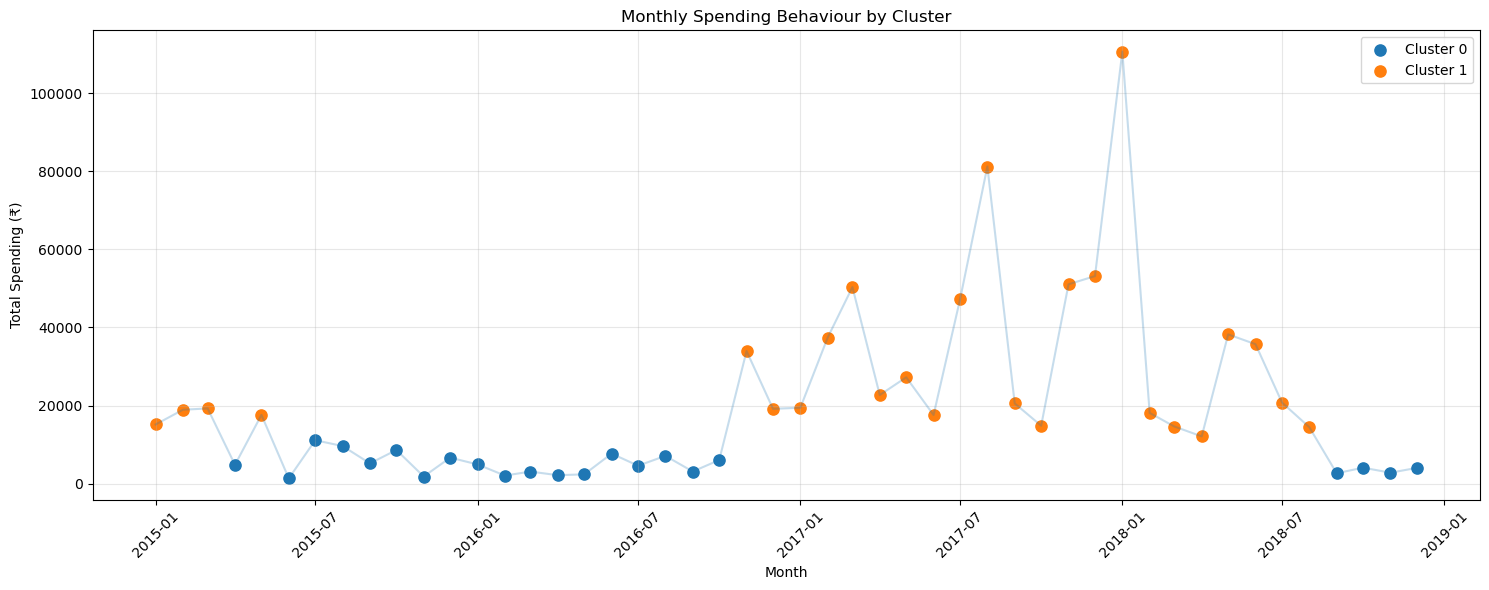

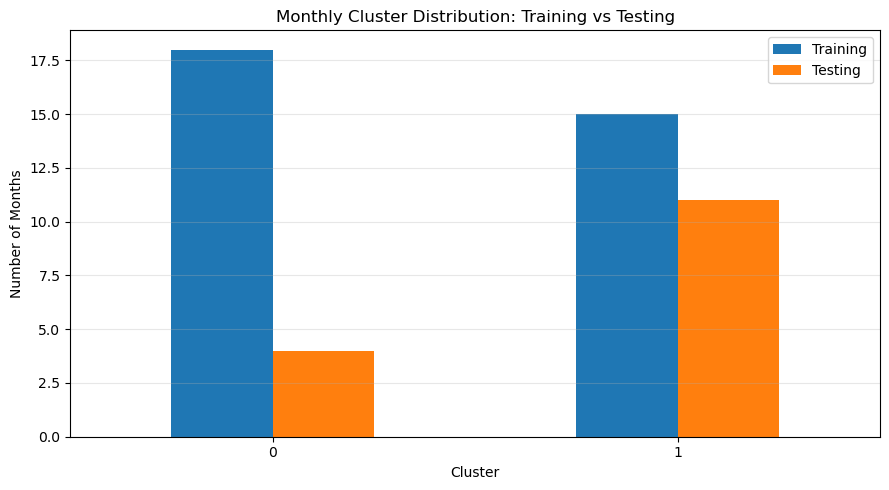

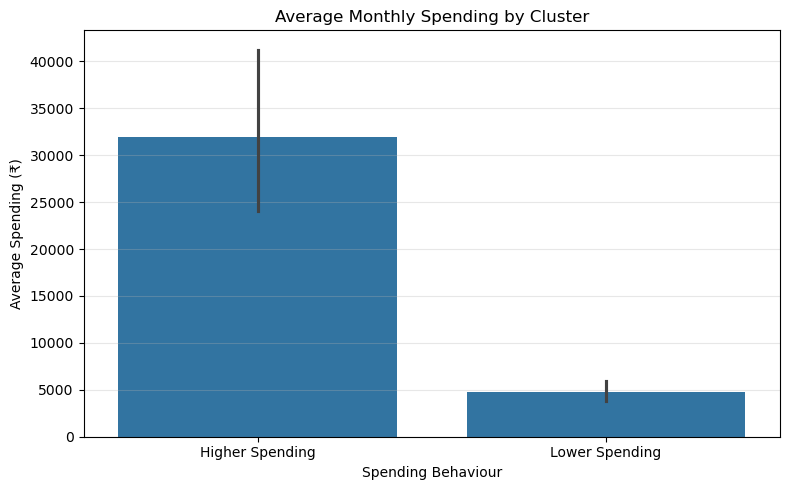

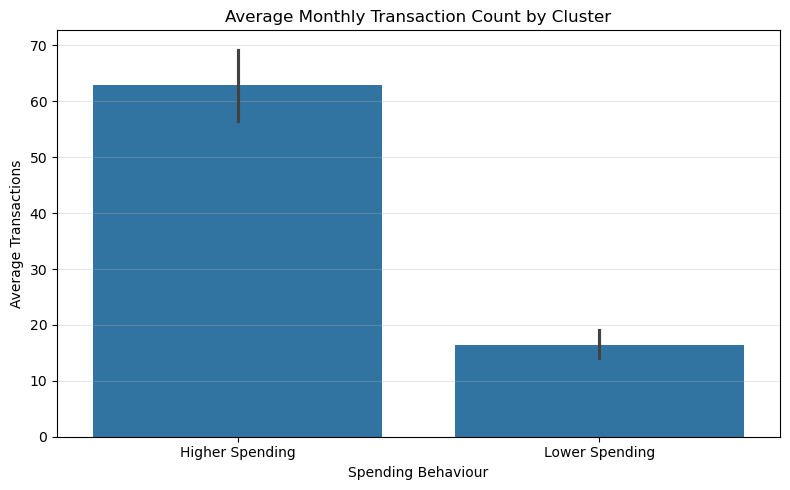


Step 21 completed successfully.


In [156]:

# ============================================================
# FORESIGHT — STEP 21: MONTHLY CLUSTER VISUALIZATION (FIXED)
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


# ------------------------------------------------------------
# 1. COMBINE TRAINING AND TEST ASSIGNMENTS
# ------------------------------------------------------------

monthly_all_assignments = pd.concat([
    monthly_intensity_train_profile,
    monthly_intensity_test_profile
]).sort_index()

monthly_all_assignments["Cluster_Name"] = (
    monthly_all_assignments["Cluster"]
    .map({
        0: "Lower Spending",
        1: "Higher Spending"
    })
)

# Convert PeriodIndex to DatetimeIndex for Matplotlib
if isinstance(monthly_all_assignments.index, pd.PeriodIndex):
    plot_dates = monthly_all_assignments.index.to_timestamp()
else:
    plot_dates = pd.to_datetime(monthly_all_assignments.index)

print("=" * 70)
print("MONTHLY CLUSTER VISUALIZATION")
print("=" * 70)


# ------------------------------------------------------------
# 2. MONTHLY SPENDING TREND BY CLUSTER
# ------------------------------------------------------------

plt.figure(figsize=(15, 6))

for cluster in sorted(
    monthly_all_assignments["Cluster"].unique()
):

    cluster_mask = (
        monthly_all_assignments["Cluster"] == cluster
    )

    plt.scatter(
        plot_dates[cluster_mask],
        monthly_all_assignments.loc[
            cluster_mask, "Total_Spending"
        ],
        label=f"Cluster {cluster}",
        s=65
    )

plt.plot(
    plot_dates,
    monthly_all_assignments["Total_Spending"],
    alpha=0.25
)

plt.title("Monthly Spending Behaviour by Cluster")
plt.xlabel("Month")
plt.ylabel("Total Spending (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. TRAINING VS TEST CLUSTER DISTRIBUTION
# ------------------------------------------------------------

cluster_distribution = pd.DataFrame({
    "Training": monthly_intensity_train_profile[
        "Cluster"
    ].value_counts(),

    "Testing": monthly_intensity_test_profile[
        "Cluster"
    ].value_counts()
}).fillna(0)

cluster_distribution = cluster_distribution.sort_index()

cluster_distribution.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Monthly Cluster Distribution: Training vs Testing")
plt.xlabel("Cluster")
plt.ylabel("Number of Months")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. AVERAGE SPENDING PER CLUSTER
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    data=monthly_all_assignments,
    x="Cluster_Name",
    y="Total_Spending",
    estimator=np.mean
)

plt.title("Average Monthly Spending by Cluster")
plt.xlabel("Spending Behaviour")
plt.ylabel("Average Spending (₹)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. AVERAGE TRANSACTION COUNT PER CLUSTER
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    data=monthly_all_assignments,
    x="Cluster_Name",
    y="Transaction_Count",
    estimator=np.mean
)

plt.title("Average Monthly Transaction Count by Cluster")
plt.xlabel("Spending Behaviour")
plt.ylabel("Average Transactions")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


print("\nStep 21 completed successfully.")


In [157]:

# ============================================================
# FORESIGHT — STEP 22: ALTERNATIVE CLUSTERING COMPARISON
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    SpectralClustering,
    DBSCAN
)
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)
from sklearn.metrics import pairwise_distances


# ------------------------------------------------------------
# 1. PREPARE WEEKLY AND MONTHLY DATA
# ------------------------------------------------------------

comparison_datasets = {
    "Weekly A2 Composition": {
        "features": weekly_composition_features.sort_index(),
        "scaler": RobustScaler
    },
    "Monthly A1 Intensity": {
        "features": monthly_intensity_features.sort_index(),
        "scaler": StandardScaler
    }
}

K = 2
TRAIN_RATIO = 0.70
RANDOM_STATE = 42

comparison_results = []
comparison_models = {}


# ------------------------------------------------------------
# 2. HELPER FUNCTIONS
# ------------------------------------------------------------

def calculate_metrics(X, labels):

    labels = np.asarray(labels)

    # Exclude DBSCAN noise points from separation metrics.
    valid = labels != -1

    X_valid = X[valid]
    labels_valid = labels[valid]

    unique_clusters = np.unique(labels_valid)

    if (
        len(unique_clusters) >= 2
        and len(unique_clusters) < len(labels_valid)
    ):
        silhouette = silhouette_score(
            X_valid, labels_valid
        )

        db_score = davies_bouldin_score(
            X_valid, labels_valid
        )
    else:
        silhouette = np.nan
        db_score = np.nan

    return silhouette, db_score


def predict_using_centroids(
    X_train,
    train_labels,
    X_test
):

    clusters = np.unique(train_labels)

    centroids = np.vstack([
        X_train[train_labels == cluster].mean(axis=0)
        for cluster in clusters
    ])

    distances = pairwise_distances(
        X_test, centroids
    )

    return clusters[distances.argmin(axis=1)]


def add_result(
    dataset_name,
    algorithm,
    train_labels,
    test_labels,
    X_train,
    X_test,
    extra_info=""
):

    train_sil, train_db = calculate_metrics(
        X_train, train_labels
    )

    test_sil, test_db = calculate_metrics(
        X_test, test_labels
    )

    train_sizes = pd.Series(train_labels).value_counts()
    test_sizes = pd.Series(test_labels).value_counts()

    comparison_results.append({
        "Dataset": dataset_name,
        "Algorithm": algorithm,
        "Train_Silhouette": train_sil,
        "Test_Silhouette": test_sil,
        "Train_DB": train_db,
        "Test_DB": test_db,
        "Train_Clusters": len(np.unique(train_labels[train_labels != -1])),
        "Test_Clusters": len(np.unique(test_labels[test_labels != -1])),
        "Train_Noise": int(np.sum(np.asarray(train_labels) == -1)),
        "Test_Noise": int(np.sum(np.asarray(test_labels) == -1)),
        "Smallest_Train_Cluster": (
            train_sizes.drop(index=-1, errors="ignore").min()
            if len(train_sizes.drop(index=-1, errors="ignore")) else 0
        ),
        "Smallest_Test_Cluster": (
            test_sizes.drop(index=-1, errors="ignore").min()
            if len(test_sizes.drop(index=-1, errors="ignore")) else 0
        ),
        "Details": extra_info
    })


# ------------------------------------------------------------
# 3. RUN COMPARISONS ON BOTH DATASETS
# ------------------------------------------------------------

for dataset_name, config in comparison_datasets.items():

    print("\n" + "=" * 75)
    print(dataset_name)
    print("=" * 75)

    X = config["features"]

    split_position = int(len(X) * TRAIN_RATIO)

    X_train_df = X.iloc[:split_position]
    X_test_df = X.iloc[split_position:]

    # Fit scaling on training data only.
    scaler = config["scaler"]()

    X_train = scaler.fit_transform(X_train_df)
    X_test = scaler.transform(X_test_df)

    print("Training observations:", len(X_train))
    print("Testing observations:", len(X_test))

    # --------------------------------------------------------
    # A. K-MEANS
    # --------------------------------------------------------

    model = KMeans(
        n_clusters=K,
        random_state=RANDOM_STATE,
        n_init=20
    )

    train_labels = model.fit_predict(X_train)
    test_labels = model.predict(X_test)

    add_result(
        dataset_name, "K-Means",
        train_labels, test_labels,
        X_train, X_test
    )

    comparison_models[
        f"{dataset_name} | K-Means"
    ] = {
        "model": model,
        "scaler": scaler,
        "train_labels": train_labels,
        "test_labels": test_labels
    }

    # --------------------------------------------------------
    # B. AGGLOMERATIVE CLUSTERING
    # --------------------------------------------------------

    model = AgglomerativeClustering(
        n_clusters=K,
        linkage="ward"
    )

    train_labels = model.fit_predict(X_train)

    # Approximate future assignment using nearest
    # training-cluster centroid.
    test_labels = predict_using_centroids(
        X_train, train_labels, X_test
    )

    add_result(
        dataset_name, "Agglomerative",
        train_labels, test_labels,
        X_train, X_test,
        "Test assignment uses nearest cluster centroid"
    )

    comparison_models[
        f"{dataset_name} | Agglomerative"
    ] = {
        "model": model,
        "scaler": scaler,
        "train_labels": train_labels,
        "test_labels": test_labels
    }

    # --------------------------------------------------------
    # C. GAUSSIAN MIXTURE MODEL
    # --------------------------------------------------------

    gmm_candidates = []

    for covariance_type in [
        "full", "tied", "diag", "spherical"
    ]:

        model = GaussianMixture(
            n_components=K,
            covariance_type=covariance_type,
            random_state=RANDOM_STATE,
            n_init=5,
            reg_covar=1e-5
        )

        train_labels = model.fit_predict(X_train)

        gmm_candidates.append((
            model.bic(X_train),
            model,
            train_labels
        ))

    # Select covariance configuration with lowest training BIC.
    best_bic, model, train_labels = min(
        gmm_candidates, key=lambda item: item[0]
    )

    test_labels = model.predict(X_test)

    add_result(
        dataset_name, "GMM",
        train_labels, test_labels,
        X_train, X_test,
        f"Selected covariance by training BIC: {model.covariance_type}"
    )

    comparison_models[
        f"{dataset_name} | GMM"
    ] = {
        "model": model,
        "scaler": scaler,
        "train_labels": train_labels,
        "test_labels": test_labels
    }

    # --------------------------------------------------------
    # D. SPECTRAL CLUSTERING
    # --------------------------------------------------------

    neighbors = min(10, len(X_train) - 1)

    model = SpectralClustering(
        n_clusters=K,
        affinity="nearest_neighbors",
        n_neighbors=neighbors,
        assign_labels="kmeans",
        random_state=RANDOM_STATE
    )

    train_labels = model.fit_predict(X_train)

    # Spectral clustering has no native predict().
    test_labels = predict_using_centroids(
        X_train, train_labels, X_test
    )

    add_result(
        dataset_name, "Spectral",
        train_labels, test_labels,
        X_train, X_test,
        "Test assignment uses nearest cluster centroid"
    )

    comparison_models[
        f"{dataset_name} | Spectral"
    ] = {
        "model": model,
        "scaler": scaler,
        "train_labels": train_labels,
        "test_labels": test_labels
    }

    # --------------------------------------------------------
    # E. DBSCAN
    # --------------------------------------------------------

    best_dbscan = None
    best_dbscan_score = -np.inf

    for eps in [0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0]:

        for min_samples in [3, 5]:

            candidate = DBSCAN(
                eps=eps,
                min_samples=min_samples
            )

            labels = candidate.fit_predict(X_train)

            valid_labels = labels[labels != -1]
            unique = np.unique(valid_labels)

            noise_ratio = np.mean(labels == -1)

            if (
                len(unique) >= 2
                and len(unique) < len(valid_labels)
                and noise_ratio <= 0.35
            ):

                score = silhouette_score(
                    X_train[labels != -1],
                    valid_labels
                )

                if score > best_dbscan_score:
                    best_dbscan_score = score
                    best_dbscan = (
                        candidate, labels, eps
                    )

    if best_dbscan is not None:

        model, train_labels, selected_eps = best_dbscan

        # Approximate DBSCAN prediction:
        # assign each test point to its nearest core point's
        # cluster if it is within the selected eps distance.
        core_points = X_train[model.core_sample_indices_]
        core_labels = train_labels[model.core_sample_indices_]

        distances = pairwise_distances(
            X_test, core_points
        )

        nearest_indices = distances.argmin(axis=1)
        nearest_distances = distances.min(axis=1)

        test_labels = core_labels[nearest_indices].copy()
        test_labels[nearest_distances > selected_eps] = -1

        add_result(
            dataset_name, "DBSCAN",
            train_labels, test_labels,
            X_train, X_test,
            f"eps={selected_eps}; nearest-core-point assignment"
        )

        comparison_models[
            f"{dataset_name} | DBSCAN"
        ] = {
            "model": model,
            "scaler": scaler,
            "train_labels": train_labels,
            "test_labels": test_labels
        }

    else:
        print(
            "\nDBSCAN: No configuration met the minimum "
            "cluster and noise requirements."
        )


    # --------------------------------------------------------
    # F. K-MEDOIDS — OPTIONAL PACKAGE
    # --------------------------------------------------------

    try:

        from sklearn_extra.cluster import KMedoids

        model = KMedoids(
            n_clusters=K,
            metric="euclidean",
            random_state=RANDOM_STATE
        )

        train_labels = model.fit_predict(X_train)
        test_labels = model.predict(X_test)

        add_result(
            dataset_name, "K-Medoids",
            train_labels, test_labels,
            X_train, X_test
        )

        comparison_models[
            f"{dataset_name} | K-Medoids"
        ] = {
            "model": model,
            "scaler": scaler,
            "train_labels": train_labels,
            "test_labels": test_labels
        }

    except ImportError:

        print(
            "\nK-Medoids skipped: scikit-learn-extra "
            "is not installed. No extra package was installed."
        )


# ------------------------------------------------------------
# 4. DISPLAY COMPARISON RESULTS
# ------------------------------------------------------------

comparison_results_df = pd.DataFrame(
    comparison_results
)

print("\n" + "=" * 85)
print("FORESIGHT — STEP 22: ALGORITHM COMPARISON")
print("=" * 85)

display(
    comparison_results_df.round(4)
)


# ------------------------------------------------------------
# 5. SHOW TEST CLUSTER DISTRIBUTIONS
# ------------------------------------------------------------

print("\nTEST CLUSTER DISTRIBUTIONS")

for name, result in comparison_models.items():

    print(f"\n{name}")

    print(
        pd.Series(result["test_labels"])
        .value_counts()
        .sort_index()
        .to_dict()
    )


# ------------------------------------------------------------
# 6. SAVE RESULTS FOR FUTURE ANALYSIS
# ------------------------------------------------------------

print("\nStep 22 completed successfully.")



Weekly A2 Composition
Training observations: 135
Testing observations: 58


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


K-Medoids skipped: scikit-learn-extra is not installed. No extra package was installed.

Monthly A1 Intensity
Training observations: 33
Testing observations: 15


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


K-Medoids skipped: scikit-learn-extra is not installed. No extra package was installed.

FORESIGHT — STEP 22: ALGORITHM COMPARISON


,Dataset,Algorithm,Train_Silhouette,Test_Silhouette,Train_DB,Test_DB,Train_Clusters,Test_Clusters,Train_Noise,Test_Noise,Smallest_Train_Cluster,Smallest_Test_Cluster,Details
0,Weekly A2 Composition,K-Means,0.8427,0.7674,0.4415,0.4210,2,2,0,0,9,10,
1,Weekly A2 Composition,Agglomerative,0.7690,0.7784,0.6550,0.4278,2,2,0,0,19,11,Test assignment uses nearest cluster centroid
2,Weekly A2 Composition,GMM,0.0003,0.1592,2.7352,3.6545,2,2,0,0,58,14,Selected covariance by training BIC: diag
3,Weekly A2 Composition,Spectral,0.6657,0.7784,0.8335,0.4278,2,2,0,0,26,11,Test assignment uses nearest cluster centroid
4,Weekly A2 Composition,DBSCAN,0.6335,0.6998,0.3956,0.2181,5,3,47,36,3,2,eps=2.5; nearest-core-point assignment
5,Monthly A1 Intensity,K-Means,0.3630,0.4092,1.0409,0.8935,2,2,0,0,15,4,
6,Monthly A1 Intensity,Agglomerative,0.3563,0.4092,1.0372,0.8935,2,2,0,0,14,4,Test assignment uses nearest cluster centroid
7,Monthly A1 Intensity,GMM,0.3472,0.4092,1.0766,0.8935,2,2,0,0,15,4,Selected covariance by training BIC: full
8,Monthly A1 Intensity,Spectral,0.3630,0.4092,1.0409,0.8935,2,2,0,0,15,4,Test assignment uses nearest cluster centroid
9,Monthly A1 Intensity,DBSCAN,0.4604,0.3566,0.8270,0.4205,2,2,7,6,13,1,eps=1.2; nearest-core-point assignment



TEST CLUSTER DISTRIBUTIONS

Weekly A2 Composition | K-Means
{0: 48, 1: 10}

Weekly A2 Composition | Agglomerative
{0: 11, 1: 47}

Weekly A2 Composition | GMM
{0: 44, 1: 14}

Weekly A2 Composition | Spectral
{0: 47, 1: 11}

Weekly A2 Composition | DBSCAN
{-1: 36, 0: 17, 2: 2, 4: 3}

Monthly A1 Intensity | K-Means
{0: 4, 1: 11}

Monthly A1 Intensity | Agglomerative
{0: 4, 1: 11}

Monthly A1 Intensity | GMM
{0: 4, 1: 11}

Monthly A1 Intensity | Spectral
{0: 11, 1: 4}

Monthly A1 Intensity | DBSCAN
{-1: 6, 0: 8, 1: 1}

Step 22 completed successfully.


In [158]:

# ============================================================
# FORESIGHT — STEP 23: FINAL WEEKLY MODEL VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)


# ------------------------------------------------------------
# 1. PREPARE WEEKLY DATA
# ------------------------------------------------------------

weekly_X = weekly_composition_features.sort_index().copy()

# Align original spending information with active weeks
weekly_original = weekly_features.loc[
    weekly_X.index
].copy()

split_position = int(len(weekly_X) * 0.70)

X_train = weekly_X.iloc[:split_position]
X_test = weekly_X.iloc[split_position:]

spending_train = weekly_original.iloc[:split_position]
spending_test = weekly_original.iloc[split_position:]

print("=" * 75)
print("WEEKLY MODEL VALIDATION")
print("=" * 75)

print("Total active weeks:", len(weekly_X))
print("Training weeks:", len(X_train))
print("Testing weeks:", len(X_test))

print("Training period:", X_train.index.min(), "to", X_train.index.max())
print("Testing period:", X_test.index.min(), "to", X_test.index.max())


# ------------------------------------------------------------
# 2. SCALE DATA WITHOUT FUTURE DATA LEAKAGE
# ------------------------------------------------------------

weekly_final_scaler = RobustScaler()

X_train_scaled = weekly_final_scaler.fit_transform(X_train)
X_test_scaled = weekly_final_scaler.transform(X_test)


# ------------------------------------------------------------
# 3. TRAIN K=2 AND K=3 MODELS
# ------------------------------------------------------------

weekly_validation_models = {}
weekly_validation_results = []

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    train_labels = model.fit_predict(X_train_scaled)
    test_labels = model.predict(X_test_scaled)

    weekly_validation_models[k] = {
        "model": model,
        "train_labels": train_labels,
        "test_labels": test_labels
    }

    # Training metrics
    train_silhouette = silhouette_score(
        X_train_scaled,
        train_labels
    )

    train_db = davies_bouldin_score(
        X_train_scaled,
        train_labels
    )

    # Test metrics
    if len(np.unique(test_labels)) >= 2:

        test_silhouette = silhouette_score(
            X_test_scaled,
            test_labels
        )

        test_db = davies_bouldin_score(
            X_test_scaled,
            test_labels
        )

    else:
        test_silhouette = np.nan
        test_db = np.nan

    train_sizes = pd.Series(train_labels).value_counts()
    test_sizes = pd.Series(test_labels).value_counts()

    weekly_validation_results.append({
        "K": k,
        "Train_Silhouette": train_silhouette,
        "Test_Silhouette": test_silhouette,
        "Train_Davies_Bouldin": train_db,
        "Test_Davies_Bouldin": test_db,
        "Train_Smallest_Cluster": train_sizes.min(),
        "Test_Smallest_Cluster": test_sizes.min(),
        "Test_Empty_Clusters": k - len(test_sizes)
    })


# ------------------------------------------------------------
# 4. COMPARE K=2 AND K=3
# ------------------------------------------------------------

weekly_validation_comparison = pd.DataFrame(
    weekly_validation_results
).set_index("K").round(4)

print("\n" + "=" * 75)
print("WEEKLY K=2 VS K=3 COMPARISON")
print("=" * 75)

display(weekly_validation_comparison)


# ------------------------------------------------------------
# 5. DISPLAY TRAINING AND TEST CLUSTER DISTRIBUTIONS
# ------------------------------------------------------------

for k in [2, 3]:

    train_labels = weekly_validation_models[k]["train_labels"]
    test_labels = weekly_validation_models[k]["test_labels"]

    distribution = pd.DataFrame({
        "Training": pd.Series(train_labels).value_counts(),
        "Testing": pd.Series(test_labels).value_counts()
    }).fillna(0).astype(int)

    distribution = distribution.sort_index()

    print(f"\nK={k} — CLUSTER DISTRIBUTION")
    display(distribution)


# ------------------------------------------------------------
# 6. PROFILE EACH K=2 AND K=3 MODEL
# ------------------------------------------------------------

for k in [2, 3]:

    train_labels = weekly_validation_models[k]["train_labels"]
    test_labels = weekly_validation_models[k]["test_labels"]

    train_profile = spending_train.copy()
    test_profile = spending_test.copy()

    train_profile["Cluster"] = train_labels
    test_profile["Cluster"] = test_labels

    print("\n" + "=" * 75)
    print(f"WEEKLY K={k} — TRAINING SPENDING PROFILE")
    print("=" * 75)

    display(
        train_profile.groupby("Cluster").agg(
            Week_Count=("Total_Spending", "size"),
            Average_Spending=("Total_Spending", "mean"),
            Median_Spending=("Total_Spending", "median"),
            Average_Transactions=("Transaction_Count", "mean"),
            Average_Transaction_Value=("Average_Transaction", "mean")
        ).round(2)
    )

    print(f"\nWEEKLY K={k} — TEST SPENDING PROFILE")

    display(
        test_profile.groupby("Cluster").agg(
            Week_Count=("Total_Spending", "size"),
            Average_Spending=("Total_Spending", "mean"),
            Median_Spending=("Total_Spending", "median"),
            Average_Transactions=("Transaction_Count", "mean"),
            Average_Transaction_Value=("Average_Transaction", "mean")
        ).round(2)
    )

    # Category composition in test clusters
    print(f"\nWEEKLY K={k} — TEST CATEGORY COMPOSITION")

    for cluster in sorted(test_profile["Cluster"].unique()):

        cluster_index = test_profile[
            test_profile["Cluster"] == cluster
        ].index

        category_means = (
            weekly_composition_features.loc[cluster_index]
            .mean()
            .sort_values(ascending=False)
            .head(5)
        )

        print(f"\nCluster {cluster} — Top 5 Categories")

        display(
            (category_means * 100)
            .round(2)
            .rename("Average_Category_Share_Percent")
            .to_frame()
        )


# ------------------------------------------------------------
# 7. SAVE WEEKLY VALIDATION OUTPUTS
# ------------------------------------------------------------

weekly_k2_model = weekly_validation_models[2]["model"]
weekly_k3_model = weekly_validation_models[3]["model"]

weekly_k2_train_labels = weekly_validation_models[2]["train_labels"]
weekly_k2_test_labels = weekly_validation_models[2]["test_labels"]

weekly_k3_train_labels = weekly_validation_models[3]["train_labels"]
weekly_k3_test_labels = weekly_validation_models[3]["test_labels"]

weekly_k2_train_profile = spending_train.copy()
weekly_k2_train_profile["Cluster"] = weekly_k2_train_labels

weekly_k2_test_profile = spending_test.copy()
weekly_k2_test_profile["Cluster"] = weekly_k2_test_labels

weekly_k3_train_profile = spending_train.copy()
weekly_k3_train_profile["Cluster"] = weekly_k3_train_labels

weekly_k3_test_profile = spending_test.copy()
weekly_k3_test_profile["Cluster"] = weekly_k3_test_labels

print("\nStep 23 completed successfully.")


WEEKLY MODEL VALIDATION
Total active weeks: 193
Training weeks: 135
Testing weeks: 58
Training period: 2014-12-29/2015-01-04 to 2017-09-18/2017-09-24
Testing period: 2017-09-25/2017-10-01 to 2018-12-03/2018-12-09


c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



WEEKLY K=2 VS K=3 COMPARISON


,Train_Silhouette,Test_Silhouette,Train_Davies_Bouldin,Test_Davies_Bouldin,Train_Smallest_Cluster,Test_Smallest_Cluster,Test_Empty_Clusters
K,,,,,,,
2,0.8427,0.7674,0.4415,0.4210,9,10,0
3,0.7967,0.7648,0.4144,0.3124,3,1,0



K=2 — CLUSTER DISTRIBUTION


,Training,Testing
0,126,48
1,9,10


... (17 outputs left out)

,Average_Category_Share_Percent
Health,38.22
Household,20.36
Food,12.57
Transportation,8.74
Apparel,6.33



Cluster 2 — Top 5 Categories


,Average_Category_Share_Percent
Health,83.49
Apparel,9.19
Other,2.89
Food,1.80
Culture,1.50



Step 23 completed successfully.


In [159]:

# ============================================================
# FORESIGHT — STEP 24: FINAL WEEKLY & MONTHLY MODEL AUDIT
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. RETRIEVE THE SELECTED WEEKLY MODEL
# ------------------------------------------------------------

weekly_audit_features = weekly_composition_features.sort_index()

weekly_audit_split = int(len(weekly_audit_features) * 0.70)

weekly_audit_train = weekly_audit_features.iloc[:weekly_audit_split]
weekly_audit_test = weekly_audit_features.iloc[weekly_audit_split:]

weekly_audit_model = weekly_k2_model
weekly_audit_scaler = weekly_final_scaler

weekly_train_labels = np.asarray(weekly_k2_train_labels)
weekly_test_labels = np.asarray(weekly_k2_test_labels)


# ------------------------------------------------------------
# 2. RETRIEVE THE SELECTED MONTHLY MODEL
# ------------------------------------------------------------

monthly_audit_key = (
    "Original Intensity - StandardScaler | K=2"
)

monthly_audit_experiment = monthly_improvement_models[
    monthly_audit_key
]

monthly_audit_model = monthly_audit_experiment["model"]
monthly_audit_scaler = monthly_audit_experiment["scaler"]

monthly_audit_train = monthly_audit_experiment["train_features"]
monthly_audit_test = monthly_audit_experiment["test_features"]

monthly_train_labels = np.asarray(
    monthly_audit_experiment["train_labels"]
)

monthly_test_labels = np.asarray(
    monthly_audit_experiment["test_labels"]
)


# ------------------------------------------------------------
# 3. DEFINE THE AUDIT FUNCTION
# ------------------------------------------------------------

def audit_clustering_model(
    model_name,
    model,
    scaler,
    train_features,
    test_features,
    train_labels,
    test_labels
):

    print("\n" + "=" * 75)
    print(model_name)
    print("=" * 75)

    checks = {}

    # Feature count
    checks["Feature count matches scaler"] = (
        train_features.shape[1] == scaler.n_features_in_
    )

    checks["Feature count matches model"] = (
        train_features.shape[1] == model.n_features_in_
    )

    # Feature order and consistency
    checks["Train/test feature columns match"] = (
        list(train_features.columns) == list(test_features.columns)
    )

    # Data quality
    checks["Training data has no missing values"] = (
        not train_features.isna().any().any()
    )

    checks["Testing data has no missing values"] = (
        not test_features.isna().any().any()
    )

    checks["Training data has no infinite values"] = (
        np.isfinite(train_features.to_numpy()).all()
    )

    checks["Testing data has no infinite values"] = (
        np.isfinite(test_features.to_numpy()).all()
    )

    # Label lengths
    checks["Training label count matches observations"] = (
        len(train_labels) == len(train_features)
    )

    checks["Testing label count matches observations"] = (
        len(test_labels) == len(test_features)
    )

    # Cluster count
    checks["Model has 2 clusters"] = (
        model.n_clusters == 2
    )

    # Confirm model can transform the supplied features
    train_scaled = scaler.transform(train_features)
    test_scaled = scaler.transform(test_features)

    checks["Scaled training data is finite"] = (
        np.isfinite(train_scaled).all()
    )

    checks["Scaled testing data is finite"] = (
        np.isfinite(test_scaled).all()
    )

    # Verify stored assignments against the fitted model
    predicted_train = model.predict(train_scaled)
    predicted_test = model.predict(test_scaled)

    checks["Training labels match model predictions"] = (
        np.array_equal(predicted_train, train_labels)
    )

    checks["Test labels match model predictions"] = (
        np.array_equal(predicted_test, test_labels)
    )

    # Display audit checks
    audit_table = pd.DataFrame({
        "Check": list(checks.keys()),
        "Result": [
            "PASS" if value else "FAIL"
            for value in checks.values()
        ]
    })

    display(audit_table)

    # Cluster distributions
    cluster_distribution = pd.DataFrame({
        "Training": pd.Series(train_labels).value_counts(),
        "Testing": pd.Series(test_labels).value_counts()
    }).reindex([0, 1], fill_value=0)

    print("\nCLUSTER DISTRIBUTION")
    display(cluster_distribution)

    # Period information
    print("\nTRAINING PERIOD:")
    print(train_features.index.min(), "to", train_features.index.max())

    print("\nTESTING PERIOD:")
    print(test_features.index.min(), "to", test_features.index.max())

    passed = sum(checks.values())
    total = len(checks)

    print(f"\nAudit checks passed: {passed}/{total}")

    return {
        "checks": checks,
        "passed": passed,
        "total": total,
        "distribution": cluster_distribution
    }


# ------------------------------------------------------------
# 4. RUN WEEKLY AUDIT
# ------------------------------------------------------------

weekly_final_audit = audit_clustering_model(
    model_name="WEEKLY K-MEANS — A2 + ROBUST SCALER + K=2",
    model=weekly_audit_model,
    scaler=weekly_audit_scaler,
    train_features=weekly_audit_train,
    test_features=weekly_audit_test,
    train_labels=weekly_train_labels,
    test_labels=weekly_test_labels
)


# ------------------------------------------------------------
# 5. RUN MONTHLY AUDIT
# ------------------------------------------------------------

monthly_final_audit = audit_clustering_model(
    model_name="MONTHLY K-MEANS — A1 + STANDARD SCALER + K=2",
    model=monthly_audit_model,
    scaler=monthly_audit_scaler,
    train_features=monthly_audit_train,
    test_features=monthly_audit_test,
    train_labels=monthly_train_labels,
    test_labels=monthly_test_labels
)


# ------------------------------------------------------------
# 6. OVERALL AUDIT SUMMARY
# ------------------------------------------------------------

overall_audit = pd.DataFrame({
    "Model": ["Weekly K-Means", "Monthly K-Means"],
    "Checks_Passed": [
        weekly_final_audit["passed"],
        monthly_final_audit["passed"]
    ],
    "Total_Checks": [
        weekly_final_audit["total"],
        monthly_final_audit["total"]
    ]
})

overall_audit["All_Checks_Passed"] = (
    overall_audit["Checks_Passed"]
    == overall_audit["Total_Checks"]
)

print("\n" + "=" * 75)
print("FORESIGHT — FINAL MODEL AUDIT SUMMARY")
print("=" * 75)

display(overall_audit)

if overall_audit["All_Checks_Passed"].all():
    print("\nSUCCESS: All technical audit checks passed.")
else:
    print("\nWARNING: Some audit checks failed. Review them before proceeding.")

print("\nStep 24 completed.")



WEEKLY K-MEANS — A2 + ROBUST SCALER + K=2


,Check,Result
0,Feature count matches scaler,PASS
1,Feature count matches model,PASS
2,Train/test feature columns match,PASS
3,Training data has no missing values,PASS
4,Testing data has no missing values,PASS
5,Training data has no infinite values,PASS
6,Testing data has no infinite values,PASS
7,Training label count matches observations,PASS
8,Testing label count matches observations,PASS
9,Model has 2 clusters,PASS



CLUSTER DISTRIBUTION


,Training,Testing
0,126,48
1,9,10



TRAINING PERIOD:
2014-12-29/2015-01-04 to 2017-09-18/2017-09-24

TESTING PERIOD:
2017-09-25/2017-10-01 to 2018-12-03/2018-12-09

Audit checks passed: 14/14

MONTHLY K-MEANS — A1 + STANDARD SCALER + K=2


,Check,Result
0,Feature count matches scaler,PASS
1,Feature count matches model,PASS
2,Train/test feature columns match,PASS
3,Training data has no missing values,PASS
4,Testing data has no missing values,PASS
5,Training data has no infinite values,PASS
6,Testing data has no infinite values,PASS
7,Training label count matches observations,PASS
8,Testing label count matches observations,PASS
9,Model has 2 clusters,PASS



CLUSTER DISTRIBUTION


,Training,Testing
0,18,4
1,15,11



TRAINING PERIOD:
2015-01 to 2017-09

TESTING PERIOD:
2017-10 to 2018-12

Audit checks passed: 14/14

FORESIGHT — FINAL MODEL AUDIT SUMMARY


,Model,Checks_Passed,Total_Checks,All_Checks_Passed
0,Weekly K-Means,14,14,True
1,Monthly K-Means,14,14,True



SUCCESS: All technical audit checks passed.

Step 24 completed.


In [160]:

# ============================================================
# FORESIGHT — STEP 25: FINAL CLUSTER INTERPRETATION
# ============================================================

import pandas as pd

print("=" * 80)
print("FORESIGHT — FINAL SPENDING BEHAVIOUR INTERPRETATION")
print("=" * 80)

# ------------------------------------------------------------
# 1. WEEKLY CLUSTER INTERPRETATION
# ------------------------------------------------------------

weekly_interpretation = pd.DataFrame({
    "Cluster": [0, 1],
    "Behaviour_Name": [
        "Diversified Spending",
        "Health-Focused Spending"
    ],
    "Training_Weeks": [126, 9],
    "Testing_Weeks": [48, 10],
    "Test_Average_Spending": [7172.70, 5751.90],
    "Test_Median_Spending": [3654.99, 2822.00],
    "Test_Average_Transactions": [13.94, 12.40],
    "Dominant_Test_Category": [
        "Food",
        "Health"
    ],
    "Dominant_Category_Share_Percent": [
        21.81,
        43.99
    ]
})

print("\nWEEKLY BEHAVIOUR CLUSTERS")
display(weekly_interpretation)


# ------------------------------------------------------------
# 2. MONTHLY CLUSTER INTERPRETATION
# ------------------------------------------------------------

monthly_train_profile = (
    monthly_audit_train
    .copy()
    .assign(Cluster=monthly_train_labels)
    .groupby("Cluster")
    .size()
)

monthly_test_profile = (
    monthly_audit_test
    .copy()
    .assign(Cluster=monthly_test_labels)
    .groupby("Cluster")
    .agg(
        Average_Spending=("Total_Spending", "mean"),
        Median_Spending=("Total_Spending", "median"),
        Average_Transactions=("Transaction_Count", "mean"),
        Average_Transaction_Value=("Average_Transaction", "mean")
    )
)

monthly_interpretation = pd.DataFrame({
    "Cluster": [0, 1],
    "Behaviour_Name": [
        "Lower-Intensity Months",
        "Higher-Intensity Months"
    ],
    "Training_Months": [
        monthly_train_profile.get(0, 0),
        monthly_train_profile.get(1, 0)
    ],
    "Testing_Months": [
        (monthly_test_labels == 0).sum(),
        (monthly_test_labels == 1).sum()
    ]
})

monthly_interpretation = monthly_interpretation.merge(
    monthly_test_profile,
    left_on="Cluster",
    right_index=True,
    how="left"
)

print("\nMONTHLY BEHAVIOUR CLUSTERS")
display(monthly_interpretation.round(2))


# ------------------------------------------------------------
# 3. FINAL MODEL SELECTION SUMMARY
# ------------------------------------------------------------

final_model_summary = pd.DataFrame({
    "Frequency": ["Weekly", "Monthly"],
    "Selected_Algorithm": ["K-Means", "K-Means"],
    "Feature_Representation": [
        "Category Composition (A2)",
        "Spending Intensity (A1)"
    ],
    "Scaler": ["RobustScaler", "StandardScaler"],
    "Clusters": [2, 2],
    "Test_Silhouette": [0.7674, 0.4092],
    "Technical_Audit": ["14/14 PASS", "14/14 PASS"]
})

print("\nFINAL SELECTED CLUSTERING MODELS")
display(final_model_summary)


# ------------------------------------------------------------
# 4. IMPORTANT LIMITATIONS
# ------------------------------------------------------------

print("\nMODEL INTERPRETATION NOTES")
print("1. Clusters describe patterns in this household's historical data.")
print("2. Weekly clusters are mainly distinguished by category composition.")
print("3. Monthly clusters are based on spending intensity features.")
print("4. Cluster numbers are identifiers, not rankings.")
print("5. Results should not be generalized to other households without testing.")
print("6. Monthly validation has a small test sample, so interpret cautiously.")

print("\nStep 25 completed.")


FORESIGHT — FINAL SPENDING BEHAVIOUR INTERPRETATION

WEEKLY BEHAVIOUR CLUSTERS


,Cluster,Behaviour_Name,Training_Weeks,Testing_Weeks,Test_Average_Spending,Test_Median_Spending,Test_Average_Transactions,Dominant_Test_Category,Dominant_Category_Share_Percent
0,0,Diversified Spending,126,48,7172.7,3654.99,13.94,Food,21.81
1,1,Health-Focused Spending,9,10,5751.9,2822.00,12.40,Health,43.99



MONTHLY BEHAVIOUR CLUSTERS


,Cluster,Behaviour_Name,Training_Months,Testing_Months,Average_Spending,Median_Spending,Average_Transactions,Average_Transaction_Value
0,0,Lower-Intensity Months,18,4,8.11,8.12,2.84,5.34
1,1,Higher-Intensity Months,15,11,10.21,9.94,4.17,6.05



FINAL SELECTED CLUSTERING MODELS


,Frequency,Selected_Algorithm,Feature_Representation,Scaler,Clusters,Test_Silhouette,Technical_Audit
0,Weekly,K-Means,Category Composition (A2),RobustScaler,2,0.7674,14/14 PASS
1,Monthly,K-Means,Spending Intensity (A1),StandardScaler,2,0.4092,14/14 PASS



MODEL INTERPRETATION NOTES
1. Clusters describe patterns in this household's historical data.
2. Weekly clusters are mainly distinguished by category composition.
3. Monthly clusters are based on spending intensity features.
4. Cluster numbers are identifiers, not rankings.
5. Results should not be generalized to other households without testing.
6. Monthly validation has a small test sample, so interpret cautiously.

Step 25 completed.


In [161]:

# ============================================================
# FORESIGHT — STEP 26: CORRECTED FINAL CLUSTER REPORT
# Uses original data for interpretation, not transformed data
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. WEEKLY TEST CLUSTER PROFILES — ACTUAL RUPEES
# ------------------------------------------------------------

weekly_original_test = weekly_features.loc[
    weekly_audit_test.index
].copy()

weekly_original_test["Cluster"] = weekly_test_labels

weekly_test_report = weekly_original_test.groupby("Cluster").agg(
    Number_of_Weeks=("Total_Spending", "size"),
    Average_Spending_INR=("Total_Spending", "mean"),
    Median_Spending_INR=("Total_Spending", "median"),
    Average_Transactions=("Transaction_Count", "mean"),
    Average_Transaction_Value_INR=("Average_Transaction", "mean")
).round(2)

# Category shares from original composition features
weekly_test_composition = weekly_composition_features.loc[
    weekly_audit_test.index
].copy()

weekly_test_composition["Cluster"] = weekly_test_labels

weekly_category_profiles = (
    weekly_test_composition.groupby("Cluster")
    .mean()
)

print("=" * 75)
print("WEEKLY CLUSTER PROFILES — TEST PERIOD")
print("=" * 75)

display(weekly_test_report)

print("\nTOP 3 CATEGORY SHARES IN EACH WEEKLY CLUSTER")

for cluster in weekly_category_profiles.index:
    print(f"\nCluster {cluster}")
    display(
        (weekly_category_profiles.loc[cluster]
         .sort_values(ascending=False)
         .head(3) * 100).round(2).rename("Category_Share_Percent")
    )


# ------------------------------------------------------------
# 2. MONTHLY TEST CLUSTER PROFILES — ACTUAL RUPEES
# ------------------------------------------------------------

monthly_original_test = monthly_features.loc[
    monthly_audit_test.index
].copy()

monthly_original_test["Cluster"] = monthly_test_labels

monthly_test_report = monthly_original_test.groupby("Cluster").agg(
    Number_of_Months=("Total_Spending", "size"),
    Average_Spending_INR=("Total_Spending", "mean"),
    Median_Spending_INR=("Total_Spending", "median"),
    Average_Transactions=("Transaction_Count", "mean"),
    Average_Transaction_Value_INR=("Average_Transaction", "mean")
).round(2)

print("\n" + "=" * 75)
print("MONTHLY CLUSTER PROFILES — TEST PERIOD")
print("=" * 75)

display(monthly_test_report)


# ------------------------------------------------------------
# 3. FINAL MODEL SUMMARY
# ------------------------------------------------------------

final_model_summary = pd.DataFrame({
    "Frequency": ["Weekly", "Monthly"],
    "Algorithm": ["K-Means", "K-Means"],
    "Features": [
        "Category Composition (A2)",
        "Spending Intensity (A1)"
    ],
    "Scaler": ["RobustScaler", "StandardScaler"],
    "K": [2, 2],
    "Test_Silhouette": [0.7674, 0.4092],
    "Technical_Audit": ["14/14 PASS", "14/14 PASS"]
})

print("\nFINAL SELECTED MODELS")
display(final_model_summary)

print("\nStep 26 completed successfully.")


WEEKLY CLUSTER PROFILES — TEST PERIOD


,Number_of_Weeks,Average_Spending_INR,Median_Spending_INR,Average_Transactions,Average_Transaction_Value_INR
Cluster,,,,,
0,48,7172.7,3654.99,13.94,466.71
1,10,5751.9,2822.00,12.40,383.14



TOP 3 CATEGORY SHARES IN EACH WEEKLY CLUSTER

Cluster 0


Food              21.81
Household         19.43
Transportation    16.05
Name: Category_Share_Percent, dtype: float64


Cluster 1


Health       43.99
Household    14.61
Food         11.47
Name: Category_Share_Percent, dtype: float64


MONTHLY CLUSTER PROFILES — TEST PERIOD


,Number_of_Months,Average_Spending_INR,Median_Spending_INR,Average_Transactions,Average_Transaction_Value_INR
Cluster,,,,,
0,4,3394.00,3416.50,16.50,220.44
1,11,34868.95,20762.36,64.73,508.19



FINAL SELECTED MODELS


,Frequency,Algorithm,Features,Scaler,K,Test_Silhouette,Technical_Audit
0,Weekly,K-Means,Category Composition (A2),RobustScaler,2,0.7674,14/14 PASS
1,Monthly,K-Means,Spending Intensity (A1),StandardScaler,2,0.4092,14/14 PASS



Step 26 completed successfully.


In [162]:

# ============================================================
# FORESIGHT — STEP 27: SAVE FINAL CLUSTERING MODELS
# Save directly into the ROOT models folder
# ============================================================

import joblib
from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. FIND FORESIGHT PROJECT ROOT AUTOMATICALLY
# ------------------------------------------------------------

current_path = Path.cwd().resolve()

project_root = None

for candidate in [current_path, *current_path.parents]:
    if all(
        (candidate / folder).is_dir()
        for folder in ["data", "notebooks", "src"]
    ):
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not find ForeSight project root. "
        "Make sure this notebook is inside the ForeSight project."
    )

# Save in the existing ROOT models folder
model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

print("ForeSight project root:", project_root)
print("FINAL MODEL SAVE LOCATION:", model_dir)


# ------------------------------------------------------------
# 2. CHECK SELECTED MODELS
# ------------------------------------------------------------

if weekly_k2_model is None or weekly_final_scaler is None:
    raise ValueError("Weekly model or scaler is missing.")

monthly_selected = monthly_improvement_models[
    "Original Intensity - StandardScaler | K=2"
]

if monthly_selected["model"] is None:
    raise ValueError("Monthly model is missing.")


# ------------------------------------------------------------
# 3. CREATE WEEKLY MODEL BUNDLE
# ------------------------------------------------------------

weekly_bundle = {
    "model": weekly_k2_model,
    "scaler": weekly_final_scaler,
    "feature_names": list(weekly_audit_train.columns),

    "metadata": {
        "project": "ForeSight",
        "model_type": "Weekly Spending Behaviour Clustering",
        "algorithm": "KMeans",
        "n_clusters": 2,
        "features": "A2 Category Composition",
        "scaler": "RobustScaler",
        "test_silhouette": 0.7674,
        "random_state": 42,
        "training_observations": len(weekly_audit_train),
        "testing_observations": len(weekly_audit_test),
        "saved_at": datetime.now().isoformat()
    }
}

weekly_path = model_dir / "weekly_clustering_bundle.joblib"

joblib.dump(weekly_bundle, weekly_path)

print("\nWeekly model saved:", weekly_path)


# ------------------------------------------------------------
# 4. CREATE MONTHLY MODEL BUNDLE
# ------------------------------------------------------------

monthly_bundle = {
    "model": monthly_selected["model"],
    "scaler": monthly_selected["scaler"],
    "feature_names": list(
        monthly_selected["train_features"].columns
    ),

    "metadata": {
        "project": "ForeSight",
        "model_type": "Monthly Spending Behaviour Clustering",
        "algorithm": "KMeans",
        "n_clusters": 2,
        "features": "A1 Spending Intensity",
        "scaler": "StandardScaler",
        "test_silhouette": 0.4092,
        "random_state": 42,
        "training_observations": len(
            monthly_selected["train_features"]
        ),
        "testing_observations": len(
            monthly_selected["test_features"]
        ),
        "saved_at": datetime.now().isoformat()
    }
}

monthly_path = model_dir / "monthly_clustering_bundle.joblib"

joblib.dump(monthly_bundle, monthly_path)

print("Monthly model saved:", monthly_path)


# ------------------------------------------------------------
# 5. RELOAD AND VERIFY BOTH SAVED MODELS
# ------------------------------------------------------------

loaded_weekly = joblib.load(weekly_path)
loaded_monthly = joblib.load(monthly_path)

# Weekly prediction verification
weekly_test_input = weekly_audit_test[
    loaded_weekly["feature_names"]
]

weekly_predictions = loaded_weekly["model"].predict(
    loaded_weekly["scaler"].transform(weekly_test_input)
)

weekly_verified = (
    weekly_predictions == weekly_test_labels
).all()

# Monthly prediction verification
monthly_test_input = monthly_audit_test[
    loaded_monthly["feature_names"]
]

monthly_predictions = loaded_monthly["model"].predict(
    loaded_monthly["scaler"].transform(monthly_test_input)
)

monthly_verified = (
    monthly_predictions == monthly_test_labels
).all()


# ------------------------------------------------------------
# 6. FINAL RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FORESIGHT — MODEL SAVING VERIFICATION")
print("=" * 65)

print("Weekly bundle exists:", weekly_path.exists())
print("Monthly bundle exists:", monthly_path.exists())

print("Weekly predictions match:", weekly_verified)
print("Monthly predictions match:", monthly_verified)

if all([
    weekly_path.exists(),
    monthly_path.exists(),
    weekly_verified,
    monthly_verified
]):
    print("\nSUCCESS! BOTH MODELS SAVED AND VERIFIED.")
else:
    print("\nWARNING: PLEASE CHECK THE RESULTS.")

print("\nFinal model folder contents:")
for file in model_dir.glob("*.joblib"):
    print(" -", file.name)


ForeSight project root: C:\Users\singh\Desktop\foresight
FINAL MODEL SAVE LOCATION: C:\Users\singh\Desktop\foresight\models

Weekly model saved: C:\Users\singh\Desktop\foresight\models\weekly_clustering_bundle.joblib
Monthly model saved: C:\Users\singh\Desktop\foresight\models\monthly_clustering_bundle.joblib

FORESIGHT — MODEL SAVING VERIFICATION
Weekly bundle exists: True
Monthly bundle exists: True
Weekly predictions match: True
Monthly predictions match: True

SUCCESS! BOTH MODELS SAVED AND VERIFIED.

Final model folder contents:
 - foresight_expense_classifier.joblib
 - monthly_clustering_bundle.joblib
 - monthly_forecasting_bundle.joblib
 - weekly_ai_discovery_report.joblib
 - weekly_ai_research_bundle.joblib
 - weekly_ai_research_candidate.joblib
 - weekly_clustering_bundle.joblib
 - weekly_forecasting_bundle.joblib


In [163]:
# ============================================================
# FORESIGHT — K-MEANS FINAL VALIDATION
# STEP 1.1 — LOAD FINAL ARTIFACTS
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

# ------------------------------------------------------------
# FIND EXISTING PROJECT FILES
# ------------------------------------------------------------

def find_file(candidates, description):

    for candidate in candidates:
        path = Path(candidate)

        if path.exists():
            return path

    raise FileNotFoundError(
        f"Could not find {description}. "
        "Check the project directory."
    )


weekly_model_path = find_file(
    [
        "../models/weekly_clustering_bundle.joblib",
        "models/weekly_clustering_bundle.joblib",
        "/mnt/data/weekly_clustering_bundle.joblib"
    ],
    "Weekly clustering bundle"
)

monthly_model_path = find_file(
    [
        "../models/monthly_clustering_bundle.joblib",
        "models/monthly_clustering_bundle.joblib",
        "/mnt/data/monthly_clustering_bundle.joblib"
    ],
    "Monthly clustering bundle"
)

data_path = find_file(
    [
        "../data/processed/cleaned_household_transactions.csv",
        "data/processed/cleaned_household_transactions.csv",
        "/mnt/data/cleaned_household_transactions.csv"
    ],
    "Cleaned household dataset"
)

# ------------------------------------------------------------
# LOAD ARTIFACTS
# ------------------------------------------------------------

weekly_bundle = joblib.load(weekly_model_path)
monthly_bundle = joblib.load(monthly_model_path)

df = pd.read_csv(data_path)

print("Weekly bundle loaded:", weekly_model_path)
print("Monthly bundle loaded:", monthly_model_path)
print("Dataset loaded:", data_path)

print("\nDataset shape:", df.shape)

print("\nWeekly features:",
      len(weekly_bundle["feature_names"]))

print("Monthly features:",
      len(monthly_bundle["feature_names"]))

print("\nScikit-learn version:", 
      __import__("sklearn").__version__)

Weekly bundle loaded: ..\models\weekly_clustering_bundle.joblib
Monthly bundle loaded: ..\models\monthly_clustering_bundle.joblib
Dataset loaded: ..\data\processed\cleaned_household_transactions.csv

Dataset shape: (2452, 9)

Weekly features: 23
Monthly features: 4

Scikit-learn version: 1.6.1


In [164]:
# ============================================================
# STEP 1.2 — RECONSTRUCT HOUSEHOLD SPENDING DATA
# ============================================================

df["Date"] = pd.to_datetime(
    df["Date"], errors="coerce"
)

df["Amount"] = pd.to_numeric(
    df["Amount"], errors="coerce"
)

# ------------------------------------------------------------
# APPLY ORIGINAL HOUSEHOLD CONSUMPTION FILTERS
# ------------------------------------------------------------

expense_df = df[
    df["Income/Expense"] == "Expense"
].copy()

financial_categories_strict = [
    "Money transfer",
    "Investment",
    "Public Provident Fund",
    "Recurring Deposit"
]

excluded_notes = [
    "Public Provident Fund",
    "Permanent Residence money transfer"
]

household_df = expense_df[
    (~expense_df["Category"].isin(
        financial_categories_strict
    )) &
    (~expense_df["Note"].isin(excluded_notes))
].dropna(
    subset=["Date", "Amount", "Category"]
).copy()

print("Household transactions:", len(household_df))

# ------------------------------------------------------------
# MONTHLY FEATURE DATASET
# ------------------------------------------------------------

household_df["Month"] = (
    household_df["Date"].dt.to_period("M")
)

all_months = pd.period_range(
    household_df["Month"].min(),
    household_df["Month"].max(),
    freq="M"
)

monthly_category_spending = (
    household_df.pivot_table(
        index="Month",
        columns="Category",
        values="Amount",
        aggfunc="sum",
        fill_value=0
    ).reindex(all_months, fill_value=0)
)

monthly_summary = household_df.groupby(
    "Month"
).agg(
    Total_Spending=("Amount", "sum"),
    Transaction_Count=("Amount", "count"),
    Average_Transaction=("Amount", "mean")
).reindex(all_months, fill_value=0)

monthly_summary["Weekend_Ratio"] = (
    household_df.assign(
        Is_Weekend=(
            household_df["Date"].dt.dayofweek >= 5
        )
    )
    .groupby("Month")["Is_Weekend"]
    .mean()
    .reindex(all_months)
    .fillna(0)
)

monthly_features = pd.concat(
    [monthly_summary, monthly_category_spending],
    axis=1
)

# ------------------------------------------------------------
# WEEKLY FEATURE DATASET
# ------------------------------------------------------------

household_df["Week"] = (
    household_df["Date"].dt.to_period("W-SUN")
)

all_weeks = pd.period_range(
    household_df["Week"].min(),
    household_df["Week"].max(),
    freq="W-SUN"
)

weekly_category_spending = (
    household_df.pivot_table(
        index="Week",
        columns="Category",
        values="Amount",
        aggfunc="sum",
        fill_value=0
    ).reindex(all_weeks, fill_value=0)
)

weekly_summary = household_df.groupby(
    "Week"
).agg(
    Total_Spending=("Amount", "sum"),
    Transaction_Count=("Amount", "count"),
    Average_Transaction=("Amount", "mean")
).reindex(all_weeks, fill_value=0)

weekly_summary["Weekend_Ratio"] = (
    household_df.assign(
        Is_Weekend=(
            household_df["Date"].dt.dayofweek >= 5
        )
    )
    .groupby("Week")["Is_Weekend"]
    .mean()
    .reindex(all_weeks)
    .fillna(0)
)

weekly_features = pd.concat(
    [weekly_summary, weekly_category_spending],
    axis=1
)

weekly_clustering_features = weekly_features[
    weekly_features["Transaction_Count"] > 0
].copy()

print("\nMonthly observations:", len(monthly_features))
print("Weekly observations:", len(weekly_features))
print("Active weeks:", len(weekly_clustering_features))

print("\nTotal consumption expenditure:",
      round(household_df["Amount"].sum(), 2))

Household transactions: 1996

Monthly observations: 48
Weekly observations: 206
Active weeks: 193

Total consumption expenditure: 936993.63


In [165]:
# ============================================================
# STEP 1.3 — RECREATE FINAL MODEL FEATURES
# ============================================================

# ------------------------------------------------------------
# MONTHLY A1 — SPENDING INTENSITY
# ------------------------------------------------------------

monthly_feature_names = (
    monthly_bundle["feature_names"]
)

monthly_model_features = monthly_features[
    monthly_feature_names
].copy()

monthly_log_columns = [
    "Total_Spending",
    "Transaction_Count",
    "Average_Transaction"
]

monthly_model_features[
    monthly_log_columns
] = np.log1p(
    monthly_model_features[monthly_log_columns]
)

# ------------------------------------------------------------
# WEEKLY A2 — CATEGORY COMPOSITION
# ------------------------------------------------------------

weekly_feature_names = (
    weekly_bundle["feature_names"]
)

weekly_category_amounts = (
    weekly_clustering_features[
        weekly_feature_names
    ].copy()
)

weekly_total = (
    weekly_clustering_features["Total_Spending"]
)

weekly_model_features = (
    weekly_category_amounts.div(
        weekly_total.replace(0, np.nan),
        axis=0
    ).fillna(0)
)

# ------------------------------------------------------------
# CHRONOLOGICAL TRAIN/TEST SPLIT
# ------------------------------------------------------------

weekly_split = int(
    len(weekly_model_features) * 0.70
)

monthly_split = int(
    len(monthly_model_features) * 0.70
)

weekly_train = weekly_model_features.iloc[:weekly_split]
weekly_test = weekly_model_features.iloc[weekly_split:]

monthly_train = monthly_model_features.iloc[:monthly_split]
monthly_test = monthly_model_features.iloc[monthly_split:]

print("WEEKLY FEATURE MATRIX")
print(weekly_model_features.shape)

print("\nMONTHLY FEATURE MATRIX")
print(monthly_model_features.shape)

print("\nWEEKLY TRAIN/TEST:",
      weekly_train.shape, weekly_test.shape)

print("MONTHLY TRAIN/TEST:",
      monthly_train.shape, monthly_test.shape)

print("\nWeekly feature order matches:",
      list(weekly_train.columns) == weekly_feature_names)

print("Monthly feature order matches:",
      list(monthly_train.columns) == monthly_feature_names)

WEEKLY FEATURE MATRIX
(193, 23)

MONTHLY FEATURE MATRIX
(48, 4)

WEEKLY TRAIN/TEST: (135, 23) (58, 23)
MONTHLY TRAIN/TEST: (33, 4) (15, 4)

Weekly feature order matches: True
Monthly feature order matches: True


In [166]:
# ============================================================
# STEP 1.4 — FINAL ARTIFACT TECHNICAL AUDIT
# ============================================================

def audit_saved_bundle(
    name,
    bundle,
    train_data,
    test_data
):

    model = bundle["model"]
    scaler = bundle["scaler"]
    metadata = bundle["metadata"]

    checks = {}

    # Feature consistency
    checks["Feature order matches bundle"] = (
        list(train_data.columns)
        == bundle["feature_names"]
    )

    checks["Feature count matches scaler"] = (
        train_data.shape[1]
        == scaler.n_features_in_
    )

    checks["Feature count matches model"] = (
        train_data.shape[1]
        == model.n_features_in_
    )

    checks["Scaler feature names match"] = (
        list(scaler.feature_names_in_)
        == bundle["feature_names"]
    )

    # Data quality
    checks["No missing training values"] = (
        not train_data.isna().any().any()
    )

    checks["No missing testing values"] = (
        not test_data.isna().any().any()
    )

    checks["Training values finite"] = (
        np.isfinite(train_data.to_numpy()).all()
    )

    checks["Testing values finite"] = (
        np.isfinite(test_data.to_numpy()).all()
    )

    # Model configuration
    checks["Correct number of clusters"] = (
        model.n_clusters == metadata["n_clusters"] == 2
    )

    checks["Correct scaler type"] = (
        type(scaler).__name__ == metadata["scaler"]
    )

    # Preprocessing and inference
    train_scaled = scaler.transform(train_data)
    test_scaled = scaler.transform(test_data)

    checks["Scaled training data finite"] = (
        np.isfinite(train_scaled).all()
    )

    checks["Scaled testing data finite"] = (
        np.isfinite(test_scaled).all()
    )

    train_predictions = model.predict(train_scaled)
    test_predictions = model.predict(test_scaled)

    checks["Valid training predictions"] = (
        set(np.unique(train_predictions))
        .issubset(set(range(model.n_clusters)))
    )

    checks["Valid testing predictions"] = (
        set(np.unique(test_predictions))
        .issubset(set(range(model.n_clusters)))
    )

    # Results
    results = pd.DataFrame({
        "Check": list(checks.keys()),
        "Result": [
            "PASS" if value else "FAIL"
            for value in checks.values()
        ]
    })

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)

    display(results)

    print("\nTraining distribution:")
    print(pd.Series(train_predictions).value_counts().sort_index())

    print("\nTesting distribution:")
    print(pd.Series(test_predictions).value_counts().sort_index())

    print(
        f"\nPassed: {sum(checks.values())}/{len(checks)}"
    )

    return {
        "checks": checks,
        "train_predictions": train_predictions,
        "test_predictions": test_predictions,
        "train_scaled": train_scaled,
        "test_scaled": test_scaled
    }


# ------------------------------------------------------------
# RUN BOTH AUDITS
# ------------------------------------------------------------

weekly_artifact_audit = audit_saved_bundle(
    "WEEKLY K-MEANS",
    weekly_bundle,
    weekly_train,
    weekly_test
)

monthly_artifact_audit = audit_saved_bundle(
    "MONTHLY K-MEANS",
    monthly_bundle,
    monthly_train,
    monthly_test
)


WEEKLY K-MEANS


,Check,Result
0,Feature order matches bundle,PASS
1,Feature count matches scaler,PASS
2,Feature count matches model,PASS
3,Scaler feature names match,PASS
4,No missing training values,PASS
5,No missing testing values,PASS
6,Training values finite,PASS
7,Testing values finite,PASS
8,Correct number of clusters,PASS
9,Correct scaler type,PASS



Training distribution:
0    126
1      9
Name: count, dtype: int64

Testing distribution:
0    48
1    10
Name: count, dtype: int64

Passed: 14/14

MONTHLY K-MEANS


,Check,Result
0,Feature order matches bundle,PASS
1,Feature count matches scaler,PASS
2,Feature count matches model,PASS
3,Scaler feature names match,PASS
4,No missing training values,PASS
5,No missing testing values,PASS
6,Training values finite,PASS
7,Testing values finite,PASS
8,Correct number of clusters,PASS
9,Correct scaler type,PASS



Training distribution:
0    18
1    15
Name: count, dtype: int64

Testing distribution:
0     4
1    11
Name: count, dtype: int64

Passed: 14/14


In [167]:
# ============================================================
# STEP 1.5 — CENTROID AND DISTANCE ANALYSIS
# ============================================================

def inspect_cluster_geometry(
    name,
    bundle,
    audit,
    test_features
):

    model = bundle["model"]
    scaler = bundle["scaler"]

    # --------------------------------------------------------
    # 1. INVERSE-TRANSFORM CLUSTER CENTRES
    # --------------------------------------------------------

    original_centres = scaler.inverse_transform(
        model.cluster_centers_
    )

    centres_df = pd.DataFrame(
        original_centres,
        columns=bundle["feature_names"]
    )

    # Reverse monthly log transformations
    if name == "MONTHLY":

        log_columns = [
            "Total_Spending",
            "Transaction_Count",
            "Average_Transaction"
        ]

        centres_df[log_columns] = np.expm1(
            centres_df[log_columns]
        )

    print("\n" + "=" * 65)
    print(name, "— CLUSTER CENTRES")
    print("=" * 65)

    display(centres_df.round(3))

    # --------------------------------------------------------
    # 2. PREDICTED CLUSTER DISTANCES
    # --------------------------------------------------------

    scaled_test = audit["test_scaled"]

    all_distances = model.transform(scaled_test)

    assigned_clusters = audit["test_predictions"]

    assigned_distances = all_distances[
        np.arange(len(assigned_clusters)),
        assigned_clusters
    ]

    distance_report = pd.DataFrame({
        "Assigned_Cluster": assigned_clusters,
        "Distance_To_Centroid": assigned_distances
    }, index=test_features.index)

    print("\nDISTANCE SUMMARY")

    display(
        distance_report.groupby("Assigned_Cluster")[
            "Distance_To_Centroid"
        ].describe().round(4)
    )

    print("\nOverall distance quantiles:")

    display(
        distance_report[
            "Distance_To_Centroid"
        ].quantile(
            [0, 0.25, 0.50, 0.75, 0.90, 0.95, 1.00]
        ).to_frame("Distance")
    )

    return centres_df, distance_report


weekly_centres, weekly_distances = (
    inspect_cluster_geometry(
        "WEEKLY",
        weekly_bundle,
        weekly_artifact_audit,
        weekly_test
    )
)

monthly_centres, monthly_distances = (
    inspect_cluster_geometry(
        "MONTHLY",
        monthly_bundle,
        monthly_artifact_audit,
        monthly_test
    )
)

print("\nSTEP 1 — FINAL ARTIFACT AUDIT COMPLETED")


WEEKLY — CLUSTER CENTRES


,Apparel,Beauty,Cook,Culture,Documents,Education,Family,Festivals,Food,Gift,...,Other,Rent,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription,water (jar /tanker)
0,0.027,0.01,0.009,0.005,0.0,0.001,0.077,0.019,0.235,0.040,...,0.157,0.01,0.0,0.0,0.013,0.094,0.0,0.014,0.18,0.000
1,0.009,0.00,0.000,0.000,0.0,0.000,0.045,0.000,0.200,0.066,...,0.054,0.00,0.0,0.0,0.000,0.032,0.0,0.000,0.05,0.005



DISTANCE SUMMARY


,count,mean,std,min,25%,50%,75%,max
Assigned_Cluster,,,,,,,,
0,48.0,16.7259,15.4057,2.4396,7.7870,8.8405,24.1393,81.9252
1,10.0,52.3143,29.1383,13.6774,24.7864,55.3445,70.9035,94.3876



Overall distance quantiles:


,Distance
0.00,2.439639
0.25,7.837628
0.50,11.136004
0.75,33.054688
0.90,53.788119
0.95,73.612337
1.00,94.387649


... (3 outputs left out)

,count,mean,std,min,25%,50%,75%,max
Assigned_Cluster,,,,,,,,
0,4.0,1.8729,1.0557,0.4607,1.482,2.0272,2.4180,2.9765
1,11.0,1.3834,0.5957,0.5513,1.017,1.2296,1.7882,2.4007



Overall distance quantiles:


,Distance
0.00,0.460748
0.25,1.016985
0.50,1.289132
0.75,2.058365
0.90,2.333157
0.95,2.573416
1.00,2.976496



STEP 1 — FINAL ARTIFACT AUDIT COMPLETED


In [168]:
# ============================================================
# FORESIGHT — K-MEANS STEP 2.1
# PREPARE RANDOM-SEED STABILITY TESTING
# ============================================================

from sklearn.cluster import KMeans
from sklearn.base import clone
from sklearn.metrics import adjusted_rand_score, silhouette_score

from itertools import combinations

STABILITY_SEEDS = list(range(30))

print("Random seeds:", STABILITY_SEEDS)
print("Total experiments per model:", len(STABILITY_SEEDS))


def run_kmeans_stability(
    name,
    bundle,
    train_features,
    test_features,
    seeds
):

    model = bundle["model"]
    scaler = bundle["scaler"]

    # Keep the original fitted scaler unchanged
    train_scaled = scaler.transform(train_features)
    test_scaled = scaler.transform(test_features)

    # Original saved model predictions
    saved_train_labels = model.predict(train_scaled)
    saved_test_labels = model.predict(test_scaled)

    results = []

    for seed in seeds:

        # Clone original K-Means configuration
        candidate = clone(model)

        # Change ONLY random seed
        candidate.set_params(random_state=seed)

        # Fit on identical training observations
        candidate.fit(train_scaled)

        train_labels = candidate.predict(train_scaled)
        test_labels = candidate.predict(test_scaled)

        # Calculate training silhouette
        unique_clusters = np.unique(train_labels)

        if 1 < len(unique_clusters) < len(train_labels):

            train_silhouette = silhouette_score(
                train_scaled,
                train_labels
            )

        else:
            train_silhouette = np.nan

        results.append({
            "seed": seed,
            "model": candidate,
            "train_labels": train_labels,
            "test_labels": test_labels,
            "train_silhouette": train_silhouette,
            "inertia": candidate.inertia_,
            "iterations": candidate.n_iter_,
            "train_ari_vs_saved": adjusted_rand_score(
                saved_train_labels,
                train_labels
            ),
            "test_ari_vs_saved": adjusted_rand_score(
                saved_test_labels,
                test_labels
            )
        })

    print(f"\n{name} stability experiments completed.")
    print("Experiments:", len(results))

    return {
        "results": results,
        "saved_train_labels": saved_train_labels,
        "saved_test_labels": saved_test_labels,
        "train_scaled": train_scaled,
        "test_scaled": test_scaled
    }


print("\nStability testing function ready.")

Random seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
Total experiments per model: 30

Stability testing function ready.


In [169]:
# ============================================================
# STEP 2.2 — WEEKLY K-MEANS STABILITY
# ============================================================

weekly_stability = run_kmeans_stability(
    name="WEEKLY K-MEANS",
    bundle=weekly_bundle,
    train_features=weekly_train,
    test_features=weekly_test,
    seeds=STABILITY_SEEDS
)

# ------------------------------------------------------------
# DISPLAY INDIVIDUAL RUN RESULTS
# ------------------------------------------------------------

weekly_run_report = pd.DataFrame([
    {
        "Seed": r["seed"],
        "Train_ARI_vs_Saved": r["train_ari_vs_saved"],
        "Test_ARI_vs_Saved": r["test_ari_vs_saved"],
        "Train_Silhouette": r["train_silhouette"],
        "Inertia": r["inertia"],
        "Iterations": r["iterations"]
    }
    for r in weekly_stability["results"]
])

display(weekly_run_report.round(4))

print("\nWeekly experiment completed.")

c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


WEEKLY K-MEANS stability experiments completed.
Experiments: 30


,Seed,Train_ARI_vs_Saved,Test_ARI_vs_Saved,Train_Silhouette,Inertia,Iterations
0,0,1.0,1.0,0.8427,89233.6366,3
1,1,1.0,1.0,0.8427,89233.6366,5
2,2,1.0,1.0,0.8427,89233.6366,3
3,3,1.0,1.0,0.8427,89233.6366,3
4,4,1.0,1.0,0.8427,89233.6366,5
5,5,1.0,1.0,0.8427,89233.6366,3
6,6,1.0,1.0,0.8427,89233.6366,3
7,7,1.0,1.0,0.8427,89233.6366,3
8,8,1.0,1.0,0.8427,89233.6366,5
9,9,1.0,1.0,0.8427,89233.6366,5



Weekly experiment completed.


In [170]:
# ============================================================
# STEP 2.3 — MONTHLY K-MEANS STABILITY
# ============================================================

monthly_stability = run_kmeans_stability(
    name="MONTHLY K-MEANS",
    bundle=monthly_bundle,
    train_features=monthly_train,
    test_features=monthly_test,
    seeds=STABILITY_SEEDS
)

# ------------------------------------------------------------
# DISPLAY INDIVIDUAL RUN RESULTS
# ------------------------------------------------------------

monthly_run_report = pd.DataFrame([
    {
        "Seed": r["seed"],
        "Train_ARI_vs_Saved": r["train_ari_vs_saved"],
        "Test_ARI_vs_Saved": r["test_ari_vs_saved"],
        "Train_Silhouette": r["train_silhouette"],
        "Inertia": r["inertia"],
        "Iterations": r["iterations"]
    }
    for r in monthly_stability["results"]
])

display(monthly_run_report.round(4))

print("\nMonthly experiment completed.")

c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\singh\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window


MONTHLY K-MEANS stability experiments completed.
Experiments: 30


,Seed,Train_ARI_vs_Saved,Test_ARI_vs_Saved,Train_Silhouette,Inertia,Iterations
0,0,1.0,1.0,0.363,78.8324,2
1,1,1.0,1.0,0.363,78.8324,3
2,2,1.0,1.0,0.363,78.8324,2
3,3,1.0,1.0,0.363,78.8324,3
4,4,1.0,1.0,0.363,78.8324,3
5,5,1.0,1.0,0.363,78.8324,4
6,6,1.0,1.0,0.363,78.8324,5
7,7,1.0,1.0,0.363,78.8324,3
8,8,1.0,1.0,0.363,78.8324,3
9,9,1.0,1.0,0.363,78.8324,3



Monthly experiment completed.


In [171]:
# ============================================================
# STEP 2.4 — PAIRWISE ARI STABILITY ANALYSIS
# ============================================================

def pairwise_ari_analysis(name, stability):

    results = stability["results"]

    train_scores = []
    test_scores = []

    for first, second in combinations(results, 2):

        train_ari = adjusted_rand_score(
            first["train_labels"],
            second["train_labels"]
        )

        test_ari = adjusted_rand_score(
            first["test_labels"],
            second["test_labels"]
        )

        train_scores.append(train_ari)
        test_scores.append(test_ari)

    report = pd.DataFrame({
        "Dataset": ["Training", "Testing"],
        "Mean_ARI": [
            np.mean(train_scores),
            np.mean(test_scores)
        ],
        "Median_ARI": [
            np.median(train_scores),
            np.median(test_scores)
        ],
        "Minimum_ARI": [
            np.min(train_scores),
            np.min(test_scores)
        ],
        "Maximum_ARI": [
            np.max(train_scores),
            np.max(test_scores)
        ],
        "Std_ARI": [
            np.std(train_scores),
            np.std(test_scores)
        ]
    })

    print("\n" + "=" * 70)
    print(name, "— PAIRWISE ARI")
    print("=" * 70)

    display(report.round(4))

    return {
        "report": report,
        "train_scores": train_scores,
        "test_scores": test_scores
    }


weekly_pairwise = pairwise_ari_analysis(
    "WEEKLY K-MEANS",
    weekly_stability
)

monthly_pairwise = pairwise_ari_analysis(
    "MONTHLY K-MEANS",
    monthly_stability
)


WEEKLY K-MEANS — PAIRWISE ARI


,Dataset,Mean_ARI,Median_ARI,Minimum_ARI,Maximum_ARI,Std_ARI
0,Training,1.0,1.0,1.0,1.0,0.0
1,Testing,1.0,1.0,1.0,1.0,0.0



MONTHLY K-MEANS — PAIRWISE ARI


,Dataset,Mean_ARI,Median_ARI,Minimum_ARI,Maximum_ARI,Std_ARI
0,Training,1.0,1.0,1.0,1.0,0.0
1,Testing,1.0,1.0,1.0,1.0,0.0


In [172]:
# ============================================================
# STEP 2.5 — CLUSTER SIZE CONSISTENCY
# ============================================================

def cluster_size_analysis(name, stability):

    rows = []

    for result in stability["results"]:

        train_counts = pd.Series(
            result["train_labels"]
        ).value_counts()

        test_counts = pd.Series(
            result["test_labels"]
        ).value_counts()

        rows.append({
            "Seed": result["seed"],
            "Train_Cluster_0": train_counts.get(0, 0),
            "Train_Cluster_1": train_counts.get(1, 0),
            "Test_Cluster_0": test_counts.get(0, 0),
            "Test_Cluster_1": test_counts.get(1, 0),
            "Smallest_Train_Cluster": train_counts.min(),
            "Smallest_Test_Cluster": test_counts.min()
        })

    report = pd.DataFrame(rows)

    print("\n" + "=" * 70)
    print(name, "— CLUSTER SIZE CONSISTENCY")
    print("=" * 70)

    display(report)

    print("\nTraining cluster-size summary:")

    display(
        report[
            [
                "Train_Cluster_0",
                "Train_Cluster_1",
                "Smallest_Train_Cluster"
            ]
        ].describe().round(2)
    )

    return report


weekly_cluster_sizes = cluster_size_analysis(
    "WEEKLY K-MEANS",
    weekly_stability
)

monthly_cluster_sizes = cluster_size_analysis(
    "MONTHLY K-MEANS",
    monthly_stability
)

print("\n" + "=" * 70)
print("FORESIGHT — STEP 2 COMPLETED")
print("=" * 70)


WEEKLY K-MEANS — CLUSTER SIZE CONSISTENCY


,Seed,Train_Cluster_0,Train_Cluster_1,Test_Cluster_0,Test_Cluster_1,Smallest_Train_Cluster,Smallest_Test_Cluster
0,0,126,9,48,10,9,10
1,1,126,9,48,10,9,10
2,2,126,9,48,10,9,10
3,3,126,9,48,10,9,10
4,4,126,9,48,10,9,10
5,5,126,9,48,10,9,10
6,6,126,9,48,10,9,10
7,7,126,9,48,10,9,10
8,8,126,9,48,10,9,10
9,9,126,9,48,10,9,10



Training cluster-size summary:


,Train_Cluster_0,Train_Cluster_1,Smallest_Train_Cluster
count,30.0,30.0,30.0
mean,102.6,32.4,9.0
std,47.6,47.6,0.0
min,9.0,9.0,9.0
25%,126.0,9.0,9.0
50%,126.0,9.0,9.0
75%,126.0,9.0,9.0
max,126.0,126.0,9.0



MONTHLY K-MEANS — CLUSTER SIZE CONSISTENCY


,Seed,Train_Cluster_0,Train_Cluster_1,Test_Cluster_0,Test_Cluster_1,Smallest_Train_Cluster,Smallest_Test_Cluster
0,0,18,15,4,11,15,4
1,1,18,15,4,11,15,4
2,2,18,15,4,11,15,4
3,3,18,15,4,11,15,4
4,4,15,18,11,4,15,4
5,5,18,15,4,11,15,4
6,6,15,18,11,4,15,4
7,7,15,18,11,4,15,4
8,8,15,18,11,4,15,4
9,9,18,15,4,11,15,4



Training cluster-size summary:


,Train_Cluster_0,Train_Cluster_1,Smallest_Train_Cluster
count,30.00,30.00,30.0
mean,16.50,16.50,15.0
std,1.53,1.53,0.0
min,15.00,15.00,15.0
25%,15.00,15.00,15.0
50%,16.50,16.50,15.0
75%,18.00,18.00,15.0
max,18.00,18.00,15.0



FORESIGHT — STEP 2 COMPLETED


In [173]:
# ============================================================
# FORESIGHT — K-MEANS STEP 3.1
# PREPARE COMPLETE HISTORICAL PREDICTIONS
# ============================================================

# ------------------------------------------------------------
# APPLY SAVED WEEKLY MODEL
# ------------------------------------------------------------

weekly_full_scaled = weekly_bundle["scaler"].transform(
    weekly_model_features
)

weekly_full_labels = weekly_bundle["model"].predict(
    weekly_full_scaled
)

weekly_temporal = pd.DataFrame(
    index=weekly_model_features.index
)

weekly_temporal["Cluster"] = weekly_full_labels

weekly_temporal["Period"] = [
    f"{p.year}-H{1 if p.month <= 6 else 2}"
    for p in weekly_temporal.index
]

# ------------------------------------------------------------
# APPLY SAVED MONTHLY MODEL
# ------------------------------------------------------------

monthly_full_scaled = monthly_bundle["scaler"].transform(
    monthly_model_features
)

monthly_full_labels = monthly_bundle["model"].predict(
    monthly_full_scaled
)

monthly_temporal = pd.DataFrame(
    index=monthly_model_features.index
)

monthly_temporal["Cluster"] = monthly_full_labels

monthly_temporal["Period"] = [
    f"{p.year}-H{1 if p.month <= 6 else 2}"
    for p in monthly_temporal.index
]

# ------------------------------------------------------------
# VERIFY CHRONOLOGICAL COVERAGE
# ------------------------------------------------------------

print("WEEKLY HISTORICAL COVERAGE")
print("Observations:", len(weekly_temporal))
print("Periods:", weekly_temporal["Period"].nunique())

print("\nMONTHLY HISTORICAL COVERAGE")
print("Observations:", len(monthly_temporal))
print("Periods:", monthly_temporal["Period"].nunique())

print("\nWeekly cluster distribution:")
display(weekly_temporal["Cluster"].value_counts().sort_index())

print("\nMonthly cluster distribution:")
display(monthly_temporal["Cluster"].value_counts().sort_index())

assert len(weekly_temporal) == 193
assert len(monthly_temporal) == 48

print("\nSTEP 3.1 COMPLETED")

WEEKLY HISTORICAL COVERAGE
Observations: 193
Periods: 8

MONTHLY HISTORICAL COVERAGE
Observations: 48
Periods: 8

Weekly cluster distribution:


Cluster
0    174
1     19
Name: count, dtype: int64


Monthly cluster distribution:


Cluster
0    22
1    26
Name: count, dtype: int64


STEP 3.1 COMPLETED


In [174]:
# ============================================================
# STEP 3.2 — TEMPORAL CLUSTER DISTRIBUTION
# ============================================================

def temporal_distribution(name, temporal_data):

    counts = pd.crosstab(
        temporal_data["Period"],
        temporal_data["Cluster"]
    )

    counts = counts.reindex(
        columns=[0, 1],
        fill_value=0
    )

    percentages = counts.div(
        counts.sum(axis=1),
        axis=0
    ) * 100

    report = counts.copy()

    report.columns = [
        f"Cluster_{c}_Count" for c in report.columns
    ]

    for c in [0, 1]:

        report[f"Cluster_{c}_Percentage"] = (
            percentages[c]
        )

    print("\n" + "=" * 65)
    print(name, "— TEMPORAL DISTRIBUTION")
    print("=" * 65)

    display(report.round(2))

    return {
        "counts": counts,
        "percentages": percentages,
        "report": report
    }


weekly_temporal_distribution = temporal_distribution(
    "WEEKLY K-MEANS",
    weekly_temporal
)

monthly_temporal_distribution = temporal_distribution(
    "MONTHLY K-MEANS",
    monthly_temporal
)


WEEKLY K-MEANS — TEMPORAL DISTRIBUTION


,Cluster_0_Count,Cluster_1_Count,Cluster_0_Percentage,Cluster_1_Percentage
Period,,,,
2015-H1,19,3,86.36,13.64
2015-H2,21,2,91.30,8.70
2016-H1,25,1,96.15,3.85
2016-H2,23,2,92.00,8.00
2017-H1,25,1,96.15,3.85
2017-H2,25,2,92.59,7.41
2018-H1,21,4,84.00,16.00
2018-H2,15,4,78.95,21.05



MONTHLY K-MEANS — TEMPORAL DISTRIBUTION


,Cluster_0_Count,Cluster_1_Count,Cluster_0_Percentage,Cluster_1_Percentage
Period,,,,
2015-H1,2,4,33.33,66.67
2015-H2,6,0,100.00,0.00
2016-H1,6,0,100.00,0.00
2016-H2,4,2,66.67,33.33
2017-H1,0,6,0.00,100.00
2017-H2,0,6,0.00,100.00
2018-H1,0,6,0.00,100.00
2018-H2,4,2,66.67,33.33


In [175]:
# ============================================================
# STEP 3.3 — TEMPORAL CLUSTER PROFILES
# ============================================================

# ------------------------------------------------------------
# WEEKLY CATEGORY COMPOSITION
# ------------------------------------------------------------

weekly_profile_data = weekly_model_features.copy()

weekly_profile_data["Cluster"] = weekly_full_labels

weekly_profile_data["Period"] = (
    weekly_temporal["Period"].values
)

weekly_profile_records = []

for (period, cluster), group in weekly_profile_data.groupby(
    ["Period", "Cluster"]
):

    record = {
        "Period": period,
        "Cluster": cluster,
        "Observation_Count": len(group)
    }

    record.update(
        group[weekly_feature_names].mean().to_dict()
    )

    weekly_profile_records.append(record)

weekly_period_profiles = pd.DataFrame(
    weekly_profile_records
)

print("WEEKLY CATEGORY COMPOSITION BY PERIOD")

display(
    weekly_period_profiles.round(4)
)

# ------------------------------------------------------------
# MONTHLY ORIGINAL-UNIT PROFILES
# ------------------------------------------------------------

monthly_original_features = monthly_features[
    monthly_feature_names
].copy()

monthly_original_features["Cluster"] = monthly_full_labels

monthly_original_features["Period"] = (
    monthly_temporal["Period"].values
)

monthly_profile_records = []

for (period, cluster), group in monthly_original_features.groupby(
    ["Period", "Cluster"]
):

    record = {
        "Period": period,
        "Cluster": cluster,
        "Observation_Count": len(group)
    }

    record.update(
        group[monthly_feature_names].mean().to_dict()
    )

    monthly_profile_records.append(record)

monthly_period_profiles = pd.DataFrame(
    monthly_profile_records
)

print("\nMONTHLY SPENDING PROFILES — ORIGINAL UNITS")

display(
    monthly_period_profiles.round(2)
)

WEEKLY CATEGORY COMPOSITION BY PERIOD


,Period,Cluster,Observation_Count,Apparel,Beauty,Cook,Culture,Documents,Education,Family,...,Other,Rent,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription,water (jar /tanker)
0,2015-H1,0,19,0.0469,0.0038,0.0584,0.0009,0.0000,0.0000,0.0000,...,0.2242,0.0677,0.0000,0.0000,0.0000,0.1073,0.0009,0.0056,0.0000,0.0005
1,2015-H1,1,3,0.0061,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0276,0.0000,0.0000,0.0000,0.0000,0.0460,0.0000,0.0000,0.0000,0.0145
2,2015-H2,0,21,0.0488,0.0013,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.4849,0.0000,0.0000,0.0000,0.0000,0.1151,0.0000,0.0000,0.0000,0.0000
3,2015-H2,1,2,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.0000,0.0000,0.0000,0.0000,0.0531,0.0000,0.0000,0.0000,0.0000
4,2016-H1,0,25,0.0000,0.0279,0.0000,0.0000,0.0000,0.0000,0.1045,...,0.0616,0.0000,0.0000,0.0000,0.0000,0.0701,0.0000,0.0000,0.4435,0.0000
5,2016-H1,1,1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.3165,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
6,2016-H2,0,23,0.0004,0.0075,0.0000,0.0000,0.0000,0.0002,0.1429,...,0.1201,0.0000,0.0000,0.0000,0.0000,0.1097,0.0000,0.0000,0.2284,0.0000
7,2016-H2,1,2,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2007,...,0.0359,0.0000,0.0000,0.0000,0.0000,0.0231,0.0000,0.0000,0.0450,0.0000
8,2017-H1,0,25,0.0462,0.0070,0.0000,0.0006,0.0000,0.0047,0.1025,...,0.0314,0.0000,0.0000,0.0000,0.0000,0.0786,0.0000,0.0492,0.1969,0.0000
9,2017-H1,1,1,0.0621,0.0000,0.0000,0.0000,0.0000,0.0031,0.0063,...,0.0126,0.0000,0.0000,0.0000,0.0000,0.0009,0.0000,0.0000,0.3578,0.0000



MONTHLY SPENDING PROFILES — ORIGINAL UNITS


,Period,Cluster,Observation_Count,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
0,2015-H1,0,2,3074.50,14.00,204.09,0.22
1,2015-H1,1,4,17729.95,44.50,472.48,0.30
2,2015-H2,0,6,7167.60,18.50,589.40,0.39
3,2016-H1,0,6,3716.07,15.17,280.07,0.34
4,2016-H2,0,4,5209.05,16.25,332.17,0.27
5,2016-H2,1,2,26546.80,43.00,613.70,0.38
6,2017-H1,1,6,29111.47,73.50,397.80,0.31
7,2017-H2,1,6,44649.31,72.33,606.95,0.29
8,2018-H1,1,6,38224.56,62.67,570.45,0.29
9,2018-H2,0,4,3394.00,16.50,220.44,0.17


In [176]:
# ============================================================
# STEP 3.4 — TEMPORAL CENTROID DISTANCE ANALYSIS
# ============================================================

def temporal_distance_analysis(
    name,
    bundle,
    scaled_data,
    temporal_data
):

    model = bundle["model"]

    all_distances = model.transform(scaled_data)

    labels = temporal_data["Cluster"].to_numpy()

    assigned_distances = all_distances[
        np.arange(len(labels)),
        labels
    ]

    distance_data = temporal_data.copy()

    distance_data["Distance"] = assigned_distances

    report = distance_data.groupby(
        ["Period", "Cluster"]
    )["Distance"].agg(
        Observation_Count="count",
        Mean_Distance="mean",
        Median_Distance="median",
        P90_Distance=lambda x: x.quantile(0.90),
        Maximum_Distance="max"
    ).reset_index()

    print("\n" + "=" * 65)
    print(name, "— TEMPORAL DISTANCES")
    print("=" * 65)

    display(report.round(4))

    return distance_data, report


weekly_distance_data, weekly_temporal_distances = (
    temporal_distance_analysis(
        "WEEKLY K-MEANS",
        weekly_bundle,
        weekly_full_scaled,
        weekly_temporal
    )
)

monthly_distance_data, monthly_temporal_distances = (
    temporal_distance_analysis(
        "MONTHLY K-MEANS",
        monthly_bundle,
        monthly_full_scaled,
        monthly_temporal
    )
)


WEEKLY K-MEANS — TEMPORAL DISTANCES


,Period,Cluster,Observation_Count,Mean_Distance,Median_Distance,P90_Distance,Maximum_Distance
0,2015-H1,0,19,16.2095,8.5547,38.0190,75.7217
1,2015-H1,1,3,66.2379,77.7900,98.2839,103.4073
2,2015-H2,0,21,15.7082,9.8155,40.4587,48.3102
3,2015-H2,1,2,63.4097,63.4097,93.1192,100.5466
4,2016-H1,0,25,10.4886,8.0313,9.2057,64.3444
5,2016-H1,1,1,21.1482,21.1482,21.1482,21.1482
6,2016-H2,0,23,13.4148,8.1654,21.0817,52.5748
7,2016-H2,1,2,68.0054,68.0054,73.8458,75.3059
8,2017-H1,0,25,14.7047,7.7954,30.2273,65.8842
9,2017-H1,1,1,46.8248,46.8248,46.8248,46.8248



MONTHLY K-MEANS — TEMPORAL DISTANCES


,Period,Cluster,Observation_Count,Mean_Distance,Median_Distance,P90_Distance,Maximum_Distance
0,2015-H1,0,2,2.2325,2.2325,3.0888,3.3029
1,2015-H1,1,4,1.1370,1.1504,1.7364,1.7911
2,2015-H2,0,6,1.7141,1.8706,2.6604,3.2054
3,2016-H1,0,6,1.5615,1.3511,2.5634,2.6102
4,2016-H2,0,4,1.1653,1.1647,1.5244,1.6516
5,2016-H2,1,2,0.9630,0.9630,1.2955,1.3786
6,2017-H1,1,6,0.9409,0.8409,1.4339,1.7120
7,2017-H2,1,6,1.1704,1.0170,1.5470,1.8049
8,2018-H1,1,6,1.4591,1.4579,2.0584,2.2266
9,2018-H2,0,4,1.8729,2.0272,2.7531,2.9765


In [177]:
# ============================================================
# STEP 3.5 — TEMPORAL PROFILE DRIFT
# ============================================================

from sklearn.metrics.pairwise import cosine_similarity

# ------------------------------------------------------------
# WEEKLY PROFILE SIMILARITY
# ------------------------------------------------------------

weekly_drift_records = []

for cluster in [0, 1]:

    reference = weekly_profile_data[
        weekly_profile_data["Cluster"] == cluster
    ][weekly_feature_names].mean().to_numpy().reshape(1, -1)

    for period, group in weekly_profile_data[
        weekly_profile_data["Cluster"] == cluster
    ].groupby("Period"):

        current = group[
            weekly_feature_names
        ].mean().to_numpy().reshape(1, -1)

        similarity = cosine_similarity(
            reference,
            current
        )[0, 0]

        weekly_drift_records.append({
            "Period": period,
            "Cluster": cluster,
            "Observation_Count": len(group),
            "Cosine_Similarity": similarity
        })

weekly_drift_report = pd.DataFrame(
    weekly_drift_records
)

print("WEEKLY PROFILE SIMILARITY")

display(weekly_drift_report.round(4))

# ------------------------------------------------------------
# MONTHLY PROFILE DRIFT
# ------------------------------------------------------------

monthly_drift_records = []

for cluster in [0, 1]:

    reference_group = monthly_original_features[
        monthly_original_features["Cluster"] == cluster
    ][monthly_feature_names]

    reference = reference_group.mean()

    # Use the full cluster's historical standard deviation
    scale = reference_group.std(ddof=0).replace(0, np.nan)

    for period, group in monthly_original_features[
        monthly_original_features["Cluster"] == cluster
    ].groupby("Period"):

        current = group[
            monthly_feature_names
        ].mean()

        standardised_difference = (
            (current - reference) / scale
        )

        drift_distance = np.sqrt(
            np.nansum(
                standardised_difference.to_numpy() ** 2
            )
        )

        monthly_drift_records.append({
            "Period": period,
            "Cluster": cluster,
            "Observation_Count": len(group),
            "Standardised_Profile_Drift": drift_distance
        })

monthly_drift_report = pd.DataFrame(
    monthly_drift_records
)

print("\nMONTHLY PROFILE DRIFT")

display(monthly_drift_report.round(4))

print("\n" + "=" * 65)
print("FORESIGHT — STEP 3 COMPLETED")
print("=" * 65)

WEEKLY PROFILE SIMILARITY


,Period,Cluster,Observation_Count,Cosine_Similarity
0,2015-H1,0,19,0.8044
1,2015-H2,0,21,0.6408
2,2016-H1,0,25,0.8005
3,2016-H2,0,23,0.9641
4,2017-H1,0,25,0.9359
5,2017-H2,0,25,0.9413
6,2018-H1,0,21,0.8673
7,2018-H2,0,15,0.9086
8,2015-H1,1,3,0.9412
9,2015-H2,1,2,0.9149



MONTHLY PROFILE DRIFT


,Period,Cluster,Observation_Count,Standardised_Profile_Drift
0,2015-H1,0,2,1.0035
1,2015-H2,0,6,1.3113
2,2016-H1,0,6,0.5681
3,2016-H2,0,4,0.2647
4,2018-H2,0,4,1.0837
5,2015-H1,1,4,1.2713
6,2016-H2,1,2,1.5767
7,2017-H1,1,6,0.7591
8,2017-H2,1,6,0.8755
9,2018-H1,1,6,0.3649



FORESIGHT — STEP 3 COMPLETED


In [178]:
# ============================================================
# FORESIGHT — STEP 4.1
# LEAVE-ONE-OUT CENTROID DISTANCES
# ============================================================

def calculate_loo_distances(
    name,
    bundle,
    train_scaled,
    train_labels
):

    model = bundle["model"]

    train_labels = np.asarray(train_labels)

    distances = []

    for i in range(len(train_scaled)):

        cluster = train_labels[i]

        # Other observations belonging to same cluster
        mask = (
            (train_labels == cluster) &
            (np.arange(len(train_labels)) != i)
        )

        remaining = train_scaled[mask]

        if len(remaining) == 0:
            raise ValueError(
                f"{name}: Cluster {cluster} has "
                "no remaining observations."
            )

        # Centroid calculated without current observation
        loo_centroid = remaining.mean(axis=0)

        distance = np.linalg.norm(
            train_scaled[i] - loo_centroid
        )

        distances.append({
            "Observation": i,
            "Cluster": int(cluster),
            "LOO_Distance": float(distance)
        })

    result = pd.DataFrame(distances)

    print("\n", name)
    print("Leave-one-out observations:", len(result))

    display(
        result.groupby("Cluster")[
            "LOO_Distance"
        ].describe().round(4)
    )

    return result


weekly_loo_distances = calculate_loo_distances(
    "WEEKLY K-MEANS",
    weekly_bundle,
    weekly_artifact_audit["train_scaled"],
    weekly_artifact_audit["train_predictions"]
)

monthly_loo_distances = calculate_loo_distances(
    "MONTHLY K-MEANS",
    monthly_bundle,
    monthly_artifact_audit["train_scaled"],
    monthly_artifact_audit["train_predictions"]
)


 WEEKLY K-MEANS
Leave-one-out observations: 135


,count,mean,std,min,25%,50%,75%,max
Cluster,,,,,,,,
0,126.0,14.2694,14.0070,4.9081,7.8667,8.2544,11.7291,76.3275
1,9.0,66.1896,37.0839,19.7057,29.5569,68.2931,87.5138,116.3333



 MONTHLY K-MEANS
Leave-one-out observations: 33


,count,mean,std,min,25%,50%,75%,max
Cluster,,,,,,,,
0,18.0,1.6929,0.9176,0.5516,1.0444,1.4306,2.2173,3.4972
1,15.0,1.1299,0.5255,0.4662,0.7245,1.0017,1.6004,1.9338


In [179]:
# ============================================================
# STEP 4.2 — CANDIDATE THRESHOLD CALIBRATION
# ============================================================

def build_distance_thresholds(
    name,
    loo_distances
):

    records = []

    for cluster, group in loo_distances.groupby("Cluster"):

        values = group["LOO_Distance"].to_numpy()

        median = np.median(values)

        mad = np.median(
            np.abs(values - median)
        )

        records.append({
            "Cluster": cluster,
            "Sample_Size": len(values),
            "Median": median,
            "MAD": mad,
            "Q90": np.quantile(values, 0.90),
            "Q95": np.quantile(values, 0.95),
            "Median_Plus_3MAD": median + 3 * 1.4826 * mad
        })

    thresholds = pd.DataFrame(records).set_index(
        "Cluster"
    )

    print("\n", name, "— CANDIDATE THRESHOLDS")

    display(thresholds.round(4))

    return thresholds


weekly_thresholds = build_distance_thresholds(
    "WEEKLY",
    weekly_loo_distances
)

monthly_thresholds = build_distance_thresholds(
    "MONTHLY",
    monthly_loo_distances
)


 WEEKLY — CANDIDATE THRESHOLDS


,Sample_Size,Median,MAD,Q90,Q95,Median_Plus_3MAD
Cluster,,,,,,
0,126,8.2544,0.7557,34.5696,51.0338,11.6158
1,9,68.2931,38.7362,113.7586,115.0459,240.5839



 MONTHLY — CANDIDATE THRESHOLDS


,Sample_Size,Median,MAD,Q90,Q95,Median_Plus_3MAD
Cluster,,,,,,
0,18,1.4306,0.6990,2.9528,3.4094,4.5394
1,15,1.0017,0.4153,1.8852,1.9235,2.8489


In [180]:
# ============================================================
# STEP 4.3 — TEST DISTANCE CALCULATION
# ============================================================

def calculate_test_distances(
    name,
    bundle,
    test_scaled,
    test_labels,
    test_index
):

    model = bundle["model"]

    all_distances = model.transform(test_scaled)

    labels = np.asarray(test_labels)

    assigned_distances = all_distances[
        np.arange(len(labels)),
        labels
    ]

    result = pd.DataFrame({
        "Cluster": labels,
        "Test_Distance": assigned_distances
    }, index=test_index)

    print("\n", name, "— TEST DISTANCES")

    display(
        result.groupby("Cluster")[
            "Test_Distance"
        ].describe().round(4)
    )

    return result


weekly_test_distances = calculate_test_distances(
    "WEEKLY",
    weekly_bundle,
    weekly_artifact_audit["test_scaled"],
    weekly_artifact_audit["test_predictions"],
    weekly_test.index
)

monthly_test_distances = calculate_test_distances(
    "MONTHLY",
    monthly_bundle,
    monthly_artifact_audit["test_scaled"],
    monthly_artifact_audit["test_predictions"],
    monthly_test.index
)


 WEEKLY — TEST DISTANCES


,count,mean,std,min,25%,50%,75%,max
Cluster,,,,,,,,
0,48.0,16.7259,15.4057,2.4396,7.7870,8.8405,24.1393,81.9252
1,10.0,52.3143,29.1383,13.6774,24.7864,55.3445,70.9035,94.3876



 MONTHLY — TEST DISTANCES


,count,mean,std,min,25%,50%,75%,max
Cluster,,,,,,,,
0,4.0,1.8729,1.0557,0.4607,1.482,2.0272,2.4180,2.9765
1,11.0,1.3834,0.5957,0.5513,1.017,1.2296,1.7882,2.4007


In [181]:
# ============================================================
# STEP 4.4 — REVIEW FLAG COMPARISON
# ============================================================

def compare_review_thresholds(
    name,
    test_distances,
    thresholds
):

    rows = []

    for cluster, group in test_distances.groupby("Cluster"):

        reference = thresholds.loc[cluster]

        for method in [
            "Q90",
            "Q95",
            "Median_Plus_3MAD"
        ]:

            threshold = reference[method]

            flagged = (
                group["Test_Distance"] > threshold
            )

            rows.append({
                "Cluster": cluster,
                "Method": method,
                "Threshold": threshold,
                "Test_Observations": len(group),
                "Flagged": int(flagged.sum()),
                "Flag_Percentage": flagged.mean() * 100
            })

    report = pd.DataFrame(rows)

    print("\n", name, "— REVIEW FLAG COMPARISON")

    display(report.round(3))

    return report


weekly_review_comparison = compare_review_thresholds(
    "WEEKLY",
    weekly_test_distances,
    weekly_thresholds
)

monthly_review_comparison = compare_review_thresholds(
    "MONTHLY",
    monthly_test_distances,
    monthly_thresholds
)


 WEEKLY — REVIEW FLAG COMPARISON


,Cluster,Method,Threshold,Test_Observations,Flagged,Flag_Percentage
0,0,Q90,34.570,48,7,14.583
1,0,Q95,51.034,48,1,2.083
2,0,Median_Plus_3MAD,11.616,48,19,39.583
3,1,Q90,113.759,10,0,0.000
4,1,Q95,115.046,10,0,0.000
5,1,Median_Plus_3MAD,240.584,10,0,0.000



 MONTHLY — REVIEW FLAG COMPARISON


,Cluster,Method,Threshold,Test_Observations,Flagged,Flag_Percentage
0,0,Q90,2.953,4,1,25.000
1,0,Q95,3.409,4,0,0.000
2,0,Median_Plus_3MAD,4.539,4,0,0.000
3,1,Q90,1.885,11,3,27.273
4,1,Q95,1.923,11,2,18.182
5,1,Median_Plus_3MAD,2.849,11,0,0.000


In [182]:
# ============================================================
# STEP 4.5 — FINAL DISTANCE CALIBRATION SUMMARY
# ============================================================

def distance_calibration_summary(
    name,
    loo_distances,
    thresholds,
    test_distances,
    comparison
):

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print("\nTraining observations:")
    print(loo_distances.groupby("Cluster").size())

    print("\nCandidate thresholds:")
    display(thresholds.round(4))

    print("\nTest observations:")
    print(test_distances.groupby("Cluster").size())

    print("\nFlag comparison:")
    display(comparison.round(3))

    print(
        "\nReminder: these are candidate review thresholds, "
        "not validated anomaly-detection limits."
    )


distance_calibration_summary(
    "WEEKLY K-MEANS",
    weekly_loo_distances,
    weekly_thresholds,
    weekly_test_distances,
    weekly_review_comparison
)

distance_calibration_summary(
    "MONTHLY K-MEANS",
    monthly_loo_distances,
    monthly_thresholds,
    monthly_test_distances,
    monthly_review_comparison
)

print("\nFORESIGHT — STEP 4 INITIAL CALIBRATION COMPLETED")


WEEKLY K-MEANS

Training observations:
Cluster
0    126
1      9
dtype: int64

Candidate thresholds:


,Sample_Size,Median,MAD,Q90,Q95,Median_Plus_3MAD
Cluster,,,,,,
0,126,8.2544,0.7557,34.5696,51.0338,11.6158
1,9,68.2931,38.7362,113.7586,115.0459,240.5839



Test observations:
Cluster
0    48
1    10
dtype: int64

Flag comparison:


,Cluster,Method,Threshold,Test_Observations,Flagged,Flag_Percentage
0,0,Q90,34.570,48,7,14.583
1,0,Q95,51.034,48,1,2.083
2,0,Median_Plus_3MAD,11.616,48,19,39.583
3,1,Q90,113.759,10,0,0.000
4,1,Q95,115.046,10,0,0.000
5,1,Median_Plus_3MAD,240.584,10,0,0.000



Reminder: these are candidate review thresholds, not validated anomaly-detection limits.

MONTHLY K-MEANS

Training observations:
Cluster
0    18
1    15
dtype: int64

Candidate thresholds:


,Sample_Size,Median,MAD,Q90,Q95,Median_Plus_3MAD
Cluster,,,,,,
0,18,1.4306,0.6990,2.9528,3.4094,4.5394
1,15,1.0017,0.4153,1.8852,1.9235,2.8489



Test observations:
Cluster
0     4
1    11
dtype: int64

Flag comparison:


,Cluster,Method,Threshold,Test_Observations,Flagged,Flag_Percentage
0,0,Q90,2.953,4,1,25.000
1,0,Q95,3.409,4,0,0.000
2,0,Median_Plus_3MAD,4.539,4,0,0.000
3,1,Q90,1.885,11,3,27.273
4,1,Q95,1.923,11,2,18.182
5,1,Median_Plus_3MAD,2.849,11,0,0.000



Reminder: these are candidate review thresholds, not validated anomaly-detection limits.

FORESIGHT — STEP 4 INITIAL CALIBRATION COMPLETED


In [183]:
# ============================================================
# FORESIGHT — STEP 5.1
# ORIGINAL-UNIT CLUSTER CENTRE INSPECTION
# ============================================================

print("=" * 65)
print("WEEKLY K-MEANS — CATEGORY COMPOSITION")
print("=" * 65)

display(weekly_centres.round(4))

print("\n" + "=" * 65)
print("MONTHLY K-MEANS — SPENDING INTENSITY")
print("=" * 65)

display(monthly_centres.round(2))

# ------------------------------------------------------------
# VERIFY CENTROID DIMENSIONS
# ------------------------------------------------------------

assert len(weekly_centres) == 2
assert len(monthly_centres) == 2

assert list(weekly_centres.columns) == weekly_feature_names
assert list(monthly_centres.columns) == monthly_feature_names

print("\nBoth centroid matrices verified.")

WEEKLY K-MEANS — CATEGORY COMPOSITION


,Apparel,Beauty,Cook,Culture,Documents,Education,Family,Festivals,Food,Gift,...,Other,Rent,Self-development,Social Life,Tourism,Transportation,garbage disposal,maid,subscription,water (jar /tanker)
0,0.0273,0.0101,0.0088,0.005,0.0,0.0010,0.0766,0.0187,0.2352,0.0403,...,0.1570,0.0102,0.0,0.0,0.0126,0.0940,0.0001,0.0138,0.1795,0.0001
1,0.0089,0.0000,0.0000,0.000,0.0,0.0003,0.0453,0.0000,0.1997,0.0660,...,0.0537,0.0000,0.0,0.0,0.0000,0.0324,0.0000,0.0000,0.0498,0.0048



MONTHLY K-MEANS — SPENDING INTENSITY


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio
0,4327.17,15.28,284.85,0.33
1,26282.99,58.05,453.48,0.32



Both centroid matrices verified.


In [184]:
# ============================================================
# STEP 5.2 — WEEKLY BEHAVIOURAL PROFILE ANALYSIS
# ============================================================

weekly_profile_metrics = []

health_columns = [
    col for col in weekly_centres.columns
    if col.strip().lower() == "health"
]

if not health_columns:
    raise ValueError("Health category not found in weekly features.")

health_column = health_columns[0]

for cluster, row in weekly_centres.iterrows():

    proportions = row.clip(lower=0).to_numpy()

    total = proportions.sum()

    if total <= 0:
        raise ValueError(
            f"Invalid category composition for cluster {cluster}"
        )

    proportions = proportions / total

    nonzero = proportions[proportions > 0]

    normalized_entropy = (
        -np.sum(nonzero * np.log(nonzero))
        / np.log(len(proportions))
    )

    concentration = np.sum(proportions ** 2)

    weekly_profile_metrics.append({
        "Cluster": cluster,
        "Health_Share": row[health_column],
        "Normalized_Diversity": normalized_entropy,
        "Spending_Concentration": concentration
    })

weekly_profile_metrics = pd.DataFrame(
    weekly_profile_metrics
).set_index("Cluster")

print("WEEKLY BEHAVIOURAL PROFILE METRICS")

display(weekly_profile_metrics.round(4))

WEEKLY BEHAVIOURAL PROFILE METRICS


,Health_Share,Normalized_Diversity,Spending_Concentration
Cluster,,,
0,0.0173,0.7187,0.1383
1,0.5377,0.4695,0.3419


In [185]:
# ============================================================
# STEP 5.3 — MONTHLY BEHAVIOURAL PROFILE ANALYSIS
# ============================================================

monthly_profile_metrics = monthly_centres.copy()

monthly_profile_metrics["Intensity_Rank"] = (
    monthly_profile_metrics["Total_Spending"]
    .rank(method="first")
)

monthly_profile_metrics["Behaviour"] = np.where(
    monthly_profile_metrics["Intensity_Rank"] ==
    monthly_profile_metrics["Intensity_Rank"].max(),
    "Higher-Intensity Months",
    "Lower-Intensity Months"
)

print("MONTHLY CLUSTER BEHAVIOUR")

display(
    monthly_profile_metrics.round(2)
)

MONTHLY CLUSTER BEHAVIOUR


,Total_Spending,Transaction_Count,Average_Transaction,Weekend_Ratio,Intensity_Rank,Behaviour
0,4327.17,15.28,284.85,0.33,1.0,Lower-Intensity Months
1,26282.99,58.05,453.48,0.32,2.0,Higher-Intensity Months


In [186]:
# ============================================================
# STEP 5.4 — HUMAN-READABLE CLUSTER MAPPING
# ============================================================

# ------------------------------------------------------------
# WEEKLY MAPPING
# ------------------------------------------------------------

health_cluster = weekly_profile_metrics[
    "Health_Share"
].idxmax()

diversity_cluster = weekly_profile_metrics[
    "Normalized_Diversity"
].idxmax()

weekly_cluster_names = {}

for cluster in weekly_centres.index:

    if cluster == health_cluster:

        weekly_cluster_names[cluster] = (
            "Health-Focused Spending"
        )

    elif diversity_cluster != health_cluster:

        weekly_cluster_names[cluster] = (
            "Diversified Spending"
        )

    else:

        weekly_cluster_names[cluster] = (
            "Alternative Spending Mix"
        )


# ------------------------------------------------------------
# MONTHLY MAPPING
# ------------------------------------------------------------

monthly_cluster_names = (
    monthly_profile_metrics["Behaviour"].to_dict()
)


# ------------------------------------------------------------
# DISPLAY FINAL MAPPINGS
# ------------------------------------------------------------

weekly_mapping = pd.DataFrame({
    "Cluster": list(weekly_cluster_names.keys()),
    "Behaviour": list(weekly_cluster_names.values())
})

monthly_mapping = pd.DataFrame({
    "Cluster": list(monthly_cluster_names.keys()),
    "Behaviour": list(monthly_cluster_names.values())
})

print("WEEKLY CLUSTER MAPPING")
display(weekly_mapping)

print("\nMONTHLY CLUSTER MAPPING")
display(monthly_mapping)

WEEKLY CLUSTER MAPPING


,Cluster,Behaviour
0,0,Diversified Spending
1,1,Health-Focused Spending



MONTHLY CLUSTER MAPPING


,Cluster,Behaviour
0,0,Lower-Intensity Months
1,1,Higher-Intensity Months


In [187]:
# ============================================================
# STEP 5.5 — APPLY BEHAVIOUR LABELS
# ============================================================

# ------------------------------------------------------------
# WEEKLY HISTORICAL AND TEST RESULTS
# ------------------------------------------------------------

weekly_interpreted = weekly_temporal.copy()

weekly_interpreted["Behaviour"] = (
    weekly_interpreted["Cluster"]
    .map(weekly_cluster_names)
)

weekly_test_interpreted = weekly_test_distances.copy()

weekly_test_interpreted["Behaviour"] = (
    weekly_test_interpreted["Cluster"]
    .map(weekly_cluster_names)
)


# ------------------------------------------------------------
# MONTHLY HISTORICAL AND TEST RESULTS
# ------------------------------------------------------------

monthly_interpreted = monthly_temporal.copy()

monthly_interpreted["Behaviour"] = (
    monthly_interpreted["Cluster"]
    .map(monthly_cluster_names)
)

monthly_test_interpreted = monthly_test_distances.copy()

monthly_test_interpreted["Behaviour"] = (
    monthly_test_interpreted["Cluster"]
    .map(monthly_cluster_names)
)


# ------------------------------------------------------------
# FINAL BEHAVIOUR DISTRIBUTIONS
# ------------------------------------------------------------

print("WEEKLY HISTORICAL BEHAVIOUR")

display(
    weekly_interpreted["Behaviour"]
    .value_counts()
    .to_frame("Number_of_Weeks")
)

print("\nWEEKLY TEST BEHAVIOUR")

display(
    weekly_test_interpreted["Behaviour"]
    .value_counts()
    .to_frame("Number_of_Weeks")
)

print("\nMONTHLY HISTORICAL BEHAVIOUR")

display(
    monthly_interpreted["Behaviour"]
    .value_counts()
    .to_frame("Number_of_Months")
)

print("\nMONTHLY TEST BEHAVIOUR")

display(
    monthly_test_interpreted["Behaviour"]
    .value_counts()
    .to_frame("Number_of_Months")
)

print("\nFORESIGHT — STEP 5 COMPLETED")

WEEKLY HISTORICAL BEHAVIOUR


,Number_of_Weeks
Behaviour,
Diversified Spending,174
Health-Focused Spending,19



WEEKLY TEST BEHAVIOUR


,Number_of_Weeks
Behaviour,
Diversified Spending,48
Health-Focused Spending,10



MONTHLY HISTORICAL BEHAVIOUR


,Number_of_Months
Behaviour,
Higher-Intensity Months,26
Lower-Intensity Months,22



MONTHLY TEST BEHAVIOUR


,Number_of_Months
Behaviour,
Higher-Intensity Months,11
Lower-Intensity Months,4



FORESIGHT — STEP 5 COMPLETED


In [188]:
# ============================================================
# FORESIGHT — STEP 6.1
# DEFINE INFERENCE INPUT SCHEMAS
# ============================================================

WEEKLY_INPUT_FEATURES = list(
    weekly_bundle["feature_names"]
)

MONTHLY_INPUT_FEATURES = list(
    monthly_bundle["feature_names"]
)

MONTHLY_LOG_FEATURES = [
    "Total_Spending",
    "Transaction_Count",
    "Average_Transaction"
]

print("WEEKLY INPUT FEATURES")
print(WEEKLY_INPUT_FEATURES)

print("\nMONTHLY INPUT FEATURES")
print(MONTHLY_INPUT_FEATURES)

print("\nMONTHLY LOG FEATURES")
print(MONTHLY_LOG_FEATURES)

assert len(WEEKLY_INPUT_FEATURES) == 23
assert len(MONTHLY_INPUT_FEATURES) == 4

print("\nInference schemas verified.")

WEEKLY INPUT FEATURES
['Apparel', 'Beauty', 'Cook', 'Culture', 'Documents', 'Education', 'Family', 'Festivals', 'Food', 'Gift', 'Grooming', 'Health', 'Household', 'Other', 'Rent', 'Self-development', 'Social Life', 'Tourism', 'Transportation', 'garbage disposal', 'maid', 'subscription', 'water (jar /tanker)']

MONTHLY INPUT FEATURES
['Total_Spending', 'Transaction_Count', 'Average_Transaction', 'Weekend_Ratio']

MONTHLY LOG FEATURES
['Total_Spending', 'Transaction_Count', 'Average_Transaction']

Inference schemas verified.


In [189]:
# ============================================================
# STEP 6.2
# REUSABLE WEEKLY AND MONTHLY INFERENCE FUNCTIONS
# ============================================================

def predict_weekly_behaviour(
    category_amounts,
    bundle,
    cluster_names
):

    if not isinstance(category_amounts, dict):
        raise TypeError(
            "Weekly input must be a dictionary."
        )

    expected = bundle["feature_names"]

    unknown = set(category_amounts) - set(expected)

    if unknown:
        raise ValueError(
            f"Unknown weekly categories: {sorted(unknown)}"
        )

    # Missing known categories represent zero spending
    values = {
        feature: category_amounts.get(feature, 0)
        for feature in expected
    }

    X = pd.DataFrame([values], columns=expected)

    X = X.apply(
        pd.to_numeric,
        errors="coerce"
    )

    if not np.isfinite(X.to_numpy()).all():
        raise ValueError("Weekly input contains invalid values.")

    if (X < 0).any().any():
        raise ValueError("Weekly spending cannot be negative.")

    total = X.sum(axis=1).iloc[0]

    if total <= 0:
        raise ValueError(
            "Weekly category spending total must be positive."
        )

    # Original A2 preprocessing
    X = X.div(total, axis=0)

    scaled = bundle["scaler"].transform(X)

    model = bundle["model"]

    cluster = int(model.predict(scaled)[0])

    distance = float(
        model.transform(scaled)[0, cluster]
    )

    return {
        "cluster": cluster,
        "behaviour": cluster_names[cluster],
        "centroid_distance": distance
    }


def predict_monthly_behaviour(
    monthly_values,
    bundle,
    cluster_names
):

    if not isinstance(monthly_values, dict):
        raise TypeError(
            "Monthly input must be a dictionary."
        )

    expected = bundle["feature_names"]

    if set(monthly_values) != set(expected):
        raise ValueError(
            "Monthly input must contain exactly the "
            "four required features."
        )

    X = pd.DataFrame(
        [monthly_values],
        columns=expected
    )

    X = X.apply(
        pd.to_numeric,
        errors="coerce"
    )

    if not np.isfinite(X.to_numpy()).all():
        raise ValueError("Monthly input contains invalid values.")

    if (X < 0).any().any():
        raise ValueError("Monthly values cannot be negative.")

    if X["Weekend_Ratio"].iloc[0] > 1:
        raise ValueError(
            "Weekend_Ratio must be between 0 and 1."
        )

    # Original A1 preprocessing
    X[MONTHLY_LOG_FEATURES] = np.log1p(
        X[MONTHLY_LOG_FEATURES]
    )

    scaled = bundle["scaler"].transform(X)

    model = bundle["model"]

    cluster = int(model.predict(scaled)[0])

    distance = float(
        model.transform(scaled)[0, cluster]
    )

    return {
        "cluster": cluster,
        "behaviour": cluster_names[cluster],
        "centroid_distance": distance
    }


print("Weekly inference function ready.")
print("Monthly inference function ready.")


Weekly inference function ready.
Monthly inference function ready.


In [190]:
# ============================================================
# STEP 6.3
# TEST INFERENCE PREDICTION CONSISTENCY
# ============================================================

# ------------------------------------------------------------
# WEEKLY TEST
# ------------------------------------------------------------

weekly_raw_test = (
    weekly_category_amounts.iloc[weekly_split:]
)

weekly_inference_predictions = []

for _, row in weekly_raw_test.iterrows():

    result = predict_weekly_behaviour(
        row.to_dict(),
        weekly_bundle,
        weekly_cluster_names
    )

    weekly_inference_predictions.append(
        result["cluster"]
    )

weekly_inference_predictions = np.array(
    weekly_inference_predictions
)

weekly_reference_predictions = (
    weekly_artifact_audit["test_predictions"]
)

weekly_consistency = np.array_equal(
    weekly_inference_predictions,
    weekly_reference_predictions
)


# ------------------------------------------------------------
# MONTHLY TEST
# ------------------------------------------------------------

monthly_raw_test = monthly_features[
    monthly_feature_names
].iloc[monthly_split:]

monthly_inference_predictions = []

for _, row in monthly_raw_test.iterrows():

    result = predict_monthly_behaviour(
        row.to_dict(),
        monthly_bundle,
        monthly_cluster_names
    )

    monthly_inference_predictions.append(
        result["cluster"]
    )

monthly_inference_predictions = np.array(
    monthly_inference_predictions
)

monthly_reference_predictions = (
    monthly_artifact_audit["test_predictions"]
)

monthly_consistency = np.array_equal(
    monthly_inference_predictions,
    monthly_reference_predictions
)


consistency_report = pd.DataFrame({
    "Model": ["Weekly", "Monthly"],
    "Reference_Predictions": [
        len(weekly_reference_predictions),
        len(monthly_reference_predictions)
    ],
    "Inference_Matches": [
        weekly_consistency,
        monthly_consistency
    ]
})

display(consistency_report)

assert weekly_consistency
assert monthly_consistency

print("\nPrediction consistency verified.")

,Model,Reference_Predictions,Inference_Matches
0,Weekly,58,True
1,Monthly,15,True



Prediction consistency verified.


In [191]:
# ============================================================
# FORESIGHT — STEP 6.4
# INFERENCE EDGE CASE TESTING
# ============================================================

edge_results = []


def record_test(name, function, should_pass):

    try:
        function()

        outcome = "PASS" if should_pass else "FAIL"

    except Exception as error:

        outcome = "FAIL" if should_pass else "PASS"

        if should_pass:
            print(
                f"{name} FAILED: "
                f"{type(error).__name__}: {error}"
            )

    edge_results.append({
        "Test": name,
        "Expected": "ACCEPT" if should_pass else "REJECT",
        "Result": outcome
    })


# ============================================================
# 1. WEEKLY INFERENCE TESTS
# ============================================================

sample_week = weekly_raw_test.iloc[0].to_dict()

# Missing known category should be treated as zero
record_test(
    "Weekly missing category",
    lambda: predict_weekly_behaviour(
        {
            k: v for k, v in sample_week.items()
            if k != "Health"
        },
        weekly_bundle,
        weekly_cluster_names
    ),
    True
)

# Reordered categories should work
record_test(
    "Weekly reordered features",
    lambda: predict_weekly_behaviour(
        dict(reversed(list(sample_week.items()))),
        weekly_bundle,
        weekly_cluster_names
    ),
    True
)

# Unknown category should be rejected
record_test(
    "Weekly unknown category rejection",
    lambda: predict_weekly_behaviour(
        {
            **sample_week,
            "New_Category": 100
        },
        weekly_bundle,
        weekly_cluster_names
    ),
    False
)

# Negative spending should be rejected
record_test(
    "Weekly negative spending rejection",
    lambda: predict_weekly_behaviour(
        {
            **sample_week,
            "Food": -100
        },
        weekly_bundle,
        weekly_cluster_names
    ),
    False
)


# ============================================================
# 2. MONTHLY INFERENCE TESTS
# ============================================================

sample_month = monthly_raw_test.iloc[0].to_dict()

# Reordered monthly features should work
record_test(
    "Monthly reordered features",
    lambda: predict_monthly_behaviour(
        dict(reversed(list(sample_month.items()))),
        monthly_bundle,
        monthly_cluster_names
    ),
    True
)

# Missing monthly feature should be rejected
record_test(
    "Monthly missing feature rejection",
    lambda: predict_monthly_behaviour(
        {
            k: v for k, v in sample_month.items()
            if k != "Weekend_Ratio"
        },
        monthly_bundle,
        monthly_cluster_names
    ),
    False
)

# Negative spending should be rejected
record_test(
    "Monthly negative spending rejection",
    lambda: predict_monthly_behaviour(
        {
            **sample_month,
            "Total_Spending": -100
        },
        monthly_bundle,
        monthly_cluster_names
    ),
    False
)

# Invalid weekend ratio should be rejected
record_test(
    "Monthly invalid weekend ratio rejection",
    lambda: predict_monthly_behaviour(
        {
            **sample_month,
            "Weekend_Ratio": 1.5
        },
        monthly_bundle,
        monthly_cluster_names
    ),
    False
)


# ============================================================
# 3. FINAL EDGE CASE REPORT
# ============================================================

edge_case_report = pd.DataFrame(edge_results)

print("=" * 65)
print("FORESIGHT — INFERENCE EDGE CASE RESULTS")
print("=" * 65)

display(edge_case_report)

passed = (
    edge_case_report["Result"] == "PASS"
).sum()

failed = (
    edge_case_report["Result"] == "FAIL"
).sum()

print("\nTotal tests:", len(edge_case_report))
print("Passed:", passed)
print("Failed:", failed)

if failed == 0:
    print("\nALL EDGE CASE TESTS PASSED.")
else:
    print("\nSOME EDGE CASE TESTS FAILED.")

FORESIGHT — INFERENCE EDGE CASE RESULTS


,Test,Expected,Result
0,Weekly missing category,ACCEPT,PASS
1,Weekly reordered features,ACCEPT,PASS
2,Weekly unknown category rejection,REJECT,PASS
3,Weekly negative spending rejection,REJECT,PASS
4,Monthly reordered features,ACCEPT,PASS
5,Monthly missing feature rejection,REJECT,PASS
6,Monthly negative spending rejection,REJECT,PASS
7,Monthly invalid weekend ratio rejection,REJECT,PASS



Total tests: 8
Passed: 8
Failed: 0

ALL EDGE CASE TESTS PASSED.


In [192]:
# ============================================================
# STEP 6.5
# FINAL INFERENCE VALIDATION REPORT
# ============================================================

inference_summary = pd.DataFrame([
    {
        "Model": "Weekly K-Means",
        "Prediction_Consistency": weekly_consistency,
        "Test_Observations": len(weekly_inference_predictions),
        "Cluster_Names_Available": (
            len(weekly_cluster_names) == 2
        )
    },
    {
        "Model": "Monthly K-Means",
        "Prediction_Consistency": monthly_consistency,
        "Test_Observations": len(monthly_inference_predictions),
        "Cluster_Names_Available": (
            len(monthly_cluster_names) == 2
        )
    }
])

print("FORESIGHT INFERENCE VALIDATION")

display(inference_summary)

print("\nEDGE CASE SUMMARY")

display(
    edge_case_report["Result"].value_counts()
    .to_frame("Tests")
)

assert inference_summary[
    "Prediction_Consistency"
].all()

assert (
    edge_case_report["Result"] == "PASS"
).all()

print("\nSTEP 6 INFERENCE VALIDATION COMPLETED")

FORESIGHT INFERENCE VALIDATION


,Model,Prediction_Consistency,Test_Observations,Cluster_Names_Available
0,Weekly K-Means,True,58,True
1,Monthly K-Means,True,15,True



EDGE CASE SUMMARY


,Tests
Result,
PASS,8



STEP 6 INFERENCE VALIDATION COMPLETED


In [193]:
# ============================================================
# FORESIGHT — STEP 6.6
# ADVANCED INFERENCE INPUT VALIDATION
# ============================================================

advanced_edge_results = []


def strict_input_test(
    name,
    function,
    expected_exception=None
):
    try:
        function()

        if expected_exception is None:
            result = "PASS"
            actual = "Accepted"

        else:
            result = "FAIL"
            actual = "Input was incorrectly accepted"

    except Exception as error:

        if (
            expected_exception is not None
            and isinstance(error, expected_exception)
        ):
            result = "PASS"
            actual = type(error).__name__

        else:
            result = "FAIL"
            actual = (
                f"Unexpected {type(error).__name__}: {error}"
            )

    advanced_edge_results.append({
        "Test": name,
        "Expected": (
            "ACCEPT"
            if expected_exception is None
            else expected_exception.__name__
        ),
        "Actual": actual,
        "Result": result
    })


# ============================================================
# 1. WEEKLY ADVANCED TESTS
# ============================================================

sample_week = weekly_raw_test.iloc[0].to_dict()

# NaN rejection
strict_input_test(
    "Weekly NaN rejection",
    lambda: predict_weekly_behaviour(
        {**sample_week, "Food": np.nan},
        weekly_bundle,
        weekly_cluster_names
    ),
    ValueError
)

# Infinite value rejection
strict_input_test(
    "Weekly infinity rejection",
    lambda: predict_weekly_behaviour(
        {**sample_week, "Food": np.inf},
        weekly_bundle,
        weekly_cluster_names
    ),
    ValueError
)

# Zero total spending rejection
strict_input_test(
    "Weekly zero total spending rejection",
    lambda: predict_weekly_behaviour(
        {feature: 0 for feature in WEEKLY_INPUT_FEATURES},
        weekly_bundle,
        weekly_cluster_names
    ),
    ValueError
)


# ============================================================
# 2. MONTHLY ADVANCED TESTS
# ============================================================

sample_month = monthly_raw_test.iloc[0].to_dict()

# NaN rejection
strict_input_test(
    "Monthly NaN rejection",
    lambda: predict_monthly_behaviour(
        {**sample_month, "Total_Spending": np.nan},
        monthly_bundle,
        monthly_cluster_names
    ),
    ValueError
)

# Infinite value rejection
strict_input_test(
    "Monthly infinity rejection",
    lambda: predict_monthly_behaviour(
        {**sample_month, "Total_Spending": np.inf},
        monthly_bundle,
        monthly_cluster_names
    ),
    ValueError
)

# Negative weekend ratio rejection
strict_input_test(
    "Monthly negative weekend ratio rejection",
    lambda: predict_monthly_behaviour(
        {**sample_month, "Weekend_Ratio": -0.1},
        monthly_bundle,
        monthly_cluster_names
    ),
    ValueError
)

# Unexpected monthly feature rejection
strict_input_test(
    "Monthly unknown feature rejection",
    lambda: predict_monthly_behaviour(
        {**sample_month, "Unexpected_Feature": 100},
        monthly_bundle,
        monthly_cluster_names
    ),
    ValueError
)

# Missing monthly value rejection
strict_input_test(
    "Monthly missing value rejection",
    lambda: predict_monthly_behaviour(
        {**sample_month, "Average_Transaction": None},
        monthly_bundle,
        monthly_cluster_names
    ),
    ValueError
)


# ============================================================
# 3. FINAL ADVANCED TEST REPORT
# ============================================================

advanced_edge_report = pd.DataFrame(
    advanced_edge_results
)

print("=" * 70)
print("FORESIGHT — ADVANCED INPUT VALIDATION")
print("=" * 70)

display(advanced_edge_report)

passed = (
    advanced_edge_report["Result"] == "PASS"
).sum()

failed = (
    advanced_edge_report["Result"] == "FAIL"
).sum()

print("\nTotal advanced tests:", len(advanced_edge_report))
print("Passed:", passed)
print("Failed:", failed)

if failed == 0:
    print("\nALL ADVANCED INPUT VALIDATION TESTS PASSED.")
else:
    print("\nVALIDATION ISSUES DETECTED.")

FORESIGHT — ADVANCED INPUT VALIDATION


,Test,Expected,Actual,Result
0,Weekly NaN rejection,ValueError,ValueError,PASS
1,Weekly infinity rejection,ValueError,ValueError,PASS
2,Weekly zero total spending rejection,ValueError,ValueError,PASS
3,Monthly NaN rejection,ValueError,ValueError,PASS
4,Monthly infinity rejection,ValueError,ValueError,PASS
5,Monthly negative weekend ratio rejection,ValueError,ValueError,PASS
6,Monthly unknown feature rejection,ValueError,ValueError,PASS
7,Monthly missing value rejection,ValueError,ValueError,PASS



Total advanced tests: 8
Passed: 8
Failed: 0

ALL ADVANCED INPUT VALIDATION TESTS PASSED.


In [194]:
# ============================================================
# FORESIGHT — STEP 7.1
# CONSOLIDATED K-MEANS VALIDATION EVIDENCE
# ============================================================

validation_evidence = pd.DataFrame([
    {
        "Validation_Area": "Artifact and feature audit",
        "Weekly_Result": "14/14 technical checks passed",
        "Monthly_Result": "14/14 technical checks passed",
        "Interpretation": "Saved artifacts and feature pipelines passed technical checks"
    },
    {
        "Validation_Area": "Random-seed stability",
        "Weekly_Result": "ARI = 1.00 across 435 pairwise comparisons",
        "Monthly_Result": "ARI = 1.00 across 435 pairwise comparisons",
        "Interpretation": "Cluster assignments were stable across tested initialisations"
    },
    {
        "Validation_Area": "Test-set clustering quality",
        "Weekly_Result": "Silhouette = 0.7674",
        "Monthly_Result": "Silhouette = 0.4092",
        "Interpretation": "Separation differs between weekly and monthly models"
    },
    {
        "Validation_Area": "Inference consistency",
        "Weekly_Result": "58/58 predictions matched",
        "Monthly_Result": "15/15 predictions matched",
        "Interpretation": "Inference functions reproduced saved-model predictions"
    },
    {
        "Validation_Area": "Input validation",
        "Weekly_Result": "16/16 tests passed",
        "Monthly_Result": "16/16 tests passed",
        "Interpretation": "All original and advanced edge-case tests passed"
    }
])

display(validation_evidence)

print("\nSTEP 7.1 COMPLETED")

,Validation_Area,Weekly_Result,Monthly_Result,Interpretation
0,Artifact and feature audit,14/14 technical checks passed,14/14 technical checks passed,Saved artifacts and feature pipelines passed t...
1,Random-seed stability,ARI = 1.00 across 435 pairwise comparisons,ARI = 1.00 across 435 pairwise comparisons,Cluster assignments were stable across tested ...
2,Test-set clustering quality,Silhouette = 0.7674,Silhouette = 0.4092,Separation differs between weekly and monthly ...
3,Inference consistency,58/58 predictions matched,15/15 predictions matched,Inference functions reproduced saved-model pre...
4,Input validation,16/16 tests passed,16/16 tests passed,All original and advanced edge-case tests passed



STEP 7.1 COMPLETED


In [195]:
# ============================================================
# FORESIGHT — STEP 7.2
# MODEL LIMITATIONS AND VALIDATION RISKS
# ============================================================

model_risks = pd.DataFrame([
    {
        "Model": "Weekly K-Means",
        "Observation": "Minority cluster has only 9 training observations",
        "Risk": "The smaller behaviour group has limited representation",
        "Action": "Treat minority-cluster predictions cautiously"
    },
    {
        "Model": "Weekly K-Means",
        "Observation": "Minority behaviour appears in every six-month period",
        "Risk": "Its frequency changes over time",
        "Action": "Monitor future cluster proportions"
    },
    {
        "Model": "Monthly K-Means",
        "Observation": "Cluster membership is concentrated in different historical periods",
        "Risk": "The model may reflect changes in spending intensity over time",
        "Action": "Reassess temporal behaviour when newer data becomes available"
    },
    {
        "Model": "Both models",
        "Observation": "Historical data covers one household from 2015–2018",
        "Risk": "Results do not establish generalisation to other households or current spending patterns",
        "Action": "Validate with additional households and newer data before broad deployment"
    },
    {
        "Model": "Both models",
        "Observation": "Centroid-distance thresholds were exploratory",
        "Risk": "No calibrated anomaly or confidence threshold has been approved",
        "Action": "Do not present centroid distance as a probability or confidence score"
    },
    {
        "Model": "Both models",
        "Observation": "K-Means always assigns an available cluster",
        "Risk": "An unusual input can still receive a cluster assignment",
        "Action": "Use distance as a diagnostic only until a separate threshold is validated"
    }
])

display(model_risks)

print("\nSTEP 7.2 COMPLETED")

,Model,Observation,Risk,Action
0,Weekly K-Means,Minority cluster has only 9 training observations,The smaller behaviour group has limited repres...,Treat minority-cluster predictions cautiously
1,Weekly K-Means,Minority behaviour appears in every six-month ...,Its frequency changes over time,Monitor future cluster proportions
2,Monthly K-Means,Cluster membership is concentrated in differen...,The model may reflect changes in spending inte...,Reassess temporal behaviour when newer data be...
3,Both models,Historical data covers one household from 2015...,Results do not establish generalisation to oth...,Validate with additional households and newer ...
4,Both models,Centroid-distance thresholds were exploratory,No calibrated anomaly or confidence threshold ...,Do not present centroid distance as a probabil...
5,Both models,K-Means always assigns an available cluster,An unusual input can still receive a cluster a...,Use distance as a diagnostic only until a sepa...



STEP 7.2 COMPLETED


In [196]:
# ============================================================
# FORESIGHT — STEP 7.3
# FINAL K-MEANS VALIDATION DECISION
# ============================================================

validation_decision = pd.DataFrame([
    {
        "Model": "Weekly K-Means",
        "Technical_Validation": "PASSED",
        "Inference_Validation": "PASSED",
        "Stability_Evidence": "STRONG INITIALISATION STABILITY",
        "Deployment_Decision": "CONDITIONAL INTEGRATION",
        "Reason": "Strong test separation and consistent inference, but minority cluster is small"
    },
    {
        "Model": "Monthly K-Means",
        "Technical_Validation": "PASSED",
        "Inference_Validation": "PASSED",
        "Stability_Evidence": "STRONG INITIALISATION STABILITY",
        "Deployment_Decision": "CONDITIONAL INTEGRATION",
        "Reason": "Inference is consistent, but temporal concentration requires monitoring"
    }
])

display(validation_decision)

print("\n" + "=" * 65)
print("FORESIGHT — FINAL K-MEANS VALIDATION DECISION")
print("=" * 65)

print("""
Both K-Means models have passed the technical and inference
checks performed in this notebook.

They may proceed to controlled integration and further testing.

This is NOT a claim of production readiness or proof of
generalisation to new households.

No model retraining or artifact replacement was performed.
""")

,Model,Technical_Validation,Inference_Validation,Stability_Evidence,Deployment_Decision,Reason
0,Weekly K-Means,PASSED,PASSED,STRONG INITIALISATION STABILITY,CONDITIONAL INTEGRATION,Strong test separation and consistent inferenc...
1,Monthly K-Means,PASSED,PASSED,STRONG INITIALISATION STABILITY,CONDITIONAL INTEGRATION,"Inference is consistent, but temporal concentr..."



FORESIGHT — FINAL K-MEANS VALIDATION DECISION

Both K-Means models have passed the technical and inference
checks performed in this notebook.

They may proceed to controlled integration and further testing.

This is NOT a claim of production readiness or proof of
generalisation to new households.

No model retraining or artifact replacement was performed.

